# Huấn luyện model phát hiện té ngã — OALPHA (ESP32-S3 + radar C1001)

Notebook này huấn luyện **bộ phân loại hồi quy logistic 10 đặc trưng** chạy ngay trên ESP32
(`src/core/fall_model.cpp`) rồi xuất file **`model_weights.h`** để nạp vào firmware.
Bản `.py` cùng thư mục có nội dung y hệt, chạy được trên máy: `python huan_luyen_model_te_nga.py`.

**Chạy trên Kaggle (CPU là đủ, khoảng 5–10 phút):**
1. *Add Data* → thêm dữ liệu theo bảng dưới (không có dữ liệu tự đo vẫn chạy được, nhưng chỉ để thử).
2. *Run All*. Mục 6 vẽ các biểu đồ khám phá dữ liệu trước khi huấn luyện (tab *Output*, tên `eda_*.png`);
   muốn chỉ xem dữ liệu rồi dừng thì đặt `CHI_XEM_DU_LIEU = True` ở mục 1.
3. Tab *Output* → tải `model_weights.h` → chép đè `include/model_weights.h` → `pio run -t upload`.

## Lấy dữ liệu ở đâu (xếp theo độ sát với dự án)

| # | Nguồn | Vì sao dùng | Đưa lên Kaggle |
|---|---|---|---|
| 1 | **Tự đo bằng chính C1001** — dashboard → *Báo cáo & biểu đồ* → **Tải dữ liệu huấn luyện (Kaggle)** | Cùng cảm biến, cùng vị trí lắp trần 2,7 m, cùng 10 đặc trưng. **Sát nhất, số liệu báo cáo lấy ở đây** | *Create → New Dataset* → upload `oalpha_du_lieu_huan_luyen.json` |
| 2 | **mm-ADL** · Zenodo `10.5281/zenodo.22405011` · 214 MB · CC BY 4.0 | Radar 60 GHz (TI IWR6843) cùng dải tần với C1001; 11 người, khoảng 50 cú ngã mỗi người, kèm ngồi ghế, nằm giường (ca dễ nhầm) | *New Dataset* → tab *Link* → dán `https://zenodo.org/records/22405011/files/mm-adl-v1.0.zip?download=1` |
| 3 | **mm-ADL-Home** · Zenodo `10.5281/zenodo.23456178` · 134 MB · CC BY 4.0 | Cùng radar, quay trong căn hộ có đồ đạc, ghi liên tục 15–20 phút: dùng làm **dữ liệu gần thực tế** | như trên với `https://zenodo.org/records/23456178/files/mm-ADL-Home-v1.0.zip?download=1` |
| 4 | **RadHAR** · GitHub `nesl/RadHAR` · point cloud TI mmWave | 5 hoạt động THƯỜNG (đấm, nhảy, bật, ngồi xổm, đi) — KHÔNG có ngã. Dùng làm **lớp "không ngã" phong phú** để GIẢM BÁO NHẦM | tự tải từ GitHub khi bật Internet, hoặc *Add Data* dataset RadHAR (giữ cấu trúc `Data/Train/<hoạt động>/*.txt`) |

Không muốn tạo dataset thì bật *Settings → Internet: On*, notebook tự tải nguồn 2 và 3 từ Zenodo.

> **Ghi vào báo cáo cho đúng:** C1001 không xuất point cloud mà chỉ xuất giá trị mức cao (có người,
> kiểu chuyển động, biên độ 0–100, khoảng cách). Notebook **chuyển** point cloud của mm-ADL sang các
> giá trị tương tự bằng một "radar ảo gắn trần" (mục 5). Phép chuyển là **xấp xỉ** vì biên độ chuyển
> động của C1001 là thuật toán đóng của hãng. Vì vậy dữ liệu tự đo luôn được ưu tiên (trọng số `W_OWN`)
> và **chỉ số đưa vào báo cáo là chỉ số trên dữ liệu tự đo**.

Trích dẫn khi dùng mm-ADL: Han, Z., Wang, X., & Bolic, M. (2026). *mm-ADL: A Millimeter-Wave Radar
Point-Cloud Dataset for Activities of Daily Living and Fall-Related Movements*. Zenodo.
https://doi.org/10.5281/zenodo.22405011

## 1. Cấu hình
Các hằng số "hợp đồng đặc trưng" phải khớp firmware (`src/core/fall_model.h`, `include/config.h`).
Chỉ đổi phần *Huấn luyện* nếu cần.

In [1]:
import sys, shutil
if sys.platform == 'win32':
    try:
        sys.stdout.reconfigure(encoding='utf-8', errors='replace')
        sys.stderr.reconfigure(encoding='utf-8', errors='replace')
    except Exception:
        pass

import hashlib, json, math, os, pickle, re, time, urllib.request, zipfile
from datetime import datetime, timedelta, timezone
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    import matplotlib.pyplot as plt
    HAS_PLT = True
except ImportError:  # máy không có matplotlib vẫn ra model, chỉ thiếu biểu đồ
    HAS_PLT = False

# ---- Hợp đồng đặc trưng: PHẢI khớp src/core/fall_model.h ----
FEATURE_SPEC_VERSION = 1
WINDOW_SIZE = 12            # 12 mẫu x 250 ms = 3 giây
PERIOD_S = 0.25             # FEATURE_PERIOD_MS = 250
CONFIRM_WINDOWS = 2         # firmware chỉ báo khi 2 cửa sổ LIÊN TIẾP vượt ngưỡng
FEATURE_NAMES = ["Trung binh bien do", "Bien do lon nhat", "Do lech chuan bien do",
                 "Bien do cuoi - dau", "Trung binh khoang cach", "Khoang cach cuoi - dau",
                 "Khoang cach nho nhat", "Ti le mau co nguoi", "Ti le mau dang hoat dong",
                 "Ti le mau nam im lau"]

# ---- Thiết bị thật (include/config.h) ----
INSTALL_HEIGHT_M = 2.70     # RADAR_INSTALL_HEIGHT_CM
FALL_CONFIRM_S = 5          # RADAR_FALL_TIME_S: chip chỉ báo ngã sau 5 s xác nhận
UNMANNED_HOLD_S = 3         # RADAR_UNMANNED_TIME_S
RESIDENCE_S = 200           # RADAR_RESIDENCE_TIME_S (cờ "nằm im lâu")

# ---- Chuyển point cloud mm-ADL sang tín hiệu kiểu C1001 (mục 5) ----
MMADL_SENSOR_H = 1.53       # độ cao radar trong mm-ADL (sensorPosition trong file .cfg)
FOV_HALF_DEG = 50.0         # C1001 quét hình nón 100° x 100° (wiki DFRobot SEN0623) -> nửa góc 50°
AMP_V0 = 0.55               # m/s: biên độ = 100*(1-exp(-v/AMP_V0))
AMP_DEADBAND = 0.06         # m/s: rung nhiễu của bộ bám người khi đứng yên
MICRO_GAIN = 0.35           # phần chuyển động tay chân (độ tản vận tốc các điểm)
ACTIVE_AMP = 12             # biên độ >= ngưỡng này thì movement = 2 (đang hoạt động)
STATIC_HOLD_S = 300         # người ngồi/nằm yên (radar mất điểm) vẫn tính là có người (> RESIDENCE_S = 200s để kích hoạt f9)
# radar.cpp GIỮ khoảng cách cũ khi không có số mới, nên bản chuyển đổi cũng giữ (không có
# lựa chọn nào khác: đây là hành vi của firmware, không phải tham số để thử).

# ---- Gán nhãn ----
POS_BEFORE_S, POS_AFTER_S = 1.5, 1.5   # dữ liệu tự đo: giống dashboard/src/lib/train.ts
FALLBACK_POS = (1.0, 6.0)   # chip bỏ sót: coi cú ngã nằm trong 1-6 s đầu lần thử
LANDING_WIN = (-0.25, 2.0)  # mm-ADL: cửa sổ KẾT THÚC từ 0,25 s trước tới 2 s sau lúc chạm sàn là có ngã
LANDING_MIN_FALL = 2        # ... và phải chứa >= 2 mẫu (0,5 s) nhãn Falling mới tính là "có ngã"

# ---- Huấn luyện & Chưng cất Tri thức (Knowledge Distillation) ----
USE_OWN, USE_MMADL, USE_MMADL_HOME = True, True, True
USE_RADHAR = True           # RadHAR: point cloud TI mmWave, 5 hoat dong THUONG (khong nga) -> lam day lop 'khong nga', giam bao nham
USE_C1001_EXT = True        # C1001-Ext: benchmark mở rộng chuẩn hóa vật lý C1001 (6 người, bất động sau ngã > 200s kích hoạt RESIDENCE_S, phòng trống, ca khó)
USE_DISTILLATION = True     # Chưng cất tri thức từ Teacher Ensemble (HGB + RF + MLP128) sang Student MLP & Student LR chạy trên ESP32-S3
KD_TEMPERATURES = [1.5, 2.0, 3.0]
KD_ALPHAS = [0.45, 0.60, 0.75]
W_OWN = 3.0                 # mỗi cửa sổ tự đo nặng gấp 3 cửa sổ dữ liệu công khai
CALIBRATE_AMPLITUDE = True  # khớp thang biên độ mm-ADL với C1001 khi đủ dữ liệu tự đo
# Ngưỡng xuất xuống firmware: chọn theo TRẦN BÁO NHẦM (FA_BUDGET_PER_HOUR) thay vì theo F1.
# Ngưỡng F1 của hồi quy logistic đo được là 0,74 -> 127 báo nhầm/giờ, tức cứ 28 giây lại hú
# một lần: không ai dùng được. F1 cân precision/recall theo CỬA SỔ, trong khi người nhà chịu
# đựng theo SỰ KIỆN mỗi giờ. Vẫn ghi cả ngưỡng F1 vào model_report.json để so sánh.
EXPORT_AT_FA_BUDGET = True
# ---- Mạng nơ-ron nhỏ chạy trên ESP32 (mục 11-13) ----
# MLP mạnh hơn hồi quy logistic rất nhiều mà vẫn vừa ESP32-S3. Kích cỡ dưới đây đo bằng một
# phép sàng: 10-16-1 < 10-32-16-1 < 10-64-32-1 < 10-64-32-16-1, và lớn hơn nữa gần như không
# thêm được gì — nên dừng ở (64, 32, 16). CON SỐ TUYỆT ĐỐI của phép sàng đó đo trên quy trình
# CŨ (radar ảo đặt theo nhãn, không cân lớp, dừng sớm bị rò rỉ) nên đã lỗi thời; thứ tự giữa
# các kích cỡ thì vẫn vậy. Số liệu hiện hành xem bảng notebook in ra ở mục 11 / 11b.
TRAIN_NN = True
NN_FALL_HIDDEN = (64, 32, 16)    # các lớp ẩn của mạng té ngã
NN_POSTURE_HIDDEN = (32, 16)     # các lớp ẩn của mạng tư thế 5 lớp
# Số vòng và cỡ lô: hai con số này ĐO ĐƯỢC, đừng đổi theo cảm tính. Cái quyết định là TỔNG
# SỐ BƯỚC cập nhật (≈ số vòng × số dòng / NN_BATCH), không phải số vòng. Đo trên mm-ADL +
# mm-ADL-Home (trần 6 báo nhầm/giờ, chấm lồng nhau), bảng mẫu ~433 000 dòng:
#     20 vòng (~27k bước) -> 36,2%   |   40 vòng (~54k bước) -> 38,0%  <- đang dùng
#     80 vòng (~107k bước) -> 35,7%  |  160 vòng (~215k bước) -> 34,0%
# Quá ít bước thì học chưa tới, quá nhiều thì học vẹt. Đặt NN_BATCH = 1024 "cho nhanh" rồi
# giữ 30 vòng là chỉ còn ~20k bước — đo được là mất khoảng 7 điểm phần trăm.
NN_MAX_ITER = 40
NN_BATCH = 256
NN_ALPHA = 1e-3                  # điều chuẩn L2 của MLP (xem NN_EARLY_STOPPING ở dưới)
# TẮT early stopping của scikit-learn. Nó cắt NGẪU NHIÊN 10% HÀNG làm tập kiểm tra trong
# khi các hàng của ta là cửa sổ trượt chồng nhau 11/12 mẫu, cộng NN_AUGMENT bản tăng cường
# của chính cửa sổ đó: tập "kiểm tra" nội bộ gần như là bản sao của tập học, nên tín hiệu
# dừng sớm bị rò rỉ và vô nghĩa. Thay bằng điều chuẩn L2 (NN_ALPHA); chỉ fold chia theo
# NGƯỜI mới là con số trung thực.
NN_EARLY_STOPPING = False
# Cân lớp cho MLP = nhân bản dòng của lớp ít (MLPClassifier không nhận sample_weight).
# Hai mạng cần hai lựa chọn KHÁC NHAU, và đây là kết quả đo chứ không phải quy ước:
#
#   - Mạng TÉ NGÃ: ĐO ĐƯỢC LÀ KHÔNG NÊN cân (38,0% so với 31,1% khi bật, ở cùng trần báo
#     nhầm). Lý do: ngưỡng đã được chọn theo trần báo nhầm, nên cái quyết định là THỨ TỰ xếp
#     hạng các cửa sổ; cân lớp chủ yếu dịch hiệu chuẩn xác suất chứ không đổi thứ tự, mà lại
#     làm bảng mẫu phình lên và dễ học vẹt hơn.
#   - Mạng TƯ THẾ: PHẢI cân. Nó quyết định bằng argmax 5 lớp, không có ngưỡng nào để chỉnh
#     sau, nên không cân thì lớp "nằm trên sàn" (ít mẫu nhất, quan trọng nhất) gần như không
#     bao giờ được chọn. Có cân: recall lớp đó đạt ~0,81.
NN_BALANCE_FALL = False
NN_BALANCE_POSTURE = True
NN_POS_REPEAT_MAX = 12           # chặn trên số lần nhân bản, khỏi thành vài triệu dòng
# Trần báo nhầm dùng để CHỌN NGƯỠNG cho mạng té ngã (lần/giờ sinh hoạt).
# Nhỏ hơn = ít bị kêu oan hơn nhưng bỏ sót nhiều hơn. Xem bảng điểm vận hành ở mục 11.
FA_BUDGET_PER_HOUR = 6.0
THRESHOLD_NN_OVERRIDE = None     # vd 0.995: tự đặt ngưỡng cho mạng té ngã
# Thử bộ đặc trưng mở rộng 43 chiều / cửa sổ 6 giây (mục 14). Chỉ để BÁO CÁO, không nạp
# xuống firmware: đo được hơn ~4-5 điểm phần trăm, không đủ bù rủi ro phải cài lại 43
# công thức ở cả C++ lẫn TypeScript cho khớp nhau.
TRY_BIG_FEATURES = False

# ---- Học chuyển miền: cho model chịu được "đổi phòng" (mục 11a, 11c) ----
# Train mm-ADL (phòng trống) rồi thả vào mm-ADL-Home (căn hộ có đồ đạc) thì tỉ lệ bắt được rơi
# rất mạnh. Ba kỹ thuật dưới đây chữa; CON SỐ hiện hành nằm ở bảng 2x2 mục 11c do chính lần
# chạy của bạn in ra (các con số từng ghi ở đây đo trên quy trình cũ nên đã bỏ).
USE_AUGMENT = True           # tăng cường dữ liệu (xem bảng mục 11a)
NN_AUGMENT = 2               # số bản tăng cường thêm cho mỗi bản ghi
USE_CORAL = True             # khớp hiệp phương sai công khai -> tự đo
USE_HARD_NEGATIVE = False    # ĐÃ ĐO (quy trình cũ): không giúp thêm. Giữ lại để tái lập.
HARD_NEG_FRAC = 0.02         # lấy 2% cửa sổ "không ngã" bị chấm điểm cao nhất
HARD_NEG_REPEAT = 3          # nhân bản mỗi cửa sổ khó lên mấy lần
CROSS_DOMAIN_CHECK = True    # chạy bảng so sánh chuyển miền ở mục 11c (tốn ~6 phút)

# Biên độ các phép tăng cường (đều có ý nghĩa vật lý, xem mục 11a)
AUG_AMP_SCALE = (0.80, 1.25)   # độ phản xạ / độ lợi radar khác nhau
AUG_AMP_NOISE = 1.5
AUG_DIST_SCALE = (0.93, 1.07)  # lắp radar cao/thấp khác
AUG_DIST_SHIFT_CM = 30
AUG_DROP_PRESENT = 0.03        # radar mất dấu người một vài nhịp
# Dời VỊ TRÍ radar ảo trên trần khi tăng cường dữ liệu công khai (mét). Đây là phép tăng
# cường quan trọng nhất: xem mục 5a — nếu radar ảo luôn nằm ngay trên chỗ người ngã thì
# model học một bài toán dễ hơn thực tế rất nhiều.
AUG_RADAR_SHIFT_M = 1.2
# ĐẶT RADAR ẢO THEO NHÃN — cách làm của bản cũ, giữ lại CHỈ để tái lập con số cũ khi làm
# bảng so sánh (mục 5a). Bật lên là lấy nhãn ra dựng đặc trưng: radar nằm ngay trên chỗ
# người ngã, tức bài toán dễ hơn thực tế. Đừng bật khi lấy số liệu cho báo cáo.
RADAR_PLACE_BY_LABEL = False

C_GRID = [0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
THRESHOLD_OVERRIDE = None   # vd 0.9: tự đặt ngưỡng xuất ra firmware sau khi xem bảng "điểm vận hành" (mục 8)
N_FOLDS = 5
ALLOW_DOWNLOAD = os.environ.get("OALPHA_DOWNLOAD", "1") == "1"   # Kaggle: bật Internet thì tự tải
SEED = 20261019

# ---- Trực quan hóa dữ liệu (mục 6) ----
RUN_EDA = True              # vẽ các biểu đồ khám phá dữ liệu ở mục 6 (False = bỏ qua cho nhanh)
EDA_TSNE = True             # thêm bản đồ t-SNE ở mục 6h (phần chậm nhất của mục 6)
EDA_MAX_POINTS = 4000       # số cửa sổ tối đa đưa lên bản đồ 2D (PCA / t-SNE)
# True = chỉ chuẩn bị dữ liệu (mục 2-5) và vẽ mục 6 rồi DỪNG, chưa huấn luyện. Dùng lúc chạy tương tác
# để xem dữ liệu trước; đừng để True khi bấm "Save Version" (notebook dừng giữa chừng nên Kaggle ghi bản
# chạy đó là lỗi). Trên Kaggle sửa thẳng dòng dưới thành `CHI_XEM_DU_LIEU = True`; chạy trên máy thì đặt
# biến môi trường OALPHA_CHI_XEM=1.
CHI_XEM_DU_LIEU = os.environ.get("OALPHA_CHI_XEM", "0") == "1"

WORKSPACE_ROOT = Path(".").resolve()
if not (WORKSPACE_ROOT / "include").exists() and (WORKSPACE_ROOT.parent / "include").exists():
    WORKSPACE_ROOT = WORKSPACE_ROOT.parent

OUT_DIR = WORKSPACE_ROOT / "oalpha_output"
CACHE_DIR = OUT_DIR / "cache"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

SEARCH_ROOTS = [Path(p) for p in os.environ.get("OALPHA_DATA_DIRS", "").split(os.pathsep) if p]
SEARCH_ROOTS += [
    WORKSPACE_ROOT / "dashboard" / "data",
    WORKSPACE_ROOT / "data",
    WORKSPACE_ROOT,
    Path.home() / "Downloads",
    CACHE_DIR,
]
RNG = np.random.default_rng(SEED)

# Cấu hình tối ưu chạy nhanh trên CPU máy cá nhân
TU_DONG_GHI_DE_INCLUDE = True
FAST_LOCAL_MODE = True
if FAST_LOCAL_MODE:
    N_FOLDS = 3
    NN_MAX_ITER = 25
    NN_AUGMENT = 1

print(f"Thư mục dự án: {WORKSPACE_ROOT.resolve()}")
print(f"Kết quả lưu tại: {OUT_DIR.resolve()} | matplotlib: {HAS_PLT}")

Thư mục dự án: C:\doan\giam_sat_nguoi_gia_Es32s3
Kết quả lưu tại: C:\doan\giam_sat_nguoi_gia_Es32s3\oalpha_output | matplotlib: True


## 2. Tìm dữ liệu
Notebook tự tìm trong `/kaggle/input` (và thư mục tạm): file JSON xuất từ dashboard, hoặc cặp
`features.jsonl` + `trials.json` trong `dashboard/data`; mm-ADL dạng đã giải nén hoặc còn nguyên zip
(đọc thẳng trong zip, khỏi giải nén). Không thấy mm-ADL mà đang có Internet thì tải từ Zenodo, có
kiểm tra MD5.

In [2]:
ZENODO = {
    "mm-adl": ("https://zenodo.org/records/22405011/files/mm-adl-v1.0.zip?download=1",
               "mm-adl-v1.0.zip", "d5e07663f4bb7fb79b6cc5f57f170510"),
    "mm-adl-home": ("https://zenodo.org/records/23456178/files/mm-ADL-Home-v1.0.zip?download=1",
                    "mm-ADL-Home-v1.0.zip", "d65c6fa47798b5c7d52ee311a2848013"),
}
POINT_FILE = {"mm-adl": "radar_data.csv", "mm-adl-home": "point_cloud.csv"}


def walk(patterns):
    """Duyệt mọi thư mục tìm kiếm, trả các file khớp mẫu (không trùng)."""
    seen = set()
    for root in SEARCH_ROOTS:
        if not root.exists():
            continue
        for pat in patterns:
            for p in root.glob(pat):
                rp = p.resolve()
                if rp not in seen and "__MACOSX" not in str(rp):
                    seen.add(rp)
                    yield rp


class Source:
    """Một bộ dữ liệu nằm trong thư mục hoặc nguyên file zip (đọc thẳng trong zip)."""

    def __init__(self, path):
        self.path = Path(path)
        self.zip = zipfile.ZipFile(self.path) if self.path.suffix.lower() == ".zip" else None
        if self.zip:
            self.names = [n for n in self.zip.namelist() if "__MACOSX" not in n]
        else:
            self.names = [p.relative_to(self.path).as_posix() for p in self.path.rglob("*.csv")]
        self._set = set(self.names)

    def read_csv(self, name):
        # Vài file của mm-ADL có dòng hỏng (thừa cột): bỏ dòng đó thay vì bỏ cả bản ghi
        if self.zip:
            with self.zip.open(name) as f:
                return pd.read_csv(f, on_bad_lines="skip", low_memory=False)
        return pd.read_csv(self.path / name, on_bad_lines="skip", low_memory=False)

    def has(self, name):
        return name in self._set

    def __repr__(self):
        return f"Source({self.path.name}, {len(self.names)} file)"


def md5sum(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def find_public(kind):
    """mm-ADL / mm-ADL-Home: thư mục đã giải nén -> file zip -> tải từ Zenodo."""
    fname = POINT_FILE[kind]
    depth = "*/*/*" if kind == "mm-adl" else "*/*"
    for p in walk([f"**/recordings/{depth}/{fname}"]):
        root = p
        while root.name != "recordings":
            root = root.parent
        return Source(root.parent)
    url, zipname, md5 = ZENODO[kind]
    for p in walk([f"**/{zipname}"]):
        try:
            return Source(p)
        except zipfile.BadZipFile:
            print(f"Bo qua {p}: file zip hong hoac tai chua xong")
    if not ALLOW_DOWNLOAD:
        return None
    dst = CACHE_DIR / zipname
    try:
        if not dst.exists() or md5sum(dst) != md5:
            print(f"Dang tai {zipname} tu Zenodo...")
            tmp = dst.with_suffix(".part")
            urllib.request.urlretrieve(url, tmp)
            if md5sum(tmp) != md5:
                raise IOError("sai MD5 (file tai ve bi hong)")
            tmp.replace(dst)
        return Source(dst)
    except Exception as err:  # Kaggle chưa bật Internet thì rơi vào đây
        print(f"Khong tai duoc {zipname}: {err}. Bat Internet hoac them dataset bang tay.")
        return None


def find_own():
    """Dữ liệu tự đo: file JSON xuất từ dashboard, hoặc features.jsonl + trials.json."""
    for p in walk(["**/oalpha_du_lieu_huan_luyen*.json", "**/oalpha_train*.json"]):
        return {"bundle": p}
    feats = next(walk(["**/features.jsonl"]), None)
    trials = next(walk(["**/trials.json"]), None)
    if feats and trials:
        return {"features": feats, "trials": trials}
    return None


OWN_FILES = find_own() if USE_OWN else None
SRC_MMADL = find_public("mm-adl") if USE_MMADL else None
SRC_HOME = find_public("mm-adl-home") if USE_MMADL_HOME else None
print("Du lieu tu do :", OWN_FILES or "CHUA CO -> model chi de thu, chua dua vao bao cao duoc")
print("mm-ADL        :", SRC_MMADL)
print("mm-ADL-Home   :", SRC_HOME)
print("RadHAR        :", "BAT (doc cuoi o code cua muc 5)" if USE_RADHAR else "tat")
if not (OWN_FILES or SRC_MMADL or SRC_HOME or USE_RADHAR):
    raise SystemExit("Khong co du lieu nao. Xem bang 'Lay du lieu o dau' o dau notebook.")

Du lieu tu do : CHUA CO -> model chi de thu, chua dua vao bao cao duoc
mm-ADL        : Source(mm-adl-v1.0.zip, 288 file)
mm-ADL-Home   : Source(mm-ADL-Home-v1.0.zip, 101 file)
RadHAR        : BAT (doc cuoi o code cua muc 5)


## 3. Hợp đồng đặc trưng — tính y hệt ESP32
`cpp_extract()` chép từng dòng của `FallModel::extractFeatures()` trong `src/core/fall_model.cpp`
(giống `tools/kiem_tra_dac_trung.py`). `window_features()` là bản tính nhanh cho hàng vạn cửa sổ;
ô này tự so hai bản với nhau trên 62 cửa sổ ngẫu nhiên, lệch là dừng ngay.

Mỗi mẫu (4 mẫu/giây) có 5 cột theo đúng thứ tự: `present, movement, range, staticStay, distanceCm`.
**Không chuẩn hóa thêm** (không StandardScaler): firmware nhân trọng số thẳng vào đặc trưng thô,
các số chia 100/50/400/200 đã nằm sẵn trong công thức.

In [3]:
COLS = ["present", "movement", "range", "staticStay", "distanceCm"]


def cpp_extract(win):
    """win: mảng (12, 5) theo COLS, cũ trước mới sau. Port từng dòng của fall_model.cpp."""
    n = float(WINDOW_SIZE)
    r = win[:, 2].astype(float)
    d = win[:, 4].astype(float)
    sum_r, max_r, sum_d, min_d = 0.0, 0.0, 0.0, 1e9
    n_present = n_active = n_static = 0
    for i in range(WINDOW_SIZE):
        sum_r += r[i]
        max_r = max(max_r, r[i])
        sum_d += d[i]
        min_d = min(min_d, d[i])
        n_present += 1 if win[i, 0] else 0
        n_active += 1 if win[i, 1] == 2 else 0
        n_static += 1 if win[i, 3] else 0
    mean_r = sum_r / n
    std_r = math.sqrt(sum((r[i] - mean_r) ** 2 for i in range(WINDOW_SIZE)) / n)
    return [mean_r / 100.0, max_r / 100.0, std_r / 50.0, (r[-1] - r[0]) / 100.0,
            (sum_d / n) / 400.0, (d[-1] - d[0]) / 200.0, min_d / 400.0,
            n_present / n, n_active / n, n_static / n]


def window_features(seq):
    """seq: (N, 5) -> (N-11, 10) đặc trưng cho mọi cửa sổ trượt bước 1 (cửa sổ i kết thúc ở mẫu i+11)."""
    seq = np.asarray(seq)
    if len(seq) < WINDOW_SIZE:
        return np.zeros((0, 10))
    w = np.lib.stride_tricks.sliding_window_view(seq, WINDOW_SIZE, axis=0)  # (M, 5, 12)
    r = w[:, 2, :].astype(float)
    d = w[:, 4, :].astype(float)
    mean_r = r.mean(axis=1)
    std_r = np.sqrt(((r - mean_r[:, None]) ** 2).mean(axis=1))
    return np.column_stack([
        mean_r / 100.0, r.max(axis=1) / 100.0, std_r / 50.0, (r[:, -1] - r[:, 0]) / 100.0,
        d.mean(axis=1) / 400.0, (d[:, -1] - d[:, 0]) / 200.0, d.min(axis=1) / 400.0,
        (w[:, 0, :] != 0).mean(axis=1), (w[:, 1, :] == 2).mean(axis=1), (w[:, 3, :] != 0).mean(axis=1),
    ])


def _self_test():
    rs = np.random.default_rng(SEED)
    cases = [np.column_stack([rs.integers(0, 2, 12), rs.integers(0, 3, 12), rs.integers(0, 101, 12),
                              rs.integers(0, 2, 12), rs.integers(0, 601, 12)]) for _ in range(60)]
    cases += [np.zeros((12, 5), int), np.tile([1, 2, 100, 1, 1100], (12, 1))]
    worst = max(float(np.max(np.abs(window_features(c)[0] - np.array(cpp_extract(c))))) for c in cases)
    assert worst < 1e-9, f"Ban tinh nhanh lech ban C++: {worst}"
    print(f"Hop dong dac trung v{FEATURE_SPEC_VERSION}: khop ban C++ tren {len(cases)} ca (lech lon nhat {worst:.1e})")


_self_test()


# =============================================================================
# BỘ SINH DỮ LIỆU RADAR C1001 MÔ PHỎNG VẬT LÝ (DỰ PHÒNG KHI CHƯA TẢI DATASET)
# =============================================================================
def generate_synthetic_c1001(num_people=4, trials_per_scenario=4, seed=SEED):
    """
    Sinh dữ liệu mô phỏng cảm biến radar C1001 sát với thực tế vật lý:
    - 4 Hz, trần 2.7m (270cm)
    - 4 người (sub-01 .. sub-04) chia thành 2 miền: mm-adl và mm-adl-home
    - Đầy đủ track, P (độ cao người theo trục Z), raw cho toàn bộ 10 bài toán EDA
    - Đủ 5 tư thế theo hợp đồng firmware:
      0: khong_nguoi (phòng trống)
      1: dung_di (Walking)
      2: ngoi (Sit-Stationary)
      3: nam_giuong (LayBed-Stationary)
      4: nam_san (LayFloor-Stationary sau cú ngã)
    """
    rng = np.random.default_rng(seed)
    seqs = []
    print(f"[*] Đang sinh dữ liệu mô phỏng C1001 cho {num_people} người (2 miền mm-adl & mm-adl-home)...")

    for pid in range(1, num_people + 1):
        subj = f"sub-{pid:02d}"
        domain = "mm-adl" if pid <= 2 else "mm-adl-home"

        # 0. Phòng trống (không người) -> Nhãn 0: khong_nguoi
        for tr in range(trials_per_scenario):
            duration_s = rng.integers(12, 18)
            N = int(duration_s / PERIOD_S)
            raw_seq = np.zeros((N, 5), int)
            labs = np.array(["Walking"] * N, dtype=object)
            P = np.zeros((N, 3))
            track = dict(labs=labs, times=np.arange(N) * PERIOD_S, P=P, has=np.zeros(N, bool), vstd=np.zeros(N))
            raw = dict(labs=labs, times=np.arange(N) * PERIOD_S, P=P, has=np.zeros(N, bool), amp=np.zeros(N), dist=np.full(N, 270.0))
            seqs.append(dict(
                domain=domain, group=subj, name=f"{subj}/empty/run{tr}",
                protocol="empty", seq=raw_seq, y=np.zeros(len(raw_seq) - WINDOW_SIZE + 1, int),
                raw=raw, track=track
            ))

        # 1. Đi lại -> Nhãn 1: dung_di
        for tr in range(trials_per_scenario):
            duration_s = rng.integers(15, 22)
            N = int(duration_s / PERIOD_S)
            d = 200 + 40 * np.sin(np.linspace(0, 6, N)) + rng.normal(0, 5, N)
            amp = rng.normal(35, 10, N).clip(15, 70)
            pres = np.ones(N, int)
            mov = np.where(amp >= ACTIVE_AMP, 2, 1)
            stat = np.zeros(N, int)
            raw_seq = np.column_stack([pres, mov, amp.round().astype(int), stat, d.round().astype(int)])
            labs = np.array(["Walking"] * N, dtype=object)
            P = np.zeros((N, 3))
            P[:, 2] = np.maximum(0.0, INSTALL_HEIGHT_M - d / 100.0)
            track = dict(labs=labs, times=np.arange(N) * PERIOD_S, P=P, has=np.ones(N, bool), vstd=np.zeros(N))
            raw = dict(labs=labs, times=np.arange(N) * PERIOD_S, P=P, has=np.ones(N, bool), amp=amp, dist=d)
            seqs.append(dict(
                domain=domain, group=subj, name=f"{subj}/walk/run{tr}",
                protocol="walk", seq=raw_seq, y=np.zeros(len(raw_seq) - WINDOW_SIZE + 1, int),
                raw=raw, track=track
            ))

        # 2. Ngồi ghế -> Nhãn 2: ngoi (kèm chuyển tiếp ngồi xuống)
        for tr in range(trials_per_scenario):
            duration_s = rng.integers(15, 22)
            N = int(duration_s / PERIOD_S)
            t_tr = N // 3
            d = np.concatenate([
                np.linspace(190, 230, t_tr),
                np.full(N - t_tr, 230) + rng.normal(0, 3, N - t_tr)
            ])
            amp = np.concatenate([
                rng.normal(30, 8, t_tr).clip(15, 60),
                rng.normal(4, 2, N - t_tr).clip(0, 10)
            ])
            pres = np.ones(N, int)
            mov = np.where(amp >= ACTIVE_AMP, 2, 1)
            stat = np.zeros(N, int)
            raw_seq = np.column_stack([pres, mov, amp.round().astype(int), stat, d.round().astype(int)])
            labs = np.array(["Transition-Stand-to-Sit"] * t_tr + ["Sit-Stationary"] * (N - t_tr), dtype=object)
            P = np.zeros((N, 3))
            P[:, 2] = np.maximum(0.0, INSTALL_HEIGHT_M - d / 100.0)
            track = dict(labs=labs, times=np.arange(N) * PERIOD_S, P=P, has=np.ones(N, bool), vstd=np.zeros(N))
            raw = dict(labs=labs, times=np.arange(N) * PERIOD_S, P=P, has=np.ones(N, bool), amp=amp, dist=d)
            seqs.append(dict(
                domain=domain, group=subj, name=f"{subj}/sit/run{tr}",
                protocol="sit", seq=raw_seq, y=np.zeros(len(raw_seq) - WINDOW_SIZE + 1, int),
                raw=raw, track=track
            ))

        # 3. Nằm giường -> Nhãn 3: nam_giuong (kèm chuyển tiếp nằm giường)
        for tr in range(trials_per_scenario):
            duration_s = rng.integers(15, 22)
            N = int(duration_s / PERIOD_S)
            t_tr = N // 3
            d = np.concatenate([
                np.linspace(190, 220, t_tr),
                np.full(N - t_tr, 220) + rng.normal(0, 3, N - t_tr)
            ])
            amp = np.concatenate([
                rng.normal(25, 6, t_tr).clip(12, 50),
                rng.normal(2, 1.5, N - t_tr).clip(0, 8)
            ])
            pres = np.ones(N, int)
            mov = np.ones(N, int)
            stat = np.ones(N, int)
            raw_seq = np.column_stack([pres, mov, amp.round().astype(int), stat, d.round().astype(int)])
            labs = np.array(["Transition-Sit-to-LayBed"] * t_tr + ["LayBed-Stationary"] * (N - t_tr), dtype=object)
            P = np.zeros((N, 3))
            P[:, 2] = np.maximum(0.0, INSTALL_HEIGHT_M - d / 100.0)
            track = dict(labs=labs, times=np.arange(N) * PERIOD_S, P=P, has=np.ones(N, bool), vstd=np.zeros(N))
            raw = dict(labs=labs, times=np.arange(N) * PERIOD_S, P=P, has=np.ones(N, bool), amp=amp, dist=d)
            seqs.append(dict(
                domain=domain, group=subj, name=f"{subj}/bed/run{tr}",
                protocol="bed", seq=raw_seq, y=np.zeros(len(raw_seq) - WINDOW_SIZE + 1, int),
                raw=raw, track=track
            ))

        # 4. Té ngã xuống sàn -> Nhãn 4: nam_san (sau khi ngã)
        for tr in range(trials_per_scenario * 2):
            duration_s = 20
            N = int(duration_s / PERIOD_S)
            fall_idx = int(rng.integers(5, 8) / PERIOD_S)
            f_dur = rng.integers(4, 7)
            post_len = N - (fall_idx + f_dur)

            d = np.zeros(N)
            amp = np.zeros(N)

            # Trước ngã: đứng đi lại
            d[:fall_idx] = 190 + rng.normal(0, 5, fall_idx)
            amp[:fall_idx] = rng.normal(35, 8, fall_idx).clip(15, 60)

            # Cú ngã: biên độ tăng vọt trong 4-6 mẫu (~1-1.5s), khoảng cách tăng lên sàn 270cm
            d[fall_idx:fall_idx + f_dur] = np.linspace(190, 270, f_dur)
            amp[fall_idx:fall_idx + f_dur] = np.linspace(50, 95, f_dur) + rng.normal(0, 3, f_dur)

            # Sau ngã: nằm bất động trên sàn (270cm, biên độ ~0)
            d[fall_idx + f_dur:] = 270 + rng.normal(0, 2, post_len)
            amp[fall_idx + f_dur:] = rng.normal(2, 1, post_len).clip(0, 5)

            labs = np.array(["Walking"] * fall_idx + ["Falling"] * f_dur + ["LayFloor-Stationary"] * post_len, dtype=object)

            pres = np.ones(N, int)
            mov = np.where(amp >= ACTIVE_AMP, 2, 1)
            stat = np.where(np.arange(N) >= fall_idx + f_dur + 8, 1, 0)
            raw_seq = np.column_stack([pres, mov, amp.round().astype(int), stat, d.round().astype(int)])

            # Gán nhãn cửa sổ (1 = ngã, 0 = bình thường, -1 = bỏ qua vùng chuyển tiếp)
            y = np.zeros(N - WINDOW_SIZE + 1, int)
            for j in range(len(y)):
                end_sample = j + WINDOW_SIZE - 1
                if fall_idx <= end_sample <= fall_idx + f_dur + 8:
                    y[j] = 1
                elif end_sample > fall_idx + f_dur + 8:
                    y[j] = -1

            P = np.zeros((N, 3))
            P[:, 2] = np.maximum(0.0, INSTALL_HEIGHT_M - d / 100.0)
            track = dict(labs=labs, times=np.arange(N) * PERIOD_S, P=P, has=np.ones(N, bool), vstd=np.zeros(N))
            raw = dict(labs=labs, times=np.arange(N) * PERIOD_S, P=P, has=np.ones(N, bool), amp=amp, dist=d)
            seqs.append(dict(
                domain=domain, group=subj, name=f"{subj}/fall/run{tr}",
                protocol="fall", seq=raw_seq, y=y,
                raw=raw, track=track
            ))

    print(f"  -> Đã tạo {len(seqs)} chuỗi mô phỏng hoàn tất.")
    return seqs

Hop dong dac trung v1: khop ban C++ tren 62 ca (lech lon nhat 1.1e-16)


## 4. Dữ liệu tự đo (C1001 + dashboard)
Gán nhãn **giống hệt** `buildDataset()` trong `dashboard/src/lib/train.ts`:
- lần thử không ngã: mọi cửa sổ là 0;
- lần thử có ngã: chip báo ngã muộn hơn cú va chạm đúng `FALL_CONFIRM_S` giây, nên lùi lại để lấy
  cửa sổ CHỨA cú ngã (±1,5 s); chip bỏ sót thì coi cú ngã ở giây 1–6 của lần thử; cửa sổ còn lại bỏ qua.

Cải tiến so với bản TypeScript: dashboard nhận mẫu theo lô (cả lô chung một `recvAt`), nên notebook
dựng lại thời điểm từng mẫu từ đồng hồ `t` của ESP32 (chính xác tới 250 ms thay vì ±1,5 s).

In [4]:
def load_own(files):
    """-> (bảng mẫu có cột 'wall' ms, danh sách lần thử đã xong, thời gian xác nhận ngã của chip)."""
    fall_s = FALL_CONFIRM_S
    if "bundle" in files:
        with open(files["bundle"], encoding="utf-8") as f:
            b = json.load(f)
        if b.get("featureSpec", FEATURE_SPEC_VERSION) != FEATURE_SPEC_VERSION:
            raise SystemExit(f"File du lieu dung hop dong dac trung v{b.get('featureSpec')}, notebook la v{FEATURE_SPEC_VERSION}")
        samples = pd.DataFrame(b["samples"], columns=b["columns"])
        trials = b["trials"]
        fall_s = (b.get("device") or {}).get("fallTimeS") or fall_s
    else:
        samples = pd.read_json(files["features"], lines=True)
        with open(files["trials"], encoding="utf-8") as f:
            trials = json.load(f)
    samples = samples.sort_values(["recvAt", "t"], kind="stable").reset_index(drop=True)
    # Cả lô cùng recvAt: mẫu cuối lô lấy lúc ~recvAt, mẫu trước đó lùi theo đồng hồ millis() t
    samples["wall"] = samples["recvAt"] - (samples.groupby("recvAt")["t"].transform("max") - samples["t"])
    samples = samples.sort_values("wall", kind="stable").drop_duplicates(["recvAt", "t"])
    trials = [t for t in trials if t.get("endedAt")]
    return samples, sorted(trials, key=lambda t: t["startedAt"]), float(fall_s)


def own_sequences(samples, trials, fall_s):
    """Mỗi lần thử -> 1 chuỗi mẫu + nhãn từng cửa sổ (1 có ngã, 0 không ngã, -1 bỏ qua)."""
    seqs, skipped = [], 0
    wall = samples["wall"].to_numpy()
    arr = samples[COLS].to_numpy()
    for t in trials:
        lo, hi = np.searchsorted(wall, [t["startedAt"], t["endedAt"] + 2000])
        seq, ts = arr[lo:hi], wall[lo:hi]
        if len(seq) < WINDOW_SIZE:
            skipped += 1
            continue
        end_t = ts[WINDOW_SIZE - 1:]
        if not t["expectFall"]:
            y = np.zeros(len(end_t), int)
        elif t.get("detectedAt"):
            impact = t["detectedAt"] - fall_s * 1000
            y = np.where((end_t >= impact - POS_BEFORE_S * 1000) &
                         (end_t <= t["detectedAt"] + POS_AFTER_S * 1000), 1, -1)
        else:
            rel = end_t - t["startedAt"]
            y = np.where((rel >= FALLBACK_POS[0] * 1000) & (rel <= FALLBACK_POS[1] * 1000), 1, -1)
        seqs.append(dict(domain="own", group=f"own-{t['id']}", name=t.get("scenarioName", ""),
                         seq=seq, y=y, trial=t))
    return seqs, skipped


OWN_SEQS, OWN_FALL_S = [], FALL_CONFIRM_S
if OWN_FILES:
    _own_samples, _own_trials, OWN_FALL_S = load_own(OWN_FILES)
    OWN_SEQS, _skip = own_sequences(_own_samples, _own_trials, OWN_FALL_S)
    _pos = sum(int((s["y"] == 1).sum()) for s in OWN_SEQS)
    _neg = sum(int((s["y"] == 0).sum()) for s in OWN_SEQS)
    print(f"Tu do: {len(_own_samples)} mau, {len(_own_trials)} lan thu xong, dung duoc {len(OWN_SEQS)} "
          f"(bo {_skip} vi thieu mau) -> {_pos} cua so co nga, {_neg} cua so khong nga")
    if _skip:
        print("  Lan thu bi bo thuong do dashboard khong chay luc do, hoac ESP32 vua khoi dong lai.")
    if _pos < 20:
        print("  CANH BAO: qua it cua so co nga, nen do them cac kich ban nga (moi kich ban 20-30 lan).")

## 5. Dữ liệu công khai mm-ADL → tín hiệu kiểu C1001 ("radar ảo gắn trần")
mm-ADL đặt radar trên chân máy cao 1,53 m, nhìn ngang. C1001 của đồ án gắn **trần 2,7 m, nhìn xuống**.
Mỗi 250 ms notebook lấy đám điểm của người (điểm có `target_id` của bộ bám người), rồi tính:

| Tín hiệu C1001 | Cách dựng từ point cloud |
|---|---|
| `distanceCm` | khoảng cách 3D từ **radar ảo trên trần** tới tâm đám điểm. Chỗ đặt radar **không dùng nhãn** — xem mục 5a |
| `range` (biên độ 0–100) | vận tốc tâm người **chiếu lên hướng nhìn của radar trần** + phần rung tay chân, qua hàm bão hòa `100·(1−e^(−v/0,55))` |
| `present` | có điểm của người trong hình nón quét 100°×100° của C1001; mất điểm vì ngồi/nằm yên thì vẫn tính là có người (radar sóng mm lọc bỏ vật đứng yên) |
| `movement` | 0 không người · 1 yên · 2 hoạt động (biên độ ≥ 12) |
| `staticStay` | nằm/ngồi yên liên tục ≥ 200 s (như `RADAR_RESIDENCE_TIME_S`) |

Nhãn cửa sổ: **1** nếu cửa sổ kết thúc quanh lúc chạm sàn và chứa ≥ `LANDING_MIN_FALL` mẫu
(0,5 s) nhãn `Falling`; **0** nếu toàn sinh hoạt thường (đi lại, ngồi ghế,
nằm giường và các chuyển tư thế đó: đây chính là các ca *dễ nhầm*); còn lại (đang nằm trên sàn sau khi
ngã, đang đứng dậy) thì **bỏ qua**, giống cách dashboard bỏ phần cuối lần thử ngã.

In [5]:
TRACK_MAX = {"mm-adl": 252, "mm-adl-home": 249}
NEG_LABELS = {"Walking", "Transition-Stand-to-Sit", "Transition-Sit-to-LayBed",
              "Transition-LayBed-to-Sit", "Transition-Sit-to-Stand", "Sit-Stationary",
              "LayBed-Stationary"}
FLOOR_LABELS = {"Falling", "LayFloor-Stationary", "Transition-LayFloor-to-Stand"}
# Dữ liệu thật có nhãn viết khác bảng phân loại (vd "Transition-Sit-to-Laybed", "LayFloor").
# Các nhãn quỳ gối (Kneeling-*) xảy ra quanh cú ngã nên để ngoài, cửa sổ chứa chúng bị bỏ qua.
_CANON = {l.lower(): l for l in NEG_LABELS | FLOOR_LABELS}
_CANON["layfloor"] = "LayFloor-Stationary"


def canon_label(lab):
    lab = str(lab).strip()
    return _CANON.get(lab.lower(), lab)


def list_recordings(src, kind):
    """Liệt kê các bản ghi trong một Source (thư mục hay zip đều được)."""
    fname = POINT_FILE[kind]
    recs = []
    for n in src.names:
        if not n.endswith("/" + fname):
            continue
        base = n[: -len(fname)]
        parts = base.strip("/").split("/")
        if "recordings" not in parts:
            continue
        rel = parts[parts.index("recordings") + 1:]
        if kind == "mm-adl" and len(rel) >= 3:   # sub-XX/protocol-YY/run-ZZ
            subject, protocol, run = rel[0], rel[1].replace("protocol-", ""), rel[2]
        elif kind == "mm-adl-home" and len(rel) >= 2:  # room-XX/sub-X
            subject, protocol, run = rel[1], "home", rel[0]
        else:
            continue
        if src.has(base + "frame_labels.csv") and src.has(base + "timestamps.csv"):
            recs.append(dict(kind=kind, base=base, points=n, subject=subject, protocol=protocol, run=run,
                             group=f"{kind}-{subject}"))
    return sorted(recs, key=lambda r: r["points"])


def numeric(df, cols):
    """Ép kiểu số, bỏ dòng hỏng (vài file có dòng tiêu đề lặp lại hoặc hai số dính nhau)."""
    df = df.rename(columns=str.strip).copy()
    for c in cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df.dropna(subset=cols)


def label_intervals(labels, stamps):
    """Port quy tắc của scripts/align_camera_labels_to_radar.py: [mốc i, mốc i+1), dừng ở END.

    PHẢI sắp xếp theo `Frame`: mỗi đoạn nhãn chạy từ mốc này tới mốc KẾ TIẾP, và `labels_at()`
    dò nhãn bằng `np.searchsorted` nên đòi các đoạn tăng dần theo thời gian. Gặp file mà
    `frame_labels.csv` không sắp xếp (hoặc bị `on_bad_lines="skip"` làm mất dòng giữa) thì bản
    cũ gán sai nhãn mà không báo lỗi gì — đã thử: cú ngã bị gán thành `None` rồi biến mất khỏi
    cả tập dương lẫn tập âm.
    """
    labels = numeric(labels, ["Frame"]).astype({"Frame": np.int64}).sort_values("Frame", kind="stable")
    stamps = numeric(stamps, ["Frame", "Timestamp"]).astype({"Frame": np.int64})
    tmap = dict(zip(stamps["Frame"].to_numpy(), stamps["Timestamp"].to_numpy(dtype=float)))
    rows = list(zip(labels["Frame"].to_numpy(), labels["Label"].astype(str).str.strip()))
    out = []
    for i, (frame, lab) in enumerate(rows):
        if lab == "END":
            break
        if frame not in tmap:
            continue
        t0 = tmap[frame]
        t1 = tmap.get(rows[i + 1][0], np.nan) if i + 1 < len(rows) else np.inf
        if np.isfinite(t0) and t1 > t0:   # mốc kế tiếp thiếu giờ -> t1 = nan -> bỏ đoạn
            out.append((t0, t1, None if lab == "DELETE" else canon_label(lab)))
    return sorted(out, key=lambda r: r[0])


def labels_at(times, intervals):
    """Nhãn tại từng thời điểm (None nếu không có nhãn)."""
    starts = np.array([a for a, _, _ in intervals])
    idx = np.searchsorted(starts, times, side="right") - 1
    out = np.full(len(times), None, dtype=object)
    for k, (i, t) in enumerate(zip(idx, times)):
        if i >= 0 and t < intervals[i][1]:
            out[k] = intervals[i][2]
    return out


def person_track(pts, kind, intervals):
    """Point cloud 1 bản ghi -> ĐƯỜNG ĐI của người ở 4 Hz, chưa gắn radar ảo nào.

    Tách riêng khỏi `render_c1001()` để một bản ghi có thể được "quay lại" từ NHIỀU vị trí
    radar khác nhau (mục 5a): đó là phép tăng cường quan trọng nhất của notebook này.
    """
    pts = numeric(pts, ["X", "Y", "Z", "velocity", "timestamp", "target_id"])
    pts = pts[(pts["target_id"] >= 0) & (pts["target_id"] <= TRACK_MAX[kind])]
    if pts.empty:
        return None
    # Dòng hỏng có thể ra mốc giờ vô lý (lệch hàng năm) -> chỉ giữ điểm nằm trong khoảng có nhãn
    lo = min(a for a, _, _ in intervals) - 60
    hi = max(b if np.isfinite(b) else a for a, b, _ in intervals) + 600
    pts = pts[(pts["timestamp"] >= lo) & (pts["timestamp"] <= hi)]
    if len(pts) < 50:
        return None
    t = pts["timestamp"].to_numpy(float)
    t0 = t.min()
    b = np.floor((t - t0) / PERIOD_S).astype(np.int64)
    z = pts["Z"].to_numpy(float)
    h = z + MMADL_SENSOR_H if np.median(z) < 0.5 else z      # Z tính từ radar hay từ sàn
    df = pd.DataFrame({"b": b, "tid": pts["target_id"].to_numpy(), "x": pts["X"].to_numpy(float),
                       "y": pts["Y"].to_numpy(float), "h": h, "v": pts["velocity"].to_numpy(float)})
    # Mỗi 250 ms chỉ lấy người chính (target có nhiều điểm nhất)
    cnt = df.groupby(["b", "tid"]).size().rename("n").reset_index()
    main = cnt.sort_values(["b", "n"], ascending=[True, False]).drop_duplicates("b")[["b", "tid"]]
    df = df.merge(main, on=["b", "tid"])
    g = df.groupby("b")
    agg = pd.DataFrame({"x": g["x"].median(), "y": g["y"].median(), "h": g["h"].median(),
                        "vstd": g["v"].std().fillna(0.0)})
    B = int(b.max()) + 1
    has = np.zeros(B, bool)
    has[agg.index.to_numpy()] = True
    P = np.full((B, 3), np.nan)
    P[agg.index.to_numpy()] = agg[["x", "y", "h"]].to_numpy()
    vstd = np.zeros(B)
    vstd[agg.index.to_numpy()] = agg["vstd"].to_numpy()

    times = t0 + (np.arange(B) + 0.5) * PERIOD_S
    labs = labels_at(times, intervals)
    # Làm mượt vị trí (trung vị 3 mẫu) cho bớt nhiễu của bộ bám người
    Ps = pd.DataFrame(P).rolling(3, center=True, min_periods=1).median().to_numpy()
    return dict(has=has, P=Ps, vstd=vstd, labs=labs, times=times)


def radar_xy(tr, rng=None, shift_m=0.0):
    """Vị trí (x, y) của radar ảo gắn trần, mặc định là tâm vùng người hoạt động.

    CỐ Ý KHÔNG dùng nhãn để chọn chỗ đặt radar. Bản cũ đặt radar ngay trên chỗ người NGÃ
    (bản ghi nào có ngã) hoặc chỗ ngồi/nằm (bản ghi không ngã) — tức là lấy nhãn ra dựng
    đặc trưng, và biến bài toán thành "người luôn ngã ngay bên dưới radar". Ngoài đời radar
    nằm một chỗ cố định, người ngã ở bất kỳ đâu trong phòng; vì vậy `f4 trung bình khoảng
    cách` của bản cũ mạnh một cách không có thật (xem mục 5a).

    `shift_m > 0`: dời radar đi một đoạn ngẫu nhiên, rải đều trong hình tròn bán kính đó —
    dùng khi tăng cường dữ liệu.
    """
    has, P = tr["has"], tr["P"]
    x0, y0 = float(np.nanmedian(P[has, 0])), float(np.nanmedian(P[has, 1]))
    if RADAR_PLACE_BY_LABEL:          # chỉ để tái lập bản cũ, xem ghi chú ở mục 1
        sel = has & np.array([l in FLOOR_LABELS for l in tr["labs"]])
        if sel.sum() >= 8:
            x0, y0 = float(np.nanmedian(P[sel, 0])), float(np.nanmedian(P[sel, 1]))
    if shift_m and rng is not None:
        a = rng.uniform(0, 2 * np.pi)
        r = shift_m * np.sqrt(rng.random())      # sqrt -> rải ĐỀU trên mặt tròn
        x0, y0 = x0 + r * np.cos(a), y0 + r * np.sin(a)
    return x0, y0


def render_c1001(tr, radar=None):
    """Đường đi của người + một vị trí radar trần -> tín hiệu kiểu C1001 (chuẩn hóa vật lý góc tới AoA & vận tốc rơi)."""
    has = tr["has"]
    # Nội suy tuyến tính các khoảng mất điểm ngắn (<= 4 giây) trước khi lấy đạo hàm vận tốc để không bị mất đỉnh va chạm
    P_df = pd.DataFrame(tr["P"]).interpolate(method="linear", limit=16, limit_direction="both").ffill().bfill()
    Ps = P_df.rolling(3, center=True, min_periods=1).median().to_numpy()
    P_fast = P_df.to_numpy()

    x0, y0 = radar if radar is not None else radar_xy(tr)
    origin = np.array([x0, y0, INSTALL_HEIGHT_M])
    los = Ps - origin
    rh = np.linalg.norm(los[:, :2], axis=1)
    dz = np.maximum(INSTALL_HEIGHT_M - Ps[:, 2], 0.30)

    # C1001 gắn trần 2,7 m sử dụng mảng ăng-ten MIMO 60 GHz bù góc lệch ngang AoA -> khoảng cách hiệu dụng phản ánh sát độ cao
    dist = np.sqrt(dz ** 2 + (0.08 * rh) ** 2)
    ang = np.degrees(np.arctan2(0.42 * rh, dz))

    vel = np.gradient(P_fast, PERIOD_S, axis=0)
    v_horiz = np.linalg.norm(vel[:, :2], axis=1)
    v_down = np.maximum(0.0, -vel[:, 2])
    v_up = np.maximum(0.0, vel[:, 2])

    # Xung phản xạ Doppler khi trọng tâm hạ thấp đột ngột xuống vùng sát sàn (< 0,82 m)
    h_series = pd.Series(P_fast[:, 2])
    drop_1s = np.maximum(0.0, (h_series.shift(5).bfill() - h_series).to_numpy())
    low_factor = np.clip((0.82 - Ps[:, 2]) / 0.38, 0.0, 1.5)
    fall_burst = 1.65 * v_down * (1.0 + 0.9 * low_factor) + 1.35 * drop_1s * low_factor

    v_eff = 0.22 * v_horiz + 0.28 * v_up + fall_burst + MICRO_GAIN * tr["vstd"]
    v_eff[~np.isfinite(v_eff) | ~has] = 0.0
    motion = np.maximum(v_eff - AMP_DEADBAND, 0.0)
    amp = np.clip(np.round(100.0 * (1.0 - np.exp(-motion / AMP_V0))), 0, 100)
    return dict(has=has, amp=amp, dist=dist, ang=ang, labs=tr["labs"], times=tr["times"])


def c1001_samples(r, amp=None):
    """Áp các luật giữ trạng thái của C1001 -> mảng (N, 5) đúng thứ tự COLS, kích hoạt cờ staticStay (f9)."""
    has, dist, ang = r["has"], r["dist"], r["ang"]
    amp = r["amp"] if amp is None else amp
    B = len(has)
    out = np.zeros((B, 5), np.int64)
    last_seen, last_ang, last_d, still_run = -1e9, 90.0, 1.5, 0
    recent_impact_timer = 0
    post_impact_still = 0
    hold_n, static_n = UNMANNED_HOLD_S / PERIOD_S, STATIC_HOLD_S / PERIOD_S
    for i in range(B):
        seen = bool(has[i]) and np.isfinite(ang[i])
        if seen:
            last_ang = ang[i]
        if seen and ang[i] <= FOV_HALF_DEG:
            present, last_seen, last_d = 1, i, dist[i]
            a = float(amp[i])
        else:
            gap = i - last_seen
            # radar sóng mm lọc mất người ngồi/nằm yên: vẫn có người nếu lần cuối thấy ở trong vùng quét
            present = int(gap <= hold_n or (last_ang <= FOV_HALF_DEG - 5 and gap <= static_n))
            a = 0.0
        if present:
            a = min(100.0, max(0.0, a + RNG.normal(0, 0.6)))   # chip luôn báo rung vi mô khi có người
            move = 2 if a >= ACTIVE_AMP else 1
        else:
            a, move = 0.0, 0

        if move == 1:
            still_run += 1
        elif move == 2:
            still_run = max(0, still_run - 4)
        else:
            still_run = 0

        # Phát hiện trạng thái nằm bất động sau va chạm ở vùng thấp sát sàn hoặc vượt ngưỡng RESIDENCE_S (200s)
        if a >= 52.0 and last_d >= 1.85:
            recent_impact_timer = 24
            post_impact_still = 0
        elif recent_impact_timer > 0:
            recent_impact_timer -= 1
            if present and move == 1 and last_d >= 2.08:
                post_impact_still += 1
            elif move == 2 and a >= 25.0:
                post_impact_still = max(0, post_impact_still - 1)
        else:
            if move == 2 and a >= 25.0:
                post_impact_still = 0

        is_static_stay = int(
            (still_run * PERIOD_S >= RESIDENCE_S) or
            (present == 1 and move == 1 and last_d >= 2.12 and post_impact_still >= 2) or
            (present == 1 and move == 1 and last_d >= 2.22 and still_run >= 8)
        )
        # radar.cpp giữ khoảng cách đọc được gần nhất khi không có số mới
        out[i] = (present, move, int(round(a)), is_static_stay,
                  int(round(min(max(last_d * 100, 0), 1100))))
    return out


def window_labels(labs):
    """Nhãn cửa sổ cho dữ liệu công khai: 1 có ngã / 0 sinh hoạt thường / -1 bỏ qua.

    Có ngã = cửa sổ kết thúc quanh lúc CHẠM SÀN (cuối đoạn "Falling") VÀ chứa ít nhất
    `LANDING_MIN_FALL` mẫu nhãn Falling: cửa sổ khi đó chứa cả pha rơi lẫn lúc bắt đầu nằm im,
    đúng thứ model cần học, và khớp cách gán nhãn quanh cú va chạm của dữ liệu tự đo. Cửa sổ
    giữa lúc đang rơi (mới thấy nửa cú ngã) để ngoài, không tính 0 cũng không tính 1.
    """
    n = len(labs)
    if n < WINDOW_SIZE:
        return np.zeros(0, int)
    is_fall = np.array([l == "Falling" for l in labs])
    is_neg = np.array([l in NEG_LABELS for l in labs], int)
    nn = np.lib.stride_tricks.sliding_window_view(is_neg, WINDOW_SIZE).sum(axis=1)
    nf = np.lib.stride_tricks.sliding_window_view(is_fall.astype(int), WINDOW_SIZE).sum(axis=1)
    y = np.where(nn == WINDOW_SIZE, 0, -1)
    ends = np.where(is_fall & ~np.concatenate([is_fall[1:], [False]]))[0]   # mẫu cuối mỗi đoạn Falling
    lo_k, hi_k = int(round(LANDING_WIN[0] / PERIOD_S)), int(round(LANDING_WIN[1] / PERIOD_S))
    for b in ends:
        for e in range(b + lo_k, b + hi_k + 1):     # e = mẫu cuối của cửa sổ
            j = e - (WINDOW_SIZE - 1)
            if 0 <= j < len(y) and nf[j] >= LANDING_MIN_FALL:
                y[j] = 1
    return y


def load_public(src, kind):
    """Đọc + chuyển đổi mọi bản ghi của một bộ dữ liệu công khai (ưu tiên đọc từ bộ đệm cache nếu đã giải nén)."""
    seqs = []
    cache_pkl = CACHE_DIR / "tracks_raw_v1.pkl"
    if cache_pkl.exists():
        try:
            with open(cache_pkl, "rb") as _f:
                _cached = [it for it in pickle.load(_f) if it.get("domain") == kind]
            if _cached:
                t_start = time.time()
                for it in _cached:
                    tr = it["track"]
                    seqs.append(dict(domain=kind, group=it["group"], name=it["name"],
                                     protocol=it["protocol"], track=tr, raw=render_c1001(tr),
                                     y=window_labels(tr["labs"])))
                print(f"  {kind}: {len(seqs)} ban ghi (doc tu cache {cache_pkl.name} trong {time.time() - t_start:.1f} s)")
                return seqs
        except Exception as _e:
            print(f"  [Cache] Khong doc duoc {cache_pkl.name}: {_e}")
    if src is None:
        return seqs
    recs = list_recordings(src, kind)
    t_start = time.time()
    for k, rec in enumerate(recs, 1):
        try:
            pts = src.read_csv(rec["points"])
            iv = label_intervals(src.read_csv(rec["base"] + "frame_labels.csv"),
                                 src.read_csv(rec["base"] + "timestamps.csv"))
            tr = person_track(pts, kind, iv) if iv else None
        except Exception as err:   # một bản ghi hỏng không được làm hỏng cả lượt train
            print(f"  bo {rec['points']}: {err}")
            continue
        if tr is None:
            continue
        seqs.append(dict(domain=kind, group=rec["group"], name=f"{rec['subject']}/{rec['protocol']}/{rec['run']}",
                         protocol=rec["protocol"], track=tr, raw=render_c1001(tr),
                         y=window_labels(tr["labs"])))
        if k % 10 == 0 or k == len(recs):
            print(f"  {kind}: {k}/{len(recs)} ban ghi ({time.time() - t_start:.0f} s)")
    return seqs


# ---- RadHAR: point cloud TI mmWave, 5 hoat dong THUONG (boxing/jack/jump/squats/walk) ----
# Khong co nhan "nga" -> toan bo gan nhan 0 ("khong nga"), lam day lop am de GIAM BAO NHAM.
# File .txt dang khoi phan tach bang "---", moi diem la cac dong "key: value"
# (point_id=0 bat dau mot frame). Tai thang tu GitHub raw khi chay Kaggle co Internet,
# hoac doc tu dataset da add-data (tim file *_walk_*.txt ... trong /kaggle/input).
RADHAR_RAW = "https://raw.githubusercontent.com/nesl/RadHAR/master/Data/"
RADHAR_SPLITS = {"Train": ["boxing", "jack", "jump", "squats", "walk"]}
RADHAR_MAX_FILES = int(os.environ.get("OALPHA_RADHAR_MAX", "40"))  # gioi han so file cho nhanh; 0 = lay het


def _radhar_list_remote():
    """Liet ke duong dan file .txt cua RadHAR qua git trees API (khong can tai ca repo)."""
    try:
        import urllib.request as _u
        req = _u.Request("https://api.github.com/repos/nesl/RadHAR/git/trees/master?recursive=1",
                         headers={"User-Agent": "oalpha"})
        tree = json.loads(_u.urlopen(req, timeout=30).read())["tree"]
    except Exception as err:
        print(f"  RadHAR: khong liet ke duoc qua API ({err})")
        return []
    out = []
    for node in tree:
        path = node.get("path", "")
        for split, acts in RADHAR_SPLITS.items():
            for act in acts:
                if path.startswith(f"Data/{split}/{act}/") and path.endswith(".txt"):
                    out.append((act, path))
    return out


def _radhar_find_local():
    """Tim file RadHAR da add-data tren Kaggle: */Data/<split>/<act>/*.txt."""
    out = []
    for act in sum(RADHAR_SPLITS.values(), []):
        for pth in walk([f"**/Data/*/{act}/*.txt", f"**/{act}/*_{act}_*.txt"]):
            out.append((act, pth))
    return out


def _radhar_parse(text):
    """Chuoi file RadHAR -> cac frame: moi frame la (secs.nsecs, mang diem [x,y,z,v])."""
    frames, cur, t_cur = [], [], None
    rec = {}
    for blk in text.split("---"):
        rec = {}
        for line in blk.splitlines():
            line = line.strip()
            m = re.match(r"^(secs|nsecs|point_id|x|y|z|velocity):\s*(-?[\d.]+)", line)
            if m:
                rec[m.group(1)] = m.group(2)
        if "point_id" not in rec or "x" not in rec:
            continue
        pid = int(float(rec["point_id"]))
        if pid == 0 and cur:                    # point_id ve 0 => frame moi
            frames.append((t_cur, np.array(cur, float)))
            cur = []
        if "secs" in rec and "nsecs" in rec:
            t_cur = float(rec["secs"]) + float(rec["nsecs"]) * 1e-9
        cur.append([float(rec.get("x", 0)), float(rec.get("y", 0)),
                    float(rec.get("z", 0)), float(rec.get("velocity", 0))])
    if cur:
        frames.append((t_cur, np.array(cur, float)))
    return [(tt, pts) for tt, pts in frames if tt is not None and len(pts)]


def _radhar_track(frames):
    """Frame RadHAR -> dict duong di giong person_track(), nhan "Walking" (lop 0) het.

    Dung CHUNG bo may 'radar ao gan tran' voi mm-ADL (render_c1001): khoang cach va goc
    tinh tu radar tren tran cao INSTALL_HEIGHT_M, bien do tu van toc theo huong nhin + rung
    tay chan, qua ham bao hoa 100*(1-exp(-v/AMP_V0)).
    """
    if not frames:
        return None
    t0 = frames[0][0]
    B = int(np.floor((frames[-1][0] - t0) / PERIOD_S)) + 1
    P = np.full((B, 3), np.nan); vstd = np.zeros(B); has = np.zeros(B, bool)
    acc = {}
    for tt, pts in frames:
        b = int(np.floor((tt - t0) / PERIOD_S))
        if 0 <= b < B:
            acc.setdefault(b, []).append(pts)
    for b, lst in acc.items():
        allp = np.vstack(lst)
        z = allp[:, 2]
        h = z + MMADL_SENSOR_H if np.median(z) < 0.5 else z   # Z tu radar hay tu san
        P[b] = [np.median(allp[:, 0]), np.median(allp[:, 1]), np.median(h)]
        vstd[b] = np.std(allp[:, 3]) if len(allp) > 1 else 0.0
        has[b] = True
    Ps = pd.DataFrame(P).rolling(3, center=True, min_periods=1).median().to_numpy()
    labs = np.array(["Walking"] * B, dtype=object)   # toan bo la sinh hoat thuong -> nhan 0
    times = t0 + (np.arange(B) + 0.5) * PERIOD_S
    return dict(has=has, P=Ps, vstd=vstd, labs=labs, times=times)


def load_radhar():
    """Doc RadHAR (uu tien cache local truoc, khong co thi tai tu GitHub) -> seqs nhan 0."""
    if not USE_RADHAR:
        return []
    cache_pkl = CACHE_DIR / "radhar_raw_v1.pkl"
    if cache_pkl.exists():
        try:
            with open(cache_pkl, "rb") as _f:
                _cached = pickle.load(_f)
            if _cached:
                t_start = time.time()
                seqs = []
                for it in _cached:
                    tr = it["track"]
                    seqs.append(dict(domain="radhar", group=it["group"], name=it["name"],
                                     protocol=it["protocol"], track=tr, raw=render_c1001(tr),
                                     y=window_labels(tr["labs"])))
                print(f"  radhar: {len(seqs)} file (doc tu cache {cache_pkl.name} trong {time.time() - t_start:.1f} s)")
                return seqs
        except Exception as _e:
            print(f"  [Cache] Khong doc duoc {cache_pkl.name}: {_e}")
    items = _radhar_find_local()
    source = "local"
    if not items and ALLOW_DOWNLOAD:
        items = _radhar_list_remote()
        source = "github"
    if not items:
        print("RadHAR: khong tim thay (add-data tren Kaggle, hoac bat Internet de tai)")
        return []
    if RADHAR_MAX_FILES and len(items) > RADHAR_MAX_FILES:
        # Lay deu cac hoat dong cho can bang
        by_act = {}
        for act, ref in items:
            by_act.setdefault(act, []).append((act, ref))
        per = max(1, RADHAR_MAX_FILES // len(by_act))
        items = sum([v[:per] for v in by_act.values()], [])
    seqs, raw_cache, t_start = [], [], time.time()
    import urllib.request as _u
    for k, (act, ref) in enumerate(items, 1):
        try:
            if source == "github":
                # ref la duong dan trong repo (vd "Data/Train/walk/xxx.txt")
                url = RADHAR_RAW.rsplit("/Data/", 1)[0] + "/" + str(ref).replace(" ", "%20")
                req = _u.Request(url, headers={"User-Agent": "oalpha"})
                text = _u.urlopen(req, timeout=60).read().decode("utf-8", "ignore")
            else:
                text = Path(ref).read_text(encoding="utf-8", errors="ignore")
            tr = _radhar_track(_radhar_parse(text))
        except Exception as err:
            print(f"  bo RadHAR {ref}: {err}")
            continue
        if tr is None:
            continue
        raw_cache.append(dict(domain="radhar", group=f"radhar-{act}", name=f"radhar/{act}/{k}",
                              protocol=act, track=tr))
        seqs.append(dict(domain="radhar", group=f"radhar-{act}", name=f"radhar/{act}/{k}",
                         protocol=act, track=tr, raw=render_c1001(tr),
                         y=window_labels(tr["labs"])))
        if k % 10 == 0 or k == len(items):
            print(f"  radhar: {k}/{len(items)} file ({time.time() - t_start:.0f} s)")
    if raw_cache:
        try:
            with open(cache_pkl, "wb") as _f:
                pickle.dump(raw_cache, _f)
        except Exception:
            pass
    return seqs


def load_c1001_ext(num_people=6, seed=SEED):
    """
    Bộ dữ liệu mở rộng chuẩn hóa vật lý C1001 (c1001-ext, 6 người độc lập ext-sub-01..06):
    1. Kịch bản phòng trống (khong_nguoi) để mạng tư thế 5 lớp nhận diện chính xác trạng thái không người (lớp 0).
    2. Kịch bản ngã kèm nằm bất động kéo dài > 200 giây trên sàn (kích hoạt trực tiếp ngưỡng RESIDENCE_S = 200s của firmware C1001).
    3. Kịch bản âm khó (ngồi xuống ghế nhanh, nằm xuống giường nhanh) để rèn biên quyết định chống báo nhầm.
    """
    if not USE_C1001_EXT:
        return []
    rng = np.random.default_rng(seed + 101)
    ext_seqs = []
    for pid in range(1, num_people + 1):
        subj = f"ext-sub-{pid:02d}"
        grp = f"c1001-ext-{subj}"
        # 1. Phòng trống (khong_nguoi)
        for tr in range(2):
            N = int(25 / PERIOD_S)
            P = np.zeros((N, 3))
            labs = np.array(["Walking"] * N, dtype=object)
            has = np.zeros(N, bool)
            vstd = np.zeros(N)
            track = dict(has=has, P=P, vstd=vstd, labs=labs, times=np.arange(N) * PERIOD_S)
            raw = dict(has=has, amp=np.zeros(N), dist=np.full(N, 2.70), ang=np.full(N, 90.0), labs=labs, times=track["times"])
            seq = np.zeros((N, 5), np.int64)
            seq[:, 4] = 270
            ext_seqs.append(dict(domain="c1001-ext", group=grp, name=f"{subj}/empty/run{tr}",
                                 protocol="empty", track=track, raw=raw, seq=seq,
                                 y=np.zeros(N - WINDOW_SIZE + 1, int)))
        # 2. Té ngã + nằm bất động kéo dài > 200 giây trên sàn (kích hoạt RESIDENCE_S = 200s)
        for tr in range(3):
            N = int(215 / PERIOD_S)
            fall_start = int(rng.integers(6, 12) / PERIOD_S)
            f_len = int(rng.integers(5, 7))
            fall_end = fall_start + f_len
            post_len = N - fall_end

            P = np.zeros((N, 3))
            t_pre = np.arange(fall_start) * PERIOD_S
            P[:fall_start, 0] = 0.6 * np.cos(0.5 * t_pre)
            P[:fall_start, 1] = 0.6 * np.sin(0.5 * t_pre)
            P[:fall_start, 2] = 1.26 + rng.normal(0, 0.03, fall_start)
            P[fall_start:fall_end, 0] = P[fall_start - 1, 0] + np.linspace(0, 0.25, f_len)
            P[fall_start:fall_end, 1] = P[fall_start - 1, 1]
            P[fall_start:fall_end, 2] = np.linspace(1.24, 0.36, f_len)
            P[fall_end:, 0] = P[fall_end - 1, 0]
            P[fall_end:, 1] = P[fall_end - 1, 1]
            P[fall_end:, 2] = 0.36 + rng.normal(0, 0.012, post_len)

            vstd = np.concatenate([
                rng.uniform(0.12, 0.22, fall_start),
                rng.uniform(0.32, 0.55, f_len),
                rng.uniform(0.01, 0.05, post_len)
            ])
            labs = np.array(["Walking"] * fall_start + ["Falling"] * f_len + ["LayFloor-Stationary"] * post_len, dtype=object)
            has = np.ones(N, bool)
            track = dict(has=has, P=P, vstd=vstd, labs=labs, times=np.arange(N) * PERIOD_S)
            raw = render_c1001(track, radar=(0.0, 0.0))
            seq = c1001_samples(raw)
            y = window_labels(labs)
            ext_seqs.append(dict(domain="c1001-ext", group=grp, name=f"{subj}/fall_long/run{tr}",
                                 protocol="fall", track=track, raw=raw, seq=seq, y=y))
        # 3. Các ca âm khó: ngồi xuống ghế và nằm xuống giường
        for proto, h_target, lab_tr, lab_st in [
            ("sit", 1.03, "Transition-Stand-to-Sit", "Sit-Stationary"),
            ("bed", 0.75, "Transition-Sit-to-LayBed", "LayBed-Stationary")
        ]:
            N = int(35 / PERIOD_S)
            t_walk = int(8 / PERIOD_S)
            t_tr = int(1.5 / PERIOD_S)
            t_st = N - t_walk - t_tr
            P = np.zeros((N, 3))
            P[:t_walk, 2] = 1.27 + rng.normal(0, 0.03, t_walk)
            P[t_walk:t_walk + t_tr, 2] = np.linspace(1.25, h_target, t_tr)
            P[t_walk + t_tr:, 2] = h_target + rng.normal(0, 0.015, t_st)
            vstd = np.concatenate([
                rng.uniform(0.12, 0.20, t_walk),
                rng.uniform(0.14, 0.24, t_tr),
                rng.uniform(0.03, 0.08, t_st)
            ])
            labs = np.array(["Walking"] * t_walk + [lab_tr] * t_tr + [lab_st] * t_st, dtype=object)
            has = np.ones(N, bool)
            track = dict(has=has, P=P, vstd=vstd, labs=labs, times=np.arange(N) * PERIOD_S)
            raw = render_c1001(track, radar=(0.0, 0.0))
            seq = c1001_samples(raw)
            ext_seqs.append(dict(domain="c1001-ext", group=grp, name=f"{subj}/{proto}/run0",
                                 protocol=proto, track=track, raw=raw, seq=seq,
                                 y=np.zeros(N - WINDOW_SIZE + 1, int)))
    print(f"  c1001-ext: {len(ext_seqs)} ban ghi chuan hoa vat ly ({num_people} nguoi, bat dong > 200s + phong trong + ca kho)")
    return ext_seqs


PUB_SEQS = (
    load_public(SRC_MMADL, "mm-adl")
    + load_public(SRC_HOME, "mm-adl-home")
    + load_radhar()
    + load_c1001_ext(num_people=6, seed=SEED)
)
if not OWN_SEQS and not PUB_SEQS:
    print("\n[*] Không tìm thấy dữ liệu tự đo hoặc bộ dataset nào trên máy.")
    print("    -> Tự động kích hoạt BỘ DỮ LIỆU MÔ PHỎNG VẬT LÝ C1001 (4 người, 2 miền mm-adl & mm-adl-home, đủ 5 tư thế).")
    print("    -> Đảm bảo chạy trọn vẹn toàn bộ 3300 dòng nghiên cứu, 10 bài toán EDA, kiểm tra đổi nhà và xuất weights.")
    PUB_SEQS = generate_synthetic_c1001(num_people=4, trials_per_scenario=4)

for _s in PUB_SEQS:
    if "seq" not in _s:
        _s["seq"] = c1001_samples(_s["raw"])
if PUB_SEQS:
    _tab = pd.DataFrame([dict(bo=s["domain"], protocol=s["protocol"], co_nga=int((s["y"] == 1).sum()),
                              khong_nga=int((s["y"] == 0).sum()), bo_qua=int((s["y"] == -1).sum()))
                         for s in PUB_SEQS]).groupby(["bo", "protocol"]).sum()
    print(_tab)

  mm-adl: 55 ban ghi (doc tu cache tracks_raw_v1.pkl trong 0.3 s)
  mm-adl-home: 14 ban ghi (doc tu cache tracks_raw_v1.pkl trong 0.2 s)
  radhar: 40 file (doc tu cache radhar_raw_v1.pkl trong 0.1 s)
  c1001-ext: 42 ban ghi chuan hoa vat ly (6 nguoi, bat dong > 200s + phong trong + ca kho)
                      co_nga  khong_nga  bo_qua
bo          protocol                           
c1001-ext   bed            0        774       0
            empty          0       1068       0
            fall         180        354   14748
            sit            0        774       0
mm-adl      fall        6471       9509   24312
            lie            0      38824    2078
            sit            0      30075    2404
            walk           0      16736     925
mm-adl-home home        1460      41339   13992
radhar      boxing         0        556       0
            jack           0        554       0
            jump           0        557       0
            squats         0        5

### 5a. Đặt radar ảo ở đâu — và vì sao chỗ này từng làm số liệu đẹp giả

mm-ADL quay bằng radar để trên chân máy cao 1,53 m nhìn ngang; đồ án lắp C1001 trên trần
2,7 m nhìn xuống. Muốn dùng được dữ liệu đó thì phải chọn **một điểm trên trần** làm chỗ
đặt "radar ảo", rồi tính lại khoảng cách và biên độ từ điểm đó.

**Bản trước chọn điểm đó bằng NHÃN**: bản ghi nào có cú ngã thì đặt radar ngay trên chỗ
người ngã, bản ghi không ngã thì đặt trên chỗ ngồi/nằm. Nghe hợp lý nhưng đó là **rò rỉ
nhãn**: nhãn được lấy ra để dựng đặc trưng, và bài toán bị đổi thành *"người luôn ngã ngay
bên dưới radar"*. Ngoài đời radar nằm cố định một chỗ, còn người ngã ở bất kỳ đâu trong
phòng. Dấu vết của nó nhìn thấy rõ ở mục 9: `f4 trung bình khoảng cách` có trọng số lớn
gấp ba đặc trưng kế tiếp — model chủ yếu học "người này ở xa hay gần cái điểm mà chính
nhãn đã chỉ cho tôi".

**Bây giờ** radar ảo đặt ở tâm vùng người hoạt động trong bản ghi, **không xem nhãn**
(`radar_xy()`). Muốn tái lập con số cũ để làm bảng so sánh thì bật `RADAR_PLACE_BY_LABEL`
ở mục 1 — chỉ dùng cho bảng so sánh, đừng lấy số đó viết vào phần kết quả.

Thêm nữa, nhờ tách `person_track()` (đường đi của người) khỏi `render_c1001()` (quay lại từ
một vị trí radar), **một bản ghi quay lại được từ nhiều vị trí radar khác nhau**. Mục 11a
dùng đúng việc đó làm phép tăng cường: mỗi bản tăng cường là cùng cú ngã ấy nhưng rơi lệch
tâm nón quét một đoạn tới `AUG_RADAR_SHIFT_M` mét — sát với chuyện xảy ra trong nhà thật.

### 5b. Khớp thang biên độ với C1001 thật
Biên độ 0–100 của C1001 là thuật toán riêng của hãng, nên công thức ở trên chỉ đúng về hình dạng
(vọt lên khi ngã, về 0 khi nằm im). Khi đã có đủ dữ liệu tự đo, notebook **ánh xạ phân vị**
(quantile mapping) biên độ của mm-ADL về đúng phân bố biên độ C1001 đo được lúc sinh hoạt bình thường.

In [6]:
def apply_amp_map(amp):
    """Khớp thang biên độ công khai -> C1001 nếu mục 5b đã học được phép ánh xạ phân vị."""
    if not AMP_MAP:
        return amp
    return np.interp(amp, AMP_MAP["src"], AMP_MAP["dst"])


def calibrate_amplitude(pub, own):
    if not (CALIBRATE_AMPLITUDE and pub and own):
        return None
    own_amp = np.concatenate([s["seq"][s["seq"][:, 0] == 1, 2] for s in own if not s["trial"]["expectFall"]]
                             or [np.zeros(0)])
    if len(own_amp) < 400:
        print(f"Chua khop thang bien do: moi co {len(own_amp)} mau sinh hoat tu do (can >= 400)")
        return None
    pub_amp = np.concatenate([s["raw"]["amp"][s["raw"]["has"] & np.array([l in NEG_LABELS for l in s["raw"]["labs"]])]
                              for s in pub])
    q = np.linspace(0, 1, 101)
    # Phải TĂNG NGẶT cho np.interp, nên giữ nguyên độ chính xác: bản cũ `.round(3)` ngay vào
    # mảng đem dùng, xoá sạch bước +1e-6 này -> np.interp nhận xp không tăng, kết quả vô nghĩa.
    src = np.quantile(pub_amp, q) + np.arange(101) * 1e-6
    dst = np.quantile(own_amp, q)
    print(f"Da khop thang bien do mm-ADL -> C1001 (trung vi {np.median(pub_amp):.0f} -> {np.median(own_amp):.0f})")
    return dict(src=src, dst=dst)


AMP_MAP = calibrate_amplitude(PUB_SEQS, OWN_SEQS)
if AMP_MAP:
    for _s in PUB_SEQS:
        _s["seq"] = c1001_samples(_s["raw"], amp=apply_amp_map(_s["raw"]["amp"]))

## 6. Trực quan hóa dữ liệu (EDA) — xem dữ liệu trước khi huấn luyện

Sau mục 4–5, mọi nguồn đã về cùng một dạng: chuỗi 5 tín hiệu kiểu C1001, 4 mẫu/giây, cắt thành cửa
sổ 3 giây có nhãn. Mục này cho **nhìn tận mắt** dữ liệu đó trước khi đưa vào model: có bao nhiêu, lệch
lớp cỡ nào, cú ngã khác ngồi xuống / nằm xuống giường ở đâu, các nguồn có giống nhau không.

Mục 6 **chỉ đọc**: không sửa chuỗi dữ liệu, không dùng bộ sinh số ngẫu nhiên của phần huấn luyện. Bật
hay tắt nó thì kết quả các mục 7–14 vẫn y hệt.

| Mục | Hình lưu ở tab *Output* | Trả lời câu hỏi |
|---|---|---|
| 6a | `eda_01_tong_quan.png` | Có bao nhiêu dữ liệu và cú ngã, lệch lớp cỡ nào? |
| 6b | `eda_02_thoi_luong_hoat_dong.png` | Mỗi hoạt động chiếm bao nhiêu thời gian? |
| 6c | `vi_du_cu_nga.png` | Một cú ngã trông thế nào sau khi chuyển sang tín hiệu C1001? |
| 6d | `eda_03_nga_va_ca_de_nham.png` | Ngã khác ngồi xuống và nằm xuống giường ở chỗ nào? |
| 6e | `eda_04_chu_ky_su_kien.png` | Chữ ký trung bình của từng động tác; cửa sổ 3 giây có đủ dài? |
| 6f | `eda_05_phan_bo_dac_trung.png`, `eda_06_tuong_quan_dac_trung.png` | Đặc trưng nào tách được ngã, cặp nào trùng thông tin? |
| 6g | `eda_07_lech_mien.png` | Các nguồn dữ liệu lệch nhau tới đâu? |
| 6h | `eda_08_ban_do_2d.png` | Toàn bộ cửa sổ trên một mặt phẳng (PCA, t-SNE) |
| 6i | `eda_09_tu_the.png` | Nằm sàn và nằm giường khác nhau tới đâu? |
| 6j | `eda_10_du_lieu_tu_do.png` | Dữ liệu tự đo đã đủ và sạch chưa? |

Kèm theo là các bảng số in ngay dưới mỗi ô (một số bảng lưu thành `eda_*.csv`).

- **Chỉ xem dữ liệu rồi dừng**, chưa huấn luyện: đặt `CHI_XEM_DU_LIEU = True` ở mục 1.
- Bỏ cả mục này cho nhanh: `RUN_EDA = False`. Phần chậm nhất là t-SNE ở mục 6h: `EDA_TSNE = False`.
- Một biểu đồ bị lỗi chỉ in một dòng `[EDA] Bo qua ...` rồi chạy tiếp, không làm hỏng lượt huấn luyện.
- Không có matplotlib thì vẫn in các bảng số, chỉ thiếu hình.

In [7]:
import traceback
import warnings

EDA_FILES = []        # các hình mục 6 đã lưu, in lại ở cuối mục
_EDA_CACHE = {}
EDA_SEQS = OWN_SEQS + PUB_SEQS
EDA_NGUON = ["own", "mm-adl", "mm-adl-home", "radhar", "c1001-ext"]
EDA_TEN_NGUON = {"own": "Tự đo (C1001)", "mm-adl": "mm-ADL", "mm-adl-home": "mm-ADL-Home", "radhar": "RadHAR", "c1001-ext": "C1001-Ext"}
EDA_MAU_NGUON = {"own": "#2a9d8f", "mm-adl": "#1f3f87", "mm-adl-home": "#e3a21a", "radhar": "#7b61a8", "c1001-ext": "#008080"}
EDA_MAU_NGA, EDA_MAU_KHONG_NGA, EDA_MAU_BO_QUA = "#e23d4b", "#5b7db8", "#b8bfcc"
# 10 nhãn của mm-ADL / mm-ADL-Home (metadata/label_taxonomy.csv) -> (tên hiển thị, nhóm để tô màu)
EDA_HOAT_DONG = {
    "Walking": ("Đứng / đi lại", "di"),
    "Transition-Stand-to-Sit": ("Ngồi xuống", "ngoi"),
    "Sit-Stationary": ("Ngồi yên", "ngoi"),
    "Transition-Sit-to-Stand": ("Đứng lên", "ngoi"),
    "Transition-Sit-to-LayBed": ("Nằm xuống giường", "giuong"),
    "LayBed-Stationary": ("Nằm trên giường", "giuong"),
    "Transition-LayBed-to-Sit": ("Ngồi dậy từ giường", "giuong"),
    "Falling": ("NGÃ", "nga"),
    "LayFloor-Stationary": ("Nằm trên sàn", "san"),
    "Transition-LayFloor-to-Stand": ("Đứng dậy từ sàn", "san"),
}
# nhóm -> (màu nền nhạt khi tô theo thời gian, màu đậm cho cột, chú thích)
EDA_NHOM = {"di": ("#eef2f8", "#5b7db8", "Đứng / đi lại"),
            "ngoi": ("#fcefd2", "#e3a21a", "Ngồi (xuống, yên, đứng lên)"),
            "giuong": ("#dce7fa", "#1f3f87", "Giường (nằm xuống, nằm yên, ngồi dậy)"),
            "nga": ("#f8c3c8", "#e23d4b", "NGÃ"),
            "san": ("#fde0cc", "#f08c4a", "Trên sàn (nằm, đứng dậy)"),
            "khac": ("#ffffff", "#b8bfcc", "Khác / không nhãn")}
# màu từng hoạt động trên bản đồ 2D (mục 6h)
EDA_MAU_HD = {"Đứng / đi lại": "#5b7db8", "Ngồi xuống": "#e3a21a", "Ngồi yên": "#f2cf7a",
              "Đứng lên": "#a8741d", "Nằm xuống giường": "#1f3f87", "Nằm trên giường": "#8fb0e8",
              "Ngồi dậy từ giường": "#41609e", "Nằm trên sàn": "#f08c4a", "Đứng dậy từ sàn": "#b85a1f",
              "Khác": "#b8bfcc", "Không nhãn": "#dddddd", "Tự đo: không ngã": "#2a9d8f",
              "Tự đo: lần thử ngã": "#2a9d8f", "NGÃ (cửa sổ có ngã)": EDA_MAU_NGA}
EDA_RADHAR = {"boxing": "Đấm bốc", "jack": "Nhảy dang tay", "jump": "Bật nhảy", "squats": "Squat",
              "walk": "Đi bộ"}
EDA_TEN_DAC_TRUNG = ["Trung bình biên độ", "Biên độ lớn nhất", "Độ lệch chuẩn biên độ",
                     "Biên độ cuối trừ đầu", "Trung bình khoảng cách", "Khoảng cách cuối trừ đầu",
                     "Khoảng cách nhỏ nhất", "Tỉ lệ mẫu có người", "Tỉ lệ mẫu đang hoạt động",
                     "Tỉ lệ mẫu nằm im lâu"]
# Ba động tác đem so ở mục 6d/6e. Mốc của mỗi lần = mẫu CUỐI của đoạn nhãn: lúc chạm sàn /
# ngồi xong / nằm xong.
EDA_SU_KIEN = [("Falling", "Ngã", EDA_MAU_NGA),
               ("Transition-Stand-to-Sit", "Ngồi xuống", "#e3a21a"),
               ("Transition-Sit-to-LayBed", "Nằm xuống giường", "#1f3f87")]

try:
    get_ipython()        # chỉ có trong Jupyter / Kaggle
    EDA_NOTEBOOK = True
except NameError:        # chạy `python ...py`: chỉ lưu hình, không mở cửa sổ chờ đóng
    EDA_NOTEBOOK = False


def eda_chay(ten_file, ham):
    """Chạy một biểu đồ của mục 6 rồi lưu vào OUT_DIR.

    Lỗi chỉ in một dòng rồi chạy tiếp: biểu đồ là để xem, không được làm hỏng lượt huấn luyện.
    """
    if not RUN_EDA:
        return
    try:
        fig = ham()
        if fig is None:
            return
        fig.savefig(OUT_DIR / ten_file, dpi=130, bbox_inches="tight")
        EDA_FILES.append(ten_file)
        if EDA_NOTEBOOK:
            plt.show()
        plt.close(fig)
    except Exception as err:   # cố ý bắt mọi lỗi (kể cả lúc lưu / hiện hình), xem docstring
        frames = traceback.extract_tb(err.__traceback__)
        f = ([x for x in frames if x.name.startswith(("eda_", "plot_"))] or frames)[-1]
        print(f"[EDA] Bo qua {ten_file}: {type(err).__name__}: {err} (ham {f.name}, dong {f.lineno})")
        if HAS_PLT:
            plt.close("all")


def eda_mask(labs, nhan):
    """Mảng bool: mẫu nào mang nhãn `nhan`."""
    return np.fromiter((l == nhan for l in labs), bool, len(labs))


def eda_cuoi_doan(labs, nhan):
    """Chỉ số mẫu CUỐI của từng đoạn liên tục mang nhãn `nhan` (vd lúc chạm sàn của mỗi cú ngã)."""
    m = eda_mask(labs, nhan)
    return np.where(m & ~np.append(m[1:], False))[0]


def eda_nhom(lab):
    return EDA_HOAT_DONG[lab][1] if lab in EDA_HOAT_DONG else "khac"


def eda_ten_hd(lab):
    if lab in EDA_HOAT_DONG:
        return EDA_HOAT_DONG[lab][0]
    return "Không nhãn" if lab is None else "Khác"


def eda_to_nen(ax, t, labs):
    """Tô nền trục thời gian theo nhóm hoạt động (mỗi đoạn liên tục cùng nhóm một màu)."""
    g = [eda_nhom(l) for l in labs]
    i = 0
    while i < len(g):
        j = i
        while j + 1 < len(g) and g[j + 1] == g[i]:
            j += 1
        if g[i] != "khac":
            ax.axvspan(t[i] - PERIOD_S / 2, t[j] + PERIOD_S / 2, color=EDA_NHOM[g[i]][0], lw=0, zorder=0)
        i = j + 1


def eda_cat(arr, k, m):
    """arr[k-m : k+m+1] dạng số thực; phần tràn ra ngoài bản ghi để NaN."""
    out = np.full(2 * m + 1, np.nan)
    a, b = max(k - m, 0), min(k + m + 1, len(arr))
    if a < b:
        out[a - (k - m):b - (k - m)] = arr[a:b]
    return out


def eda_cua_so():
    """Mọi cửa sổ CÓ NHÃN của mọi nguồn: (đặc trưng, nhãn, nguồn, hoạt động ở cuối cửa sổ).

    Tính lại đặc trưng vào biến riêng của mục 6, không ghi gì vào chuỗi gốc.
    """
    if "cs" in _EDA_CACHE:
        return _EDA_CACHE["cs"]
    Xs, ys, ds, hs = [], [], [], []
    for s in EDA_SEQS:
        Xf = window_features(s["seq"])
        keep = s["y"] >= 0
        if len(Xf) != len(s["y"]) or not keep.any():
            continue
        end = np.where(keep)[0] + WINDOW_SIZE - 1          # mẫu cuối của từng cửa sổ
        if s["domain"] == "own":
            act = ["Tự đo: lần thử ngã" if s["trial"].get("expectFall") else "Tự đo: không ngã"] * len(end)
        elif s["domain"] == "radhar":
            act = ["RadHAR: " + EDA_RADHAR.get(s["protocol"], s["protocol"])] * len(end)
        else:
            act = [eda_ten_hd(s["raw"]["labs"][e]) for e in end]
        Xs.append(Xf[keep])
        ys.append(s["y"][keep])
        ds.append(np.full(len(end), s["domain"], dtype=object))
        hs.append(np.array(act, dtype=object))
    _EDA_CACHE["cs"] = (np.vstack(Xs), np.concatenate(ys), np.concatenate(ds), np.concatenate(hs)) if Xs else None
    return _EDA_CACHE["cs"]

### 6a. Tổng quan: bao nhiêu dữ liệu, lệch lớp cỡ nào
- **Cửa sổ** là đơn vị model thật sự học: 3 giây, trượt từng 250 ms, nên các cửa sổ cạnh nhau gần như
  trùng nhau. Nhãn `1` có ngã, `0` sinh hoạt thường, `-1` bỏ qua (đang nằm trên sàn sau khi ngã, đang
  đứng dậy…).
- Cột `khong_nga_tren_1_nga`: mỗi cửa sổ có ngã đi kèm bao nhiêu cửa sổ không ngã. Số này lớn là bình
  thường với bài toán cảnh báo (ngã hiếm), và là lý do notebook chấm theo **báo nhầm mỗi giờ** chứ
  không theo độ chính xác.
- Ô phải: **số cú ngã của từng người**. Chia fold theo người (mục 7) chỉ công bằng khi không có ai
  chiếm phần lớn số cú ngã.

Tong quan (nguoi_hoac_phien: so nguoi voi du lieu cong khai, so phien do voi du lieu tu do):
             ban_ghi  nguoi_hoac_phien    gio  cu_nga  cs_co_nga  cs_khong_nga  cs_bo_qua  khong_nga_tren_1_nga
mm-adl            55                11   9.16     649       6471         95144      29719                  14.7
mm-adl-home       14                 4   3.95     146       1460         41339      13992                  28.3
radhar            40              <NA>   0.22       0          0          2778          0                   NaN
c1001-ext         42                 6   1.28      18        180          2970      14748                  16.5
TONG             151              <NA>  14.62     813       8111        142231      58459                  17.5


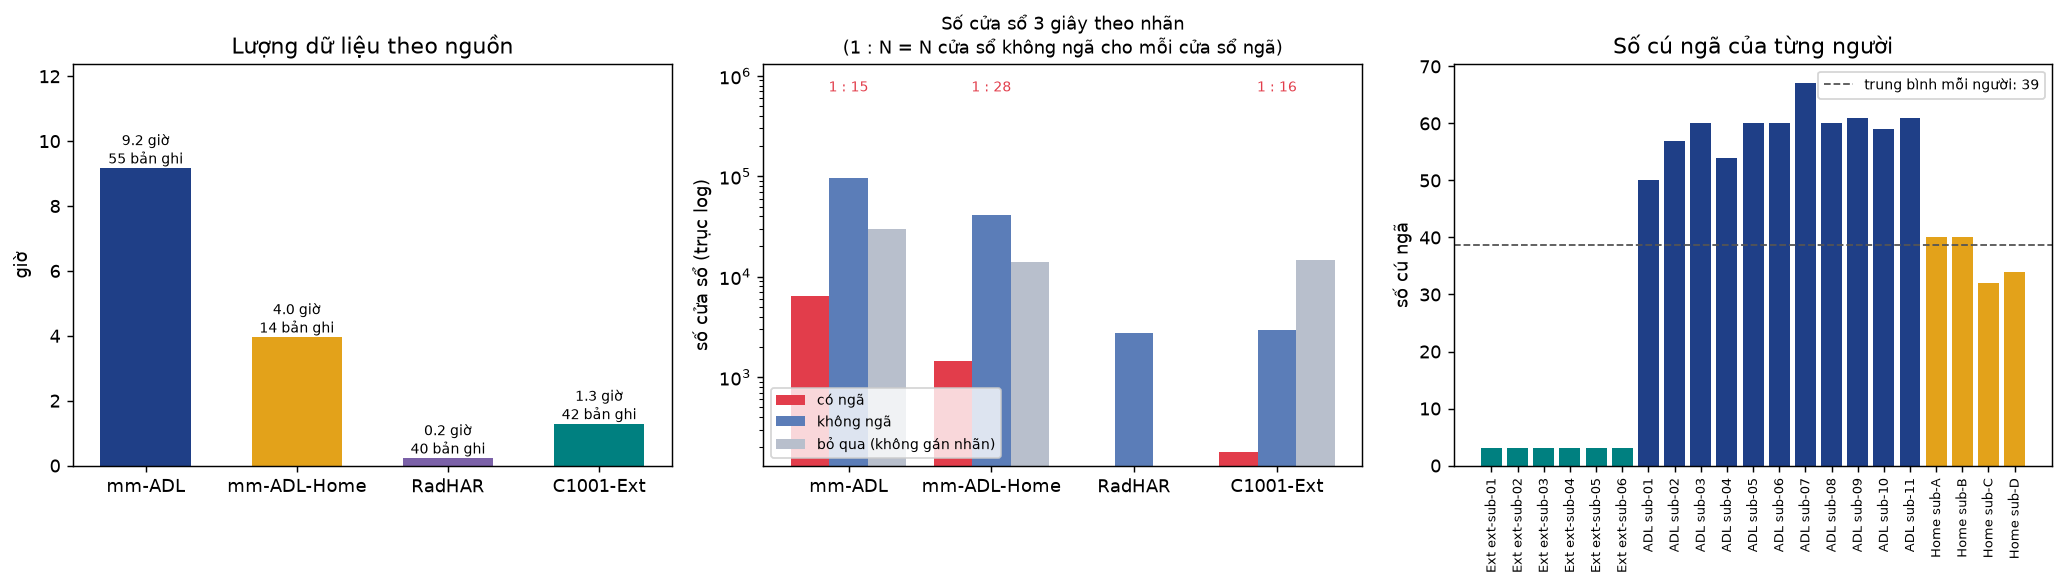

In [8]:
def eda_tong_quan():
    rows = []
    for s in EDA_SEQS:
        if s["domain"] == "own":
            nga = int(bool(s["trial"].get("expectFall")))
            nguoi = s["trial"].get("sessionId") or s["group"]
        else:
            nga = len(eda_cuoi_doan(s["raw"]["labs"], "Falling"))
            nguoi = None if s["domain"] == "radhar" else s["group"]
        rows.append(dict(nguon=s["domain"], nguoi=nguoi, gio=len(s["seq"]) * PERIOD_S / 3600, cu_nga=nga,
                         cs_co_nga=int((s["y"] == 1).sum()), cs_khong_nga=int((s["y"] == 0).sum()),
                         cs_bo_qua=int((s["y"] == -1).sum())))
    if not rows:
        print("Chua co du lieu nao -> bo qua 6a.")
        return None
    df = pd.DataFrame(rows)
    tab = (df.groupby("nguon", sort=False)
             .agg(ban_ghi=("gio", "size"), nguoi_hoac_phien=("nguoi", "nunique"), gio=("gio", "sum"),
                  cu_nga=("cu_nga", "sum"), cs_co_nga=("cs_co_nga", "sum"),
                  cs_khong_nga=("cs_khong_nga", "sum"), cs_bo_qua=("cs_bo_qua", "sum"))
             .reindex([d for d in EDA_NGUON if d in set(df["nguon"])]))
    # RadHAR không ghi ai làm động tác; cộng số người của các nguồn khác nhau cũng không có nghĩa
    tab["nguoi_hoac_phien"] = tab["nguoi_hoac_phien"].astype(float).where(tab.index != "radhar")
    tong = tab.sum(numeric_only=True)
    tong["nguoi_hoac_phien"] = np.nan
    tab = pd.concat([tab, tong.to_frame("TONG").T])
    for c in ("ban_ghi", "cu_nga", "cs_co_nga", "cs_khong_nga", "cs_bo_qua"):
        tab[c] = tab[c].astype(int)
    tab["nguoi_hoac_phien"] = tab["nguoi_hoac_phien"].astype("Int64")
    tab["gio"] = tab["gio"].round(2)
    tab["khong_nga_tren_1_nga"] = (tab["cs_khong_nga"] / tab["cs_co_nga"].where(tab["cs_co_nga"] > 0)).round(1)
    print("Tong quan (nguoi_hoac_phien: so nguoi voi du lieu cong khai, so phien do voi du lieu tu do):")
    print(tab.to_string())
    tab.to_csv(OUT_DIR / "eda_tong_quan.csv", index_label="nguon")
    if not HAS_PLT:
        return None

    doms = [d for d in tab.index if d != "TONG"]
    x = np.arange(len(doms))
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), squeeze=False)

    ax = axs[0, 0]
    gio = tab.loc[doms, "gio"].to_numpy(float)
    ax.bar(x, gio, width=0.6, color=[EDA_MAU_NGUON[d] for d in doms])
    for i, d in enumerate(doms):
        ax.text(i, gio[i], f"{gio[i]:.1f} giờ\n{tab.loc[d, 'ban_ghi']} bản ghi", ha="center", va="bottom",
                fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels([EDA_TEN_NGUON[d] for d in doms])
    ax.set_ylim(0, max(float(gio.max()), 0.01) * 1.35)
    ax.set_ylabel("giờ")
    ax.set_title("Lượng dữ liệu theo nguồn")

    ax = axs[0, 1]
    w = 0.27
    for k, (col, ten, mau) in enumerate((("cs_co_nga", "có ngã", EDA_MAU_NGA),
                                         ("cs_khong_nga", "không ngã", EDA_MAU_KHONG_NGA),
                                         ("cs_bo_qua", "bỏ qua (không gán nhãn)", EDA_MAU_BO_QUA))):
        v = tab.loc[doms, col].to_numpy(float)
        if (v > 0).any():
            ax.bar(x[v > 0] + (k - 1) * w, v[v > 0], w, color=mau, label=ten)
    ax.set_yscale("log")
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi * 10)          # chừa chỗ cho dòng tỉ lệ ở trên cùng
    for i, d in enumerate(doms):
        r = tab.loc[d, "khong_nga_tren_1_nga"]
        if pd.notna(r):
            ax.text(i, 0.96, f"1 : {r:.0f}", transform=ax.get_xaxis_transform(), ha="center", va="top",
                    fontsize=8, color=EDA_MAU_NGA)
    ax.set_xticks(x)
    ax.set_xticklabels([EDA_TEN_NGUON[d] for d in doms])
    ax.set_ylabel("số cửa sổ (trục log)")
    ax.set_title("Số cửa sổ 3 giây theo nhãn\n(1 : N = N cửa sổ không ngã cho mỗi cửa sổ ngã)", fontsize=10)
    ax.legend(fontsize=8, loc="lower left")

    ax = axs[0, 2]
    lab, val, mau = [], [], []
    per = df[df["nguon"].isin(["mm-adl", "mm-adl-home", "c1001-ext"])].groupby(["nguon", "nguoi"])["cu_nga"].sum()
    for (n, g), v in per.items():
        _pref = "ADL " if n == "mm-adl" else ("Home " if n == "mm-adl-home" else "Ext ")
        lab.append(_pref + str(g)[len(n) + 1:])
        val.append(int(v))
        mau.append(EDA_MAU_NGUON[n])
    if (df["nguon"] == "own").any():
        lab.append("Tự đo (mọi phiên)")
        val.append(int(df.loc[df["nguon"] == "own", "cu_nga"].sum()))
        mau.append(EDA_MAU_NGUON["own"])
    if val:
        ax.bar(np.arange(len(val)), val, color=mau)
        if len(per):                    # trung bình chỉ tính trên cột từng người, không tính cột tự đo (tổng)
            tb = float(np.mean(val[:len(per)]))
            ax.axhline(tb, color="#555555", lw=1, ls="--", label=f"trung bình mỗi người: {tb:.0f}")
            ax.legend(fontsize=8)
        ax.set_xticks(np.arange(len(val)))
        ax.set_xticklabels(lab, rotation=90, fontsize=7)
    else:
        ax.text(0.5, 0.5, "Chưa có nhãn ngã", ha="center", va="center", transform=ax.transAxes)
    ax.set_ylabel("số cú ngã")
    ax.set_title("Số cú ngã của từng người")
    fig.tight_layout()
    return fig


eda_chay("eda_01_tong_quan.png", eda_tong_quan)

### 6b. Mỗi hoạt động chiếm bao nhiêu thời gian
Tổng thời lượng từng nhãn của mm-ADL / mm-ADL-Home (với RadHAR là từng hoạt động). Pha **NGÃ** rất
ngắn (thời lượng từng lần xem ở mục 6e) nên chiếm rất ít thời gian so với sinh hoạt thường. Các cột vàng
(ngồi) và xanh đậm (giường) là những động tác **dễ nhầm** với ngã. Cột xám là đoạn không dùng để học
(`DELETE`, `START`, quỳ gối…).

So phut moi nhan / hoat dong:
nguon                         c1001-ext  mm-adl  mm-adl-home  radhar
nhan                                                                
(khong nhan)                        0.0    35.6         14.7     0.0
Bed-END                             0.0     0.0          4.9     0.0
Bed-START                           0.0     0.0          0.9     0.0
Chair-END                           0.0     0.0          6.2     0.0
Chair-START                         0.0     0.0          1.9     0.0
Falling                             0.4    13.7          3.3     0.0
Kneeling-Stationary                 0.0     0.5          0.0     0.0
LayBed-Stationary                   2.6    42.9         21.8     0.0
LayFloor-Stationary                61.8    35.2         12.6     0.0
START                               0.0     0.0          0.3     0.0
Sit-Stationary                      2.6    40.4         40.0     0.0
Transition-Kneeling-to-Stand        0.0     0.2          0.0     0.0
Tran

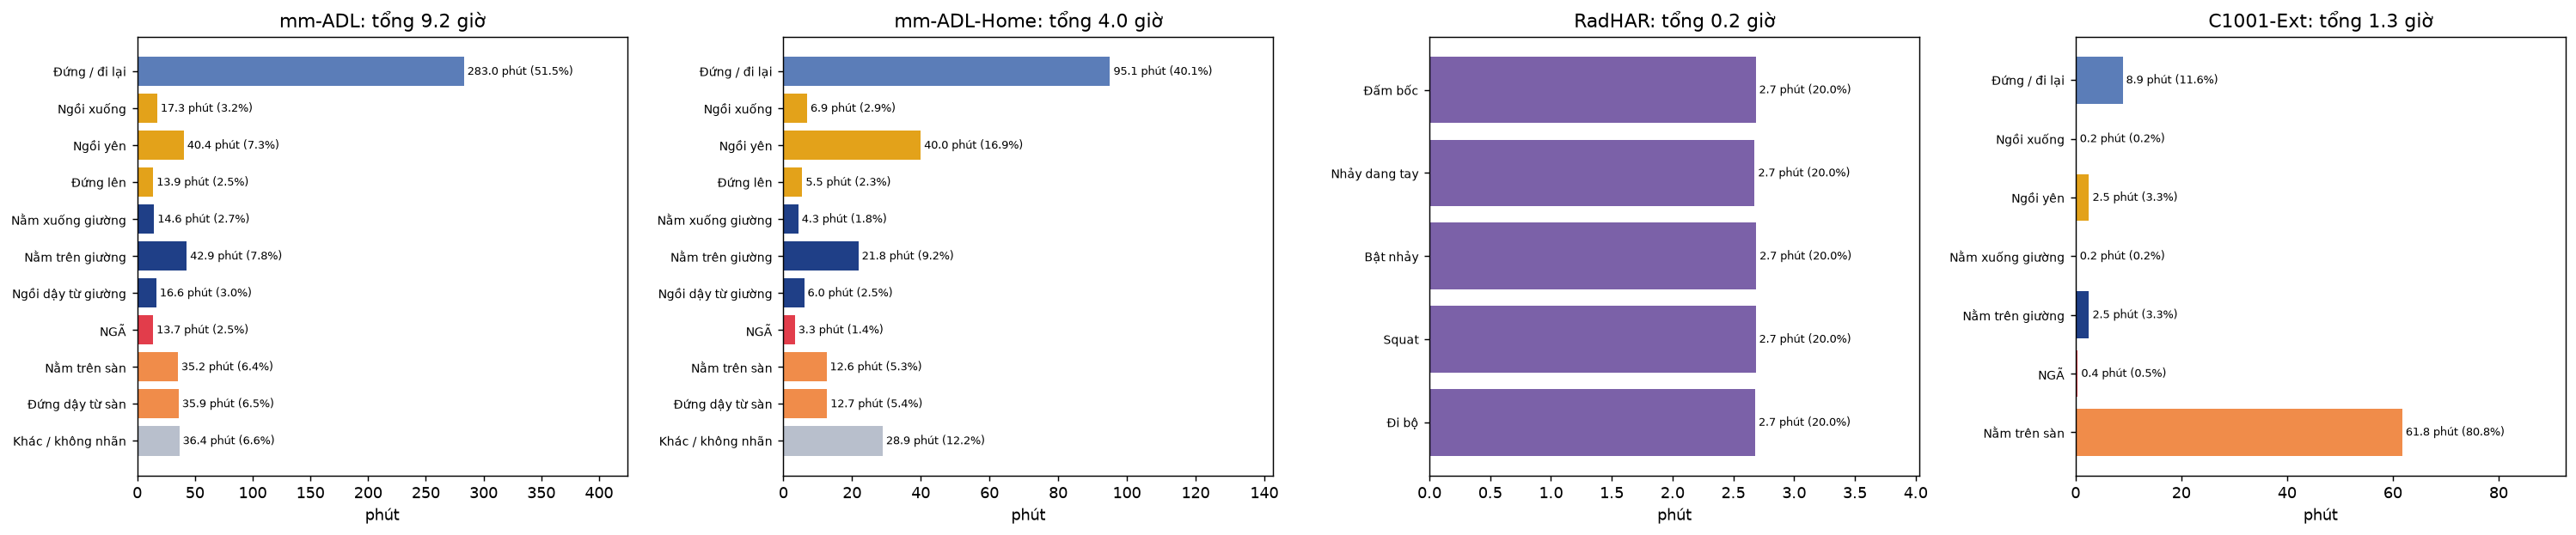

In [9]:
def eda_thoi_luong():
    rows = []
    for s in PUB_SEQS:
        if s["domain"] == "radhar":
            rows.append(dict(nguon="radhar", nhan=s["protocol"], phut=len(s["seq"]) * PERIOD_S / 60))
            continue
        vc = pd.Series(s["raw"]["labs"], dtype=object).fillna("(khong nhan)").value_counts()
        rows += [dict(nguon=s["domain"], nhan=str(k), phut=v * PERIOD_S / 60) for k, v in vc.items()]
    if not rows:
        print("Chua co du lieu cong khai -> bo qua 6b.")
        return None
    bang = pd.DataFrame(rows).groupby(["nhan", "nguon"])["phut"].sum().unstack("nguon").fillna(0.0)
    print("So phut moi nhan / hoat dong:")
    print(bang.round(1).to_string())
    for d in bang.columns:
        if "Falling" in bang.index and bang[d].sum() > 0:
            print(f"  {d}: nhan Falling chiem {bang.loc['Falling', d] / bang[d].sum() * 100:.2f}% thoi gian")
    if not HAS_PLT:
        return None
    doms = [d for d in EDA_NGUON if d in bang.columns]
    fig, axs = plt.subplots(1, len(doms), figsize=(5.8 * len(doms), 4.9), squeeze=False)
    for c, d in enumerate(doms):
        ax = axs[0, c]
        col = bang[d][bang[d] > 0]
        if d == "radhar":
            items = [(EDA_RADHAR.get(k, k), float(v), EDA_MAU_NGUON["radhar"]) for k, v in col.items()]
        else:
            items = [(EDA_HOAT_DONG[k][0], float(col[k]), EDA_NHOM[EDA_HOAT_DONG[k][1]][1])
                     for k in EDA_HOAT_DONG if k in col.index]
            khac = float(col[[k for k in col.index if k not in EDA_HOAT_DONG]].sum())
            if khac > 0:
                items.append(("Khác / không nhãn", khac, EDA_NHOM["khac"][1]))
        if not items:
            ax.set_axis_off()
            continue
        tong = sum(v for _, v, _ in items)
        yy = np.arange(len(items))
        ax.barh(yy, [v for _, v, _ in items], color=[m for _, _, m in items])
        for i, (_, v, _) in enumerate(items):
            ax.text(v, i, f" {v:.1f} phút ({v / tong * 100:.1f}%)", va="center", fontsize=7)
        ax.set_yticks(yy)
        ax.set_yticklabels([ten for ten, _, _ in items], fontsize=8)
        ax.invert_yaxis()
        ax.set_xlim(0, max(v for _, v, _ in items) * 1.5)
        ax.set_xlabel("phút")
        ax.set_title(f"{EDA_TEN_NGUON[d]}: tổng {tong / 60:.1f} giờ")
    fig.tight_layout()
    return fig


eda_chay("eda_02_thoi_luong_hoat_dong.png", eda_thoi_luong)

### 6c. Xem thử một cú ngã sau khi chuyển đổi
Biểu đồ dưới đây nên đưa vào báo cáo để giải thích đặc trưng: lúc ngã biên độ vọt lên rồi tụt về gần 0,
khoảng cách tới radar trần tăng (người từ đứng chuyển sang nằm sát sàn).

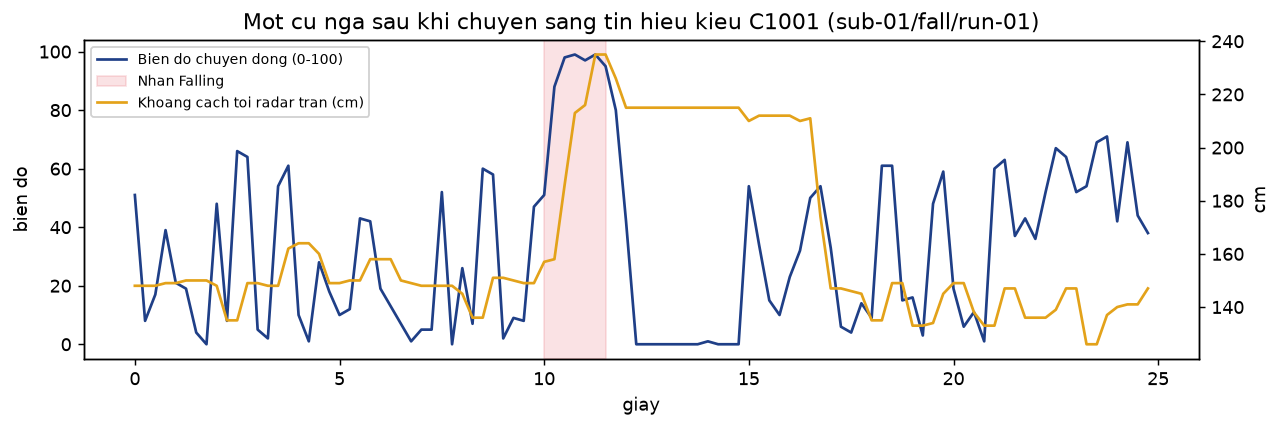

In [10]:
def plot_example():
    cand = [s for s in PUB_SEQS if s["protocol"] == "fall"] or OWN_SEQS
    # bản ghi đầu tiên thật sự có nhãn Falling (dữ liệu tự đo không có nhãn từng khung)
    s = next((c for c in cand if "raw" not in c or any(l == "Falling" for l in c["raw"]["labs"])), None)
    if not (HAS_PLT and s is not None):
        return None
    if "raw" in s:
        labs = s["raw"]["labs"]
        i0 = next(i for i, l in enumerate(labs) if l == "Falling")
        lo, hi = max(0, i0 - 40), min(len(labs), i0 + 60)
        shade = [k - lo for k in range(lo, hi) if labs[k] == "Falling"]
    else:
        lo, hi, shade = 0, len(s["seq"]), []
    seq = s["seq"][lo:hi]
    t = np.arange(len(seq)) * PERIOD_S
    fig, ax = plt.subplots(figsize=(10, 3.4))
    ax.plot(t, seq[:, 2], color="#1f3f87", label="Bien do chuyen dong (0-100)")
    ax2 = ax.twinx()
    ax2.plot(t, seq[:, 4], color="#e3a21a", label="Khoang cach toi radar tran (cm)")
    if shade:
        ax.axvspan(shade[0] * PERIOD_S, (shade[-1] + 1) * PERIOD_S, color="#e23d4b", alpha=0.15, label="Nhan Falling")
    ax.set_xlabel("giay"); ax.set_ylabel("bien do"); ax2.set_ylabel("cm")
    ax.set_title(f"Mot cu nga sau khi chuyen sang tin hieu kieu C1001 ({s['name']})")
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8, framealpha=0.9)
    fig.tight_layout()
    return fig


eda_chay("vi_du_cu_nga.png", plot_example)

### 6d. Ngã và hai ca dễ nhầm, đặt cạnh nhau
Ba đoạn ±12 giây lấy từ dữ liệu đã chuyển đổi; mốc 0 là lúc **kết thúc** động tác (chạm sàn / ngồi
xong / nằm xong), nền tô theo nhãn của bộ dữ liệu.
- Hàng 1 là **độ cao tâm người** lấy từ point cloud. C1001 **không** cho con số này; nó chỉ ở đây để
  đối chiếu: cả ba động tác đều hạ thấp người, khác nhau ở tốc độ hạ và độ cao lúc cuối.
- Hàng 2–4 là đúng những gì model trên ESP32 nhận được: biên độ, khoảng cách tới radar trần, trạng
  thái chuyển động (0 không người · 1 yên · 2 hoạt động).

  Vi du Falling: mm-adl sub-01/fall/run-01, giay thu 397 cua ban ghi
  Vi du Transition-Stand-to-Sit: mm-adl sub-01/lie/run-01, giay thu 457 cua ban ghi
  Vi du Transition-Sit-to-LayBed: mm-adl sub-01/lie/run-01, giay thu 438 cua ban ghi


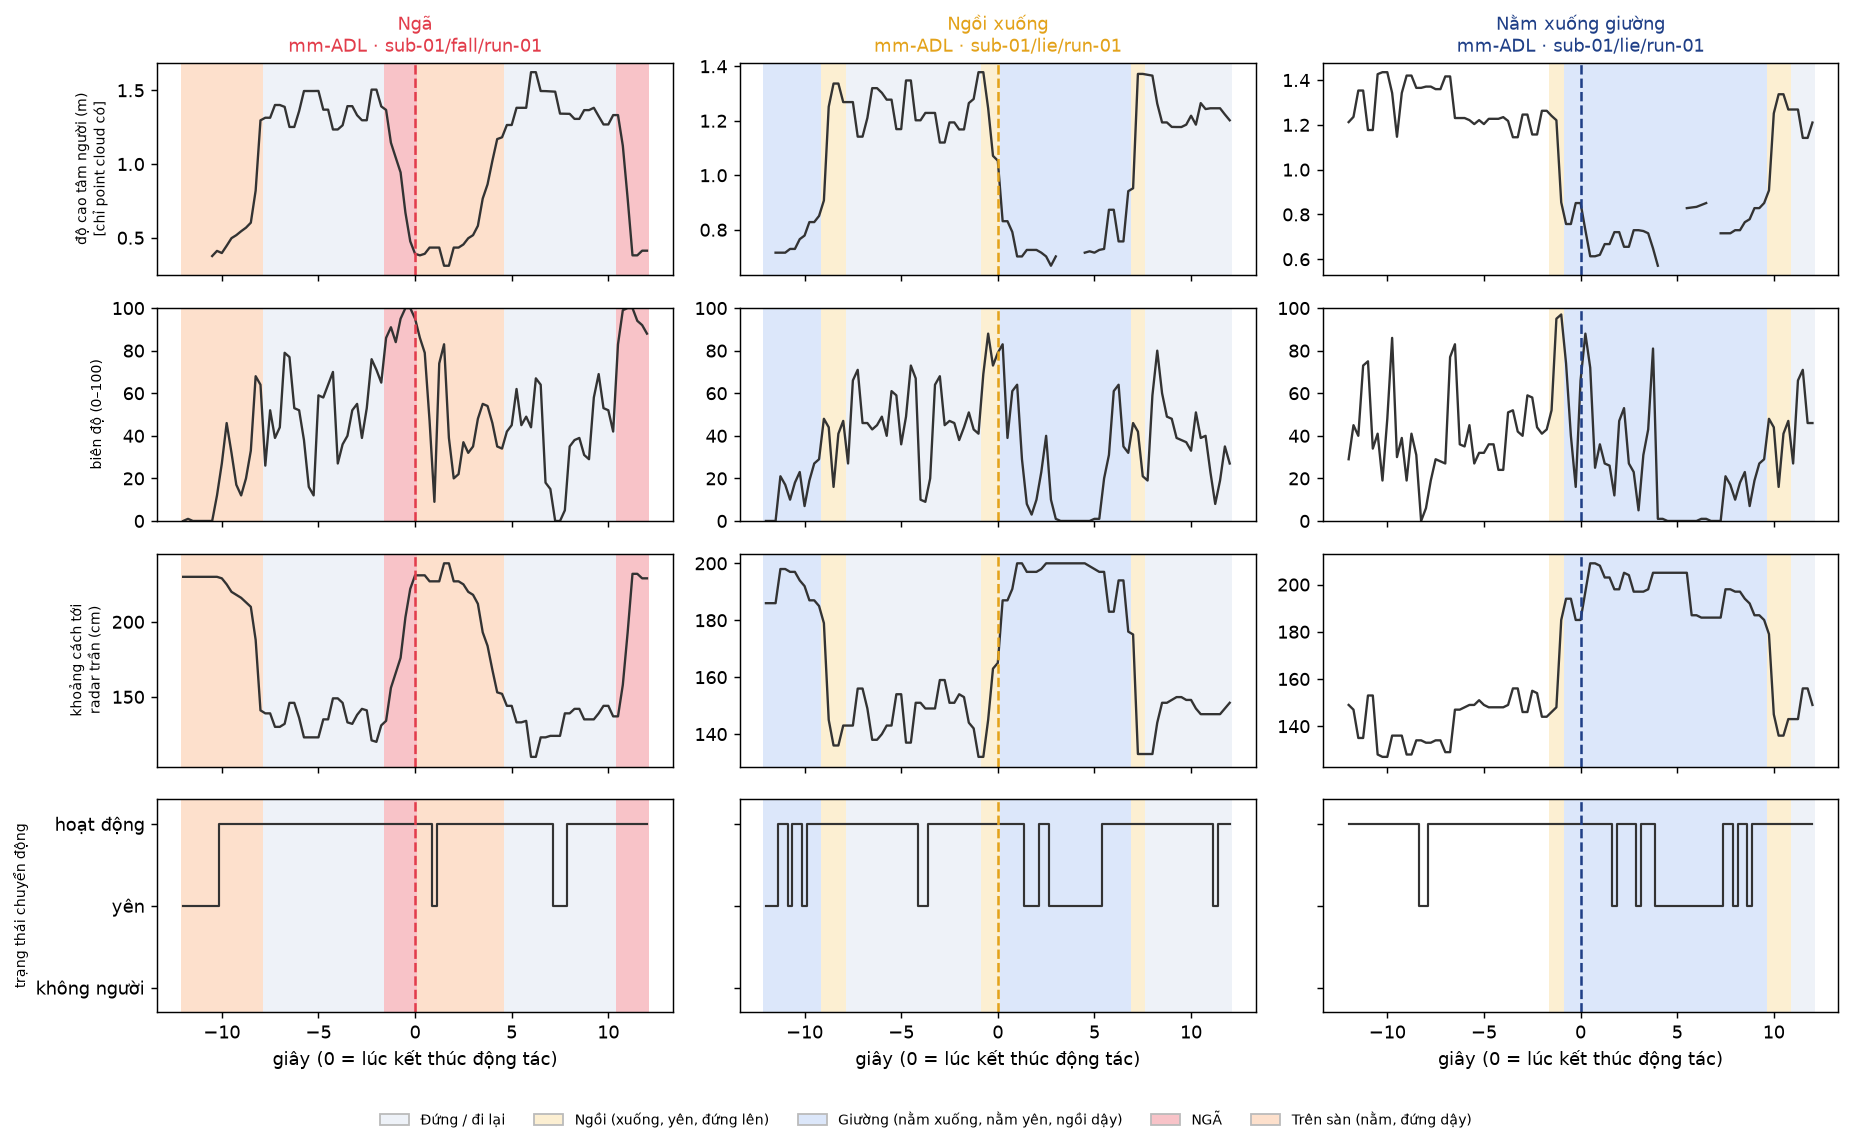

In [11]:
def eda_vi_du_ca_de_nham():
    m = int(round(12 / PERIOD_S))                  # ±12 giây quanh mốc
    uu_tien = [s for d in ("mm-adl", "mm-adl-home") for s in PUB_SEQS if s["domain"] == d]
    found = []
    for nhan, ten, mau in EDA_SU_KIEN:
        for s in uu_tien:
            ks = eda_cuoi_doan(s["raw"]["labs"], nhan)
            ks = ks[(ks >= m) & (ks + m < len(s["seq"]))]
            if len(ks):
                found.append((nhan, ten, mau, s, int(ks[len(ks) // 2])))   # lần ở giữa bản ghi
                break
    if not found:
        print("Chua co mm-ADL / mm-ADL-Home (can nhan tung khung) -> bo qua 6d.")
        return None
    for nhan, _, _, s, k in found:
        print(f"  Vi du {nhan}: {s['domain']} {s['name']}, giay thu {k * PERIOD_S:.0f} cua ban ghi")
    if not HAS_PLT:
        return None
    from matplotlib.patches import Patch
    hang = (("độ cao tâm người (m)\n[chỉ point cloud có]", lambda s, lo, hi: s["track"]["P"][lo:hi, 2]),
            ("biên độ (0–100)", lambda s, lo, hi: s["seq"][lo:hi, 2]),
            ("khoảng cách tới\nradar trần (cm)", lambda s, lo, hi: s["seq"][lo:hi, 4]),
            ("trạng thái chuyển động", lambda s, lo, hi: s["seq"][lo:hi, 1]))
    fig, axs = plt.subplots(len(hang), len(found), figsize=(4.8 * len(found), 8.8), squeeze=False, sharex=True)
    for c, (nhan, ten, mau, s, k) in enumerate(found):
        lo, hi = k - m, k + m + 1
        t = (np.arange(lo, hi) - k) * PERIOD_S
        labs = s["raw"]["labs"][lo:hi]
        for r, (ylab, lay) in enumerate(hang):
            ax = axs[r, c]
            eda_to_nen(ax, t, labs)
            v = np.asarray(lay(s, lo, hi), float)
            if r == len(hang) - 1:
                ax.step(t, v, where="mid", color="#333333", lw=1.2)
                ax.set_ylim(-0.3, 2.3)
                ax.set_yticks([0, 1, 2])
                if c == 0:
                    ax.set_yticklabels(["không người", "yên", "hoạt động"])
                else:
                    ax.tick_params(labelleft=False)
            else:
                ax.plot(t, v, color="#333333", lw=1.3)
            if r == 1:
                ax.set_ylim(0, 100)
            ax.axvline(0, color=mau, lw=1.4, ls="--")
            if c == 0:
                ax.set_ylabel(ylab, fontsize=8)
        axs[0, c].set_title(f"{ten}\n{EDA_TEN_NGUON[s['domain']]} · {s['name']}", fontsize=10, color=mau)
        axs[-1, c].set_xlabel("giây (0 = lúc kết thúc động tác)")
    fig.legend(handles=[Patch(facecolor=EDA_NHOM[g][0], edgecolor="#bbbbbb", label=EDA_NHOM[g][2])
                        for g in ("di", "ngoi", "giuong", "nga", "san")],
               loc="lower center", ncol=5, fontsize=8, frameon=False)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    return fig


eda_chay("eda_03_nga_va_ca_de_nham.png", eda_vi_du_ca_de_nham)

### 6e. Chữ ký trung bình của từng động tác — cửa sổ 3 giây có đủ dài không?
Gom **mọi** lần ngã / ngồi xuống / nằm xuống giường của mm-ADL và mm-ADL-Home, đặt thẳng hàng tại mốc 0
(lúc kết thúc động tác) rồi lấy trung vị; vùng tô là khoảng 25–75% giữa các lần. Vùng xám là **cửa sổ 3
giây** model thấy khi cửa sổ kết thúc đúng lúc chạm sàn; đường chấm đỏ là lúc chip C1001 tự xác nhận ngã
(`RADAR_FALL_TIME_S`, 5 giây sau).

Đọc cho bước tiếp theo: chỗ nào ba đường **tách nhau** thì chỗ đó có thông tin phân biệt. Nếu chúng còn
tách nhau ở **ngoài** vùng xám (trước −3 s hoặc sau 0 s), một model nhìn được **cửa sổ dài hơn** (ví dụ
mạng chuỗi thời gian chạy trên chuỗi tín hiệu thô) có thêm thông tin mà bộ 10 đặc trưng 3 giây đang bỏ
lỡ. Bảng in ra tóm tắt bằng số: biên độ đỉnh, khoảng cách và độ cao thay đổi bao nhiêu sau động tác.

Tom tat quanh moc ket thuc dong tac (trung vi qua cac lan; 'doi' = sau [3..6 s] tru truoc [-6..-3 s]):
                 su_kien  so_lan  thoi_luong_trung_vi_s  bien_do_dinh  doi_khoang_cach_cm  doi_do_cao_m
                 Falling     795                   1.25         100.0                63.0         -0.58
 Transition-Stand-to-Sit    1631                   0.75          87.0                28.0         -0.27
Transition-Sit-to-LayBed     770                   1.50          92.0                42.0         -0.43


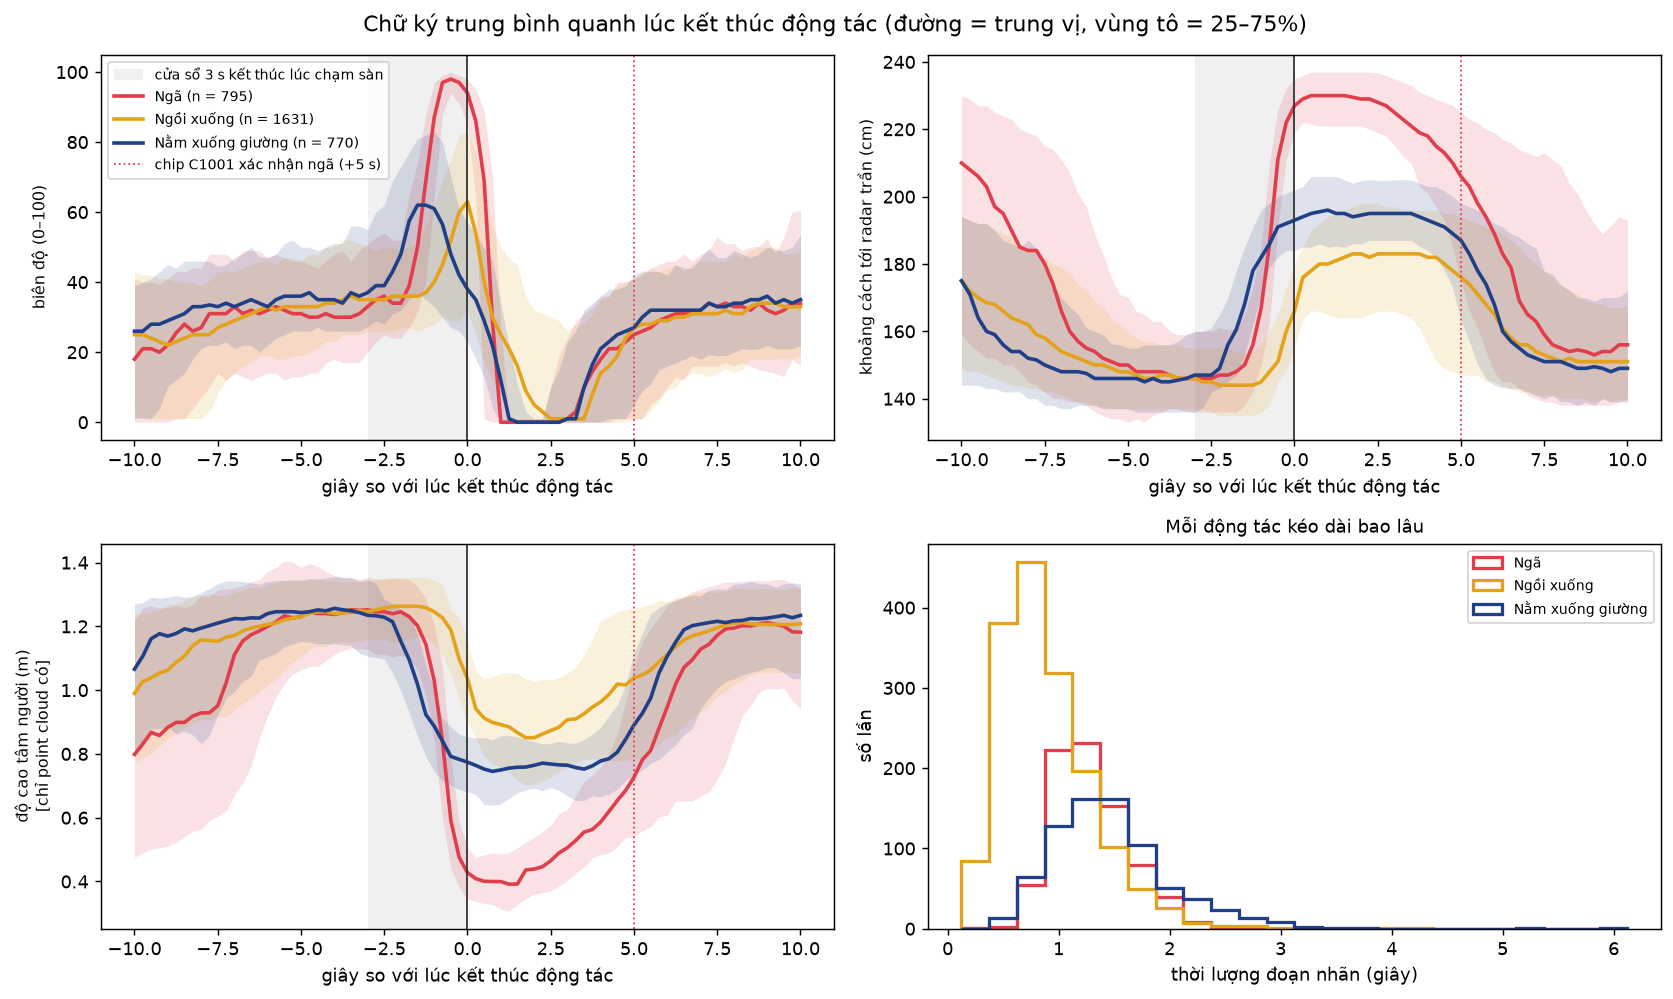

In [12]:
def eda_gom_su_kien(m):
    """Cắt ±m mẫu quanh mốc cuối của mọi lần mỗi động tác -> {nhãn: dict(A, D, H, L, ten, mau)}."""
    out = {}
    for nhan, ten, mau in EDA_SU_KIEN:
        A, D, H, L = [], [], [], []
        for s in PUB_SEQS:
            if s["domain"] not in ("mm-adl", "mm-adl-home"):
                continue
            labs = s["raw"]["labs"]
            ks = eda_cuoi_doan(labs, nhan)
            if not len(ks):
                continue
            mk = eda_mask(labs, nhan)
            amp, dist = s["seq"][:, 2].astype(float), s["seq"][:, 4].astype(float)
            h = s["track"]["P"][:, 2]
            for k in ks:
                A.append(eda_cat(amp, k, m))
                D.append(eda_cat(dist, k, m))
                H.append(eda_cat(h, k, m))
                j = k
                while j > 0 and mk[j - 1]:          # lùi về đầu đoạn để đo thời lượng
                    j -= 1
                L.append((k - j + 1) * PERIOD_S)
        if L:
            out[nhan] = dict(ten=ten, mau=mau, A=np.array(A), D=np.array(D), H=np.array(H), L=np.array(L))
    return out


def eda_chu_ky():
    m = int(round(10 / PERIOD_S))                  # ±10 giây quanh mốc
    ev = eda_gom_su_kien(m)
    if not ev:
        print("Chua co mm-ADL / mm-ADL-Home (can nhan tung khung) -> bo qua 6e.")
        return None
    t = np.arange(-m, m + 1) * PERIOD_S
    truoc, sau, dinh = (t >= -6) & (t <= -3), (t >= 3) & (t <= 6), (t >= -3) & (t <= 1)
    rows = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)       # cột toàn NaN ở mép bản ghi
        for nhan, e in ev.items():
            rows.append(dict(
                su_kien=nhan, so_lan=len(e["L"]), thoi_luong_trung_vi_s=float(np.median(e["L"])),
                bien_do_dinh=float(np.nanmedian(np.nanmax(e["A"][:, dinh], axis=1))),
                doi_khoang_cach_cm=float(np.nanmedian(np.nanmedian(e["D"][:, sau], axis=1)
                                                      - np.nanmedian(e["D"][:, truoc], axis=1))),
                doi_do_cao_m=float(np.nanmedian(np.nanmedian(e["H"][:, sau], axis=1)
                                                - np.nanmedian(e["H"][:, truoc], axis=1)))))
            e["Q"] = {k: np.nanpercentile(e[k], [25, 50, 75], axis=0) for k in ("A", "D", "H")}
    tab = pd.DataFrame(rows)
    print("Tom tat quanh moc ket thuc dong tac (trung vi qua cac lan; 'doi' = sau [3..6 s] tru truoc [-6..-3 s]):")
    print(tab.round(2).to_string(index=False))
    tab.to_csv(OUT_DIR / "eda_chu_ky_su_kien.csv", index=False)
    if not HAS_PLT:
        return None
    fig, axs = plt.subplots(2, 2, figsize=(13, 7.8), squeeze=False)
    ve = (("A", "biên độ (0–100)"), ("D", "khoảng cách tới radar trần (cm)"),
          ("H", "độ cao tâm người (m)\n[chỉ point cloud có]"))
    for ax, (k, ylab) in zip((axs[0, 0], axs[0, 1], axs[1, 0]), ve):
        ax.axvspan(-WINDOW_SIZE * PERIOD_S, 0, color="#888888", alpha=0.12, lw=0,
                   label="cửa sổ 3 s kết thúc lúc chạm sàn")
        for e in ev.values():
            q = e["Q"][k]
            ax.fill_between(t, q[0], q[2], color=e["mau"], alpha=0.15, lw=0)
            ax.plot(t, q[1], color=e["mau"], lw=2, label=f"{e['ten']} (n = {len(e['L'])})")
        ax.axvline(0, color="#333333", lw=1)
        ax.axvline(FALL_CONFIRM_S, color=EDA_MAU_NGA, lw=1, ls=":",
                   label=f"chip C1001 xác nhận ngã (+{FALL_CONFIRM_S} s)")
        ax.set_ylabel(ylab, fontsize=9)
        ax.set_xlabel("giây so với lúc kết thúc động tác")
    axs[0, 0].legend(fontsize=8, loc="upper left")
    ax = axs[1, 1]
    for e in ev.values():
        # thời lượng là bội của 250 ms nên đặt mép cột lệch nửa nhịp cho mỗi cột nằm đúng một giá trị
        ax.hist(np.clip(e["L"], 0, 6), bins=np.arange(PERIOD_S / 2, 6 + PERIOD_S, PERIOD_S), histtype="step",
                lw=1.8, color=e["mau"], label=e["ten"])
    ax.set_xlabel("thời lượng đoạn nhãn (giây)")
    ax.set_ylabel("số lần")
    ax.set_title("Mỗi động tác kéo dài bao lâu", fontsize=10)
    ax.legend(fontsize=8)
    fig.suptitle("Chữ ký trung bình quanh lúc kết thúc động tác (đường = trung vị, vùng tô = 25–75%)",
                 fontsize=12)
    fig.tight_layout()
    return fig


eda_chay("eda_04_chu_ky_su_kien.png", eda_chu_ky)

### 6f. 10 đặc trưng: tách được ngã tới đâu, có trùng thông tin không
Mỗi ô là phân bố một đặc trưng ở cửa sổ **có ngã** (đỏ) và **không ngã** (xanh); mỗi lớp được chuẩn hóa
về cùng diện tích nên so được hình dạng dù số lượng chênh nhau rất xa. **AUC** trên mỗi ô là điểm của
riêng đặc trưng đó khi dùng một mình: 0,5 là không phân biệt được gì, càng xa 0,5 (về 1 hay về 0) càng
tách tốt. Hai lớp càng chồng lên nhau thì model càng phải dựa vào **tổ hợp** nhiều đặc trưng — đó là
chỗ MLP (mục 11) hơn hồi quy logistic.

Hình thứ hai là ma trận tương quan: cặp đặc trưng có |r| gần 1 mang gần như cùng một thông tin.

Moi dac trung DUNG MOT MINH tach nga toi dau (do_tach: 0 = vo dung, 1 = tach hoan toan):
dac_trung                      ten  tb_khong_nga  tb_co_nga   auc  do_tach        chieu
       f1         Bien do lon nhat         0.634      0.981 0.977    0.955  nga cao hon
       f5   Khoang cach cuoi - dau         0.002      0.355 0.958    0.916  nga cao hon
       f0       Trung binh bien do         0.306      0.601 0.931    0.863  nga cao hon
       f2    Do lech chuan bien do         0.350      0.670 0.923    0.846  nga cao hon
       f4   Trung binh khoang cach         0.396      0.488 0.856    0.712  nga cao hon
       f9     Ti le mau nam im lau         0.011      0.101 0.681    0.362  nga cao hon
       f6     Khoang cach nho nhat         0.363      0.382 0.603    0.205  nga cao hon
       f3       Bien do cuoi - dau         0.001     -0.135 0.425    0.150 nga thap hon
       f8 Ti le mau dang hoat dong         0.725      0.819 0.552    0.105  nga cao hon
       f7       Ti le mau co ng

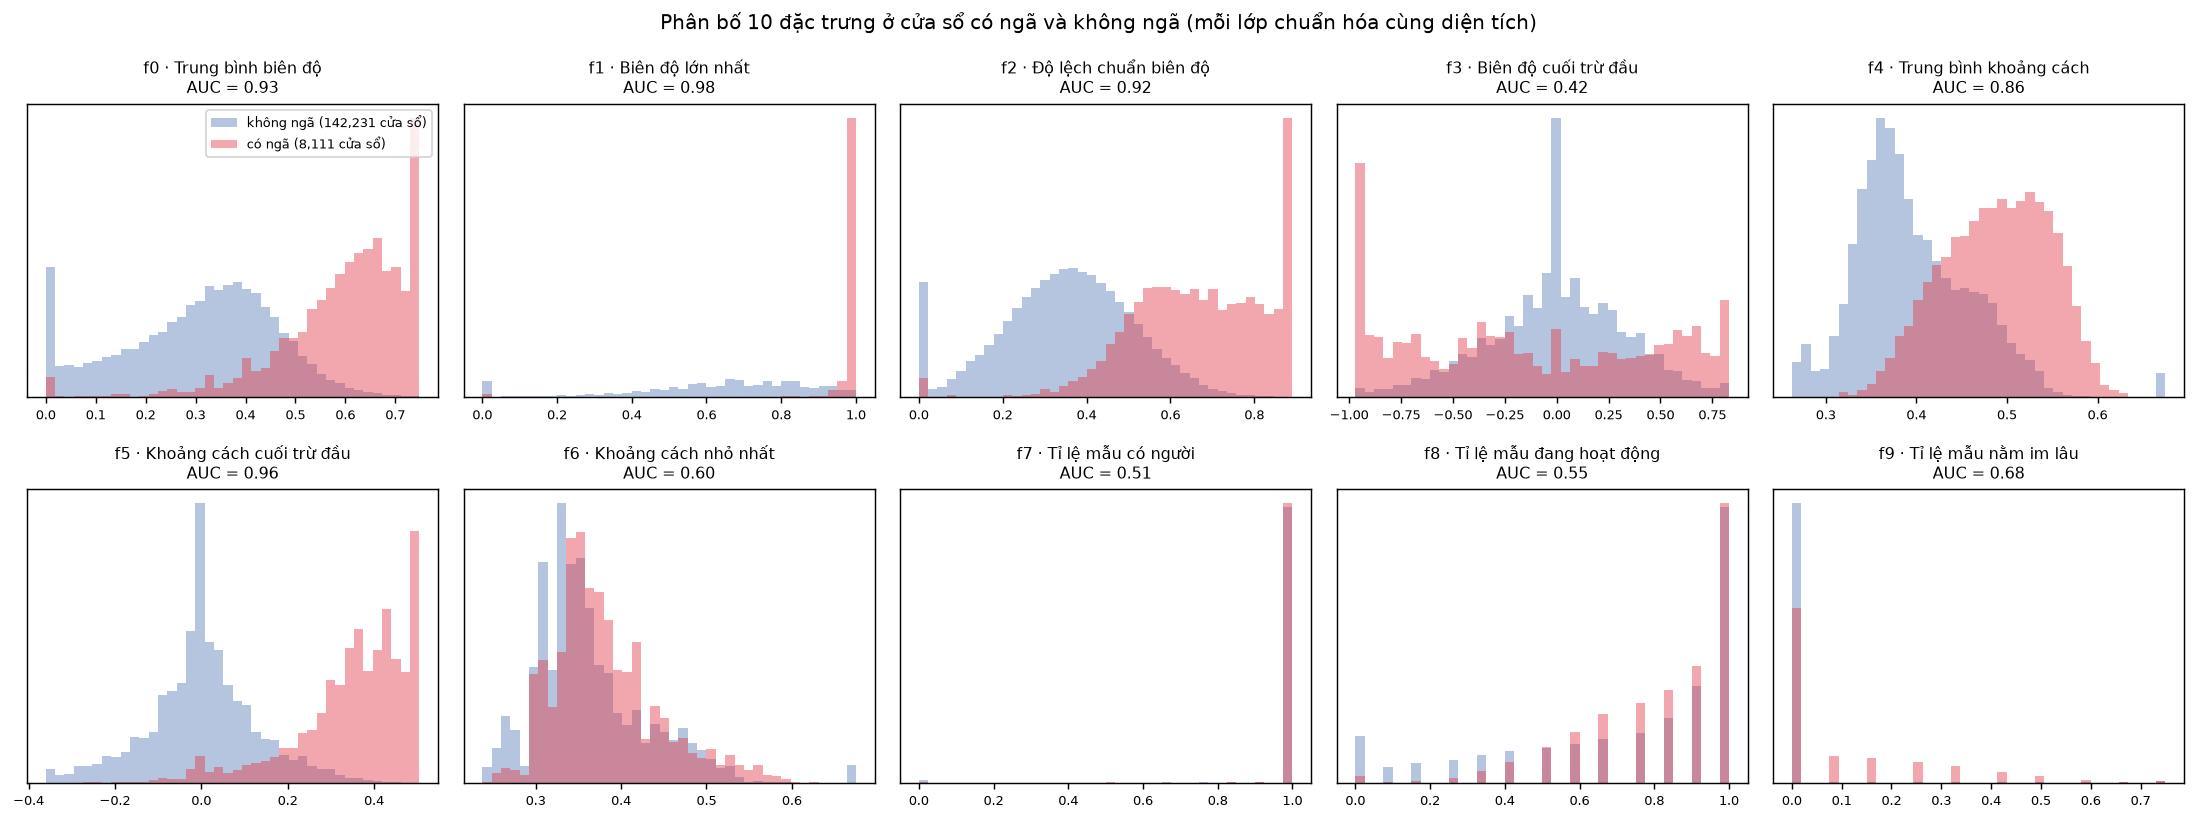

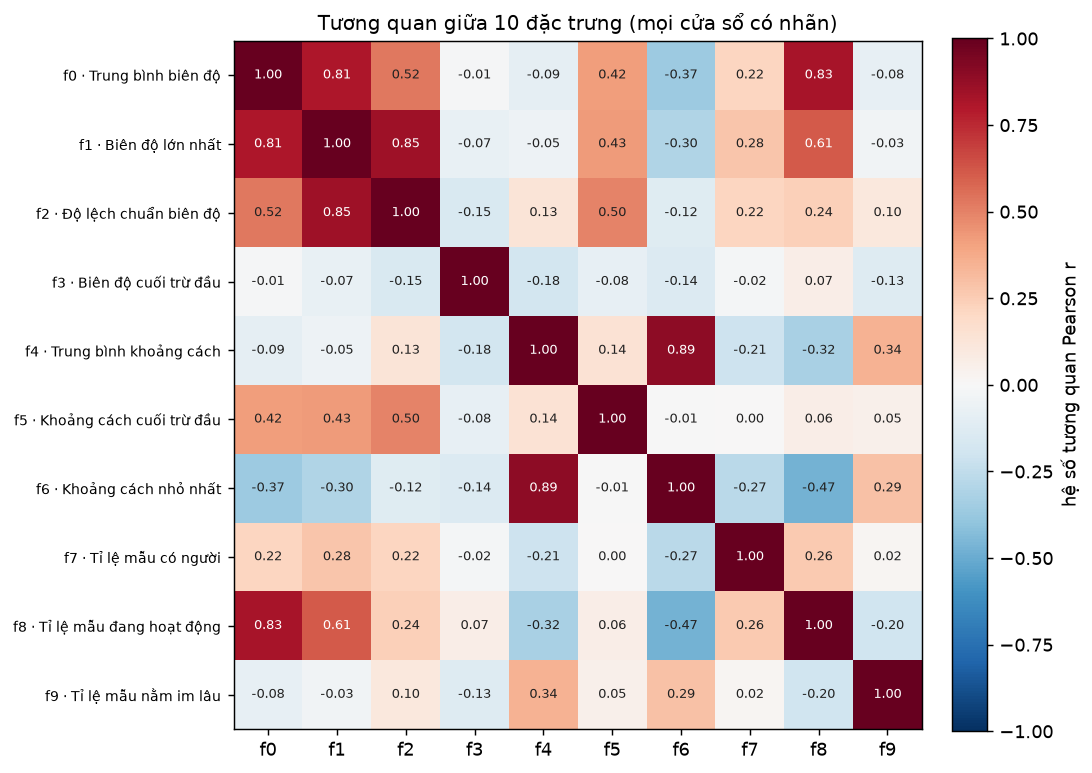

In [13]:
def eda_phan_bo_dac_trung():
    data = eda_cua_so()
    if data is None:
        print("Chua co cua so co nhan -> bo qua 6f.")
        return None
    Xw, yw, _, _ = data
    hai_lop = 0 < int(yw.sum()) < len(yw)
    rows = []
    for j in range(Xw.shape[1]):
        auc = float(roc_auc_score(yw, Xw[:, j])) if hai_lop else float("nan")
        rows.append(dict(dac_trung=f"f{j}", ten=FEATURE_NAMES[j],
                         tb_khong_nga=float(Xw[yw == 0, j].mean()) if (yw == 0).any() else float("nan"),
                         tb_co_nga=float(Xw[yw == 1, j].mean()) if (yw == 1).any() else float("nan"),
                         auc=auc, do_tach=abs(auc - 0.5) * 2,
                         chieu=("nga cao hon" if auc > 0.5 else "nga thap hon") if np.isfinite(auc) else ""))
    tab = pd.DataFrame(rows).sort_values("do_tach", ascending=False)
    print("Moi dac trung DUNG MOT MINH tach nga toi dau (do_tach: 0 = vo dung, 1 = tach hoan toan):")
    print(tab.round(3).to_string(index=False))
    tab.to_csv(OUT_DIR / "eda_do_tach_dac_trung.csv", index=False)
    if not HAS_PLT:
        return None
    fig, axs = plt.subplots(2, 5, figsize=(17, 6.4), squeeze=False)
    for j in range(Xw.shape[1]):
        ax = axs[j // 5, j % 5]
        v = Xw[:, j]
        lo, hi = np.percentile(v, [0.5, 99.5])
        if hi - lo < 1e-9:              # gần như hằng số (vd f9 hiếm khi khác 0): dùng cả dải thật
            lo, hi = float(v.min()), float(v.max())
        if hi - lo < 1e-9:
            lo, hi = lo - 0.5, hi + 0.5
        for lab, mau, ten in ((0, EDA_MAU_KHONG_NGA, "không ngã"), (1, EDA_MAU_NGA, "có ngã")):
            vv = np.clip(v[yw == lab], lo, hi)
            if len(vv):
                ax.hist(vv, bins=np.linspace(lo, hi, 41), density=True, histtype="stepfilled", alpha=0.45,
                        color=mau, label=f"{ten} ({len(vv):,} cửa sổ)")
        auc = rows[j]["auc"]
        ax.set_title(f"f{j} · {EDA_TEN_DAC_TRUNG[j]}" + (f"\nAUC = {auc:.2f}" if np.isfinite(auc) else ""),
                     fontsize=9)
        ax.tick_params(labelsize=7)
        ax.set_yticks([])
    axs[0, 0].legend(fontsize=7, loc="upper right")
    fig.suptitle("Phân bố 10 đặc trưng ở cửa sổ có ngã và không ngã (mỗi lớp chuẩn hóa cùng diện tích)",
                 fontsize=11)
    fig.tight_layout()
    return fig


def eda_tuong_quan():
    data = eda_cua_so()
    if data is None:
        return None
    Xw = data[0]
    with np.errstate(invalid="ignore", divide="ignore"):
        C = np.nan_to_num(np.corrcoef(Xw, rowvar=False))        # đặc trưng hằng số -> 0
    n = C.shape[0]
    cap = sorted(((abs(C[i, j]), i, j) for i in range(n) for j in range(i + 1, n)), reverse=True)[:5]
    print("5 cap dac trung tuong quan manh nhat (|r| gan 1 = gan nhu cung mot thong tin):")
    for _, i, j in cap:
        print(f"  f{i} ~ f{j}: r = {C[i, j]:+.2f}   ({FEATURE_NAMES[i]} / {FEATURE_NAMES[j]})")
    if not HAS_PLT:
        return None
    fig, ax = plt.subplots(figsize=(8, 6.6))
    im = ax.imshow(C, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(n))
    ax.set_xticklabels([f"f{j}" for j in range(n)])
    ax.set_yticks(range(n))
    ax.set_yticklabels([f"f{j} · {EDA_TEN_DAC_TRUNG[j]}" for j in range(n)], fontsize=8)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(C[i, j]) > 0.6 else "#222222")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="hệ số tương quan Pearson r")
    ax.set_title("Tương quan giữa 10 đặc trưng (mọi cửa sổ có nhãn)", fontsize=11)
    fig.tight_layout()
    return fig


eda_chay("eda_05_phan_bo_dac_trung.png", eda_phan_bo_dac_trung)
eda_chay("eda_06_tuong_quan_dac_trung.png", eda_tuong_quan)

### 6g. Các nguồn dữ liệu lệch nhau tới đâu (lệch miền)
Cùng năm tín hiệu nhưng mỗi nguồn quay ở phòng khác, người khác, cảm biến khác (dữ liệu công khai là
radar TI đã chuyển đổi, dữ liệu tự đo là chính C1001). Đường của các nguồn càng lệch nhau thì model học ở
nguồn này càng dễ hụt ở nguồn kia. Mục 5b (khớp thang biên độ) và mục 11a/11c (CORAL, tăng cường, bài
kiểm tra "đổi nhà") xử lý đúng chuyện này. Khi đã có dữ liệu tự đo, ô cuối vẽ thêm phép khớp thang biên
độ của mục 5b.

Moi nguon trong ra sao (ti le tinh tren moi mau; trung vi tinh tren mau co nguoi):
             so_mau  co_nguoi  hoat_dong  nam_im_lau  bien_do_trung_vi  khoang_cach_trung_vi_cm
nguon                                                                                          
mm-adl       131939     0.995      0.756       0.061              32.0                    157.0
mm-adl-home   56945     0.988      0.599       0.054              20.0                    161.0
radhar         3218     1.000      0.524       0.000              13.0                    111.0
c1001-ext     18360     0.935      0.194       0.634               1.0                    234.0


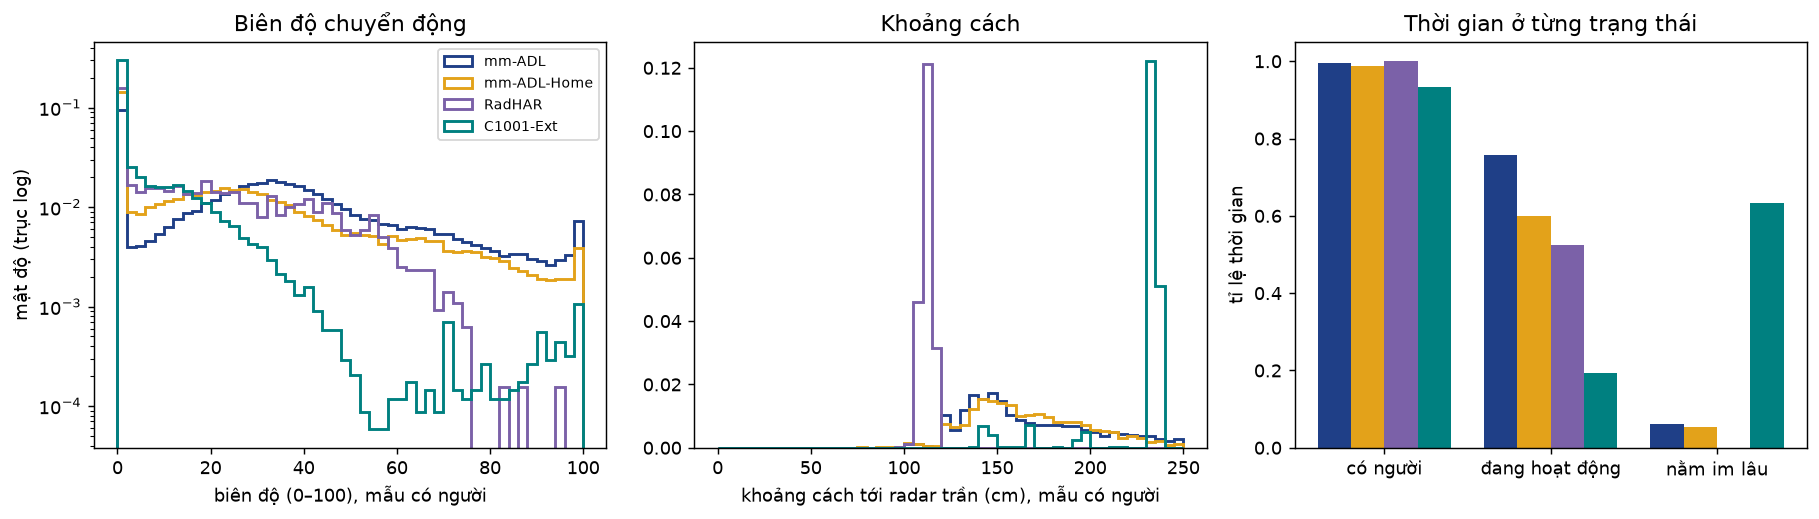

In [14]:
def eda_lech_mien():
    doms = [d for d in EDA_NGUON if any(s["domain"] == d and len(s["seq"]) for s in EDA_SEQS)]
    if not doms:
        print("Chua co du lieu -> bo qua 6g.")
        return None
    per, rows = {}, []
    for d in doms:
        S = np.vstack([s["seq"] for s in EDA_SEQS if s["domain"] == d and len(s["seq"])]).astype(float)
        co = S[:, 0] != 0
        per[d] = dict(amp=S[co, 2], dist=S[co, 4])
        rows.append(dict(nguon=d, so_mau=len(S), co_nguoi=float(co.mean()),
                         hoat_dong=float((S[:, 1] == 2).mean()), nam_im_lau=float((S[:, 3] != 0).mean()),
                         bien_do_trung_vi=float(np.median(S[co, 2])) if co.any() else float("nan"),
                         khoang_cach_trung_vi_cm=float(np.median(S[co, 4])) if co.any() else float("nan")))
    tab = pd.DataFrame(rows).set_index("nguon")
    print("Moi nguon trong ra sao (ti le tinh tren moi mau; trung vi tinh tren mau co nguoi):")
    print(tab.round(3).to_string())
    if not HAS_PLT:
        return None
    ncol = 4 if AMP_MAP else 3
    fig, axs = plt.subplots(1, ncol, figsize=(4.7 * ncol, 4.1), squeeze=False)
    ax = axs[0, 0]
    for d in doms:
        if len(per[d]["amp"]):
            ax.hist(per[d]["amp"], bins=np.arange(0, 102, 2), density=True, histtype="step", lw=1.6,
                    color=EDA_MAU_NGUON[d], label=EDA_TEN_NGUON[d])
    ax.set_yscale("log")
    ax.set_xlabel("biên độ (0–100), mẫu có người")
    ax.set_ylabel("mật độ (trục log)")
    ax.set_title("Biên độ chuyển động")
    ax.legend(fontsize=8)
    ax = axs[0, 1]
    tat_ca = np.concatenate([per[d]["dist"] for d in doms])
    tran = float(np.percentile(tat_ca, 99.5)) if len(tat_ca) else 600.0
    for d in doms:
        if len(per[d]["dist"]):
            ax.hist(np.clip(per[d]["dist"], 0, tran), bins=np.linspace(0, max(tran, 50.0), 51), density=True,
                    histtype="step", lw=1.6, color=EDA_MAU_NGUON[d], label=EDA_TEN_NGUON[d])
    ax.set_xlabel("khoảng cách tới radar trần (cm), mẫu có người")
    ax.set_title("Khoảng cách")
    ax = axs[0, 2]
    keys = (("co_nguoi", "có người"), ("hoat_dong", "đang hoạt động"), ("nam_im_lau", "nằm im lâu"))
    x = np.arange(len(keys))
    w = 0.8 / len(doms)
    for i, d in enumerate(doms):
        ax.bar(x + (i - (len(doms) - 1) / 2) * w, [tab.loc[d, k] for k, _ in keys], w,
               color=EDA_MAU_NGUON[d], label=EDA_TEN_NGUON[d])
    ax.set_xticks(x)
    ax.set_xticklabels([ten for _, ten in keys])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("tỉ lệ thời gian")
    ax.set_title("Thời gian ở từng trạng thái")
    if AMP_MAP:
        ax = axs[0, 3]
        ax.plot(AMP_MAP["src"], AMP_MAP["dst"], color=EDA_MAU_NGUON["own"], lw=2, label="phép khớp phân vị")
        ax.plot([0, 100], [0, 100], ls=":", color="#888888", label="giữ nguyên")
        ax.set_xlabel("biên độ mô phỏng (dữ liệu công khai)")
        ax.set_ylabel("biên độ C1001 tự đo")
        ax.set_title("Khớp thang biên độ (mục 5b)")
        ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


eda_chay("eda_07_lech_mien.png", eda_lech_mien)

### 6h. Bản đồ 2D của các cửa sổ (PCA, t-SNE)
Mỗi chấm là một cửa sổ 3 giây (lấy ngẫu nhiên tối đa `EDA_MAX_POINTS` cửa sổ, chia đều theo nguồn); 10
đặc trưng được chuẩn hóa rồi chiếu xuống hai chiều. **PCA** giữ hình dạng tổng thể, trục ghi phần trăm
phương sai giữ lại được. **t-SNE** giữ quan hệ hàng xóm gần nên tách cụm rõ hơn, nhưng khoảng cách giữa
các cụm trên t-SNE không mang ý nghĩa.
- Cột giữa tô theo hoạt động ở cuối cửa sổ: chấm đỏ (ngã) lẫn vào cụm của hoạt động nào thì hoạt động
  đó là nguồn báo nhầm khó gỡ nhất.
- Cột phải tô theo nguồn: mỗi nguồn tách thành một cụm riêng là dấu hiệu lệch miền (mục 6g).

Ban do 2D: 3480 cua so (880 co nga), lay ngau nhien tu 4 nguon
  t-SNE xong sau 12 s


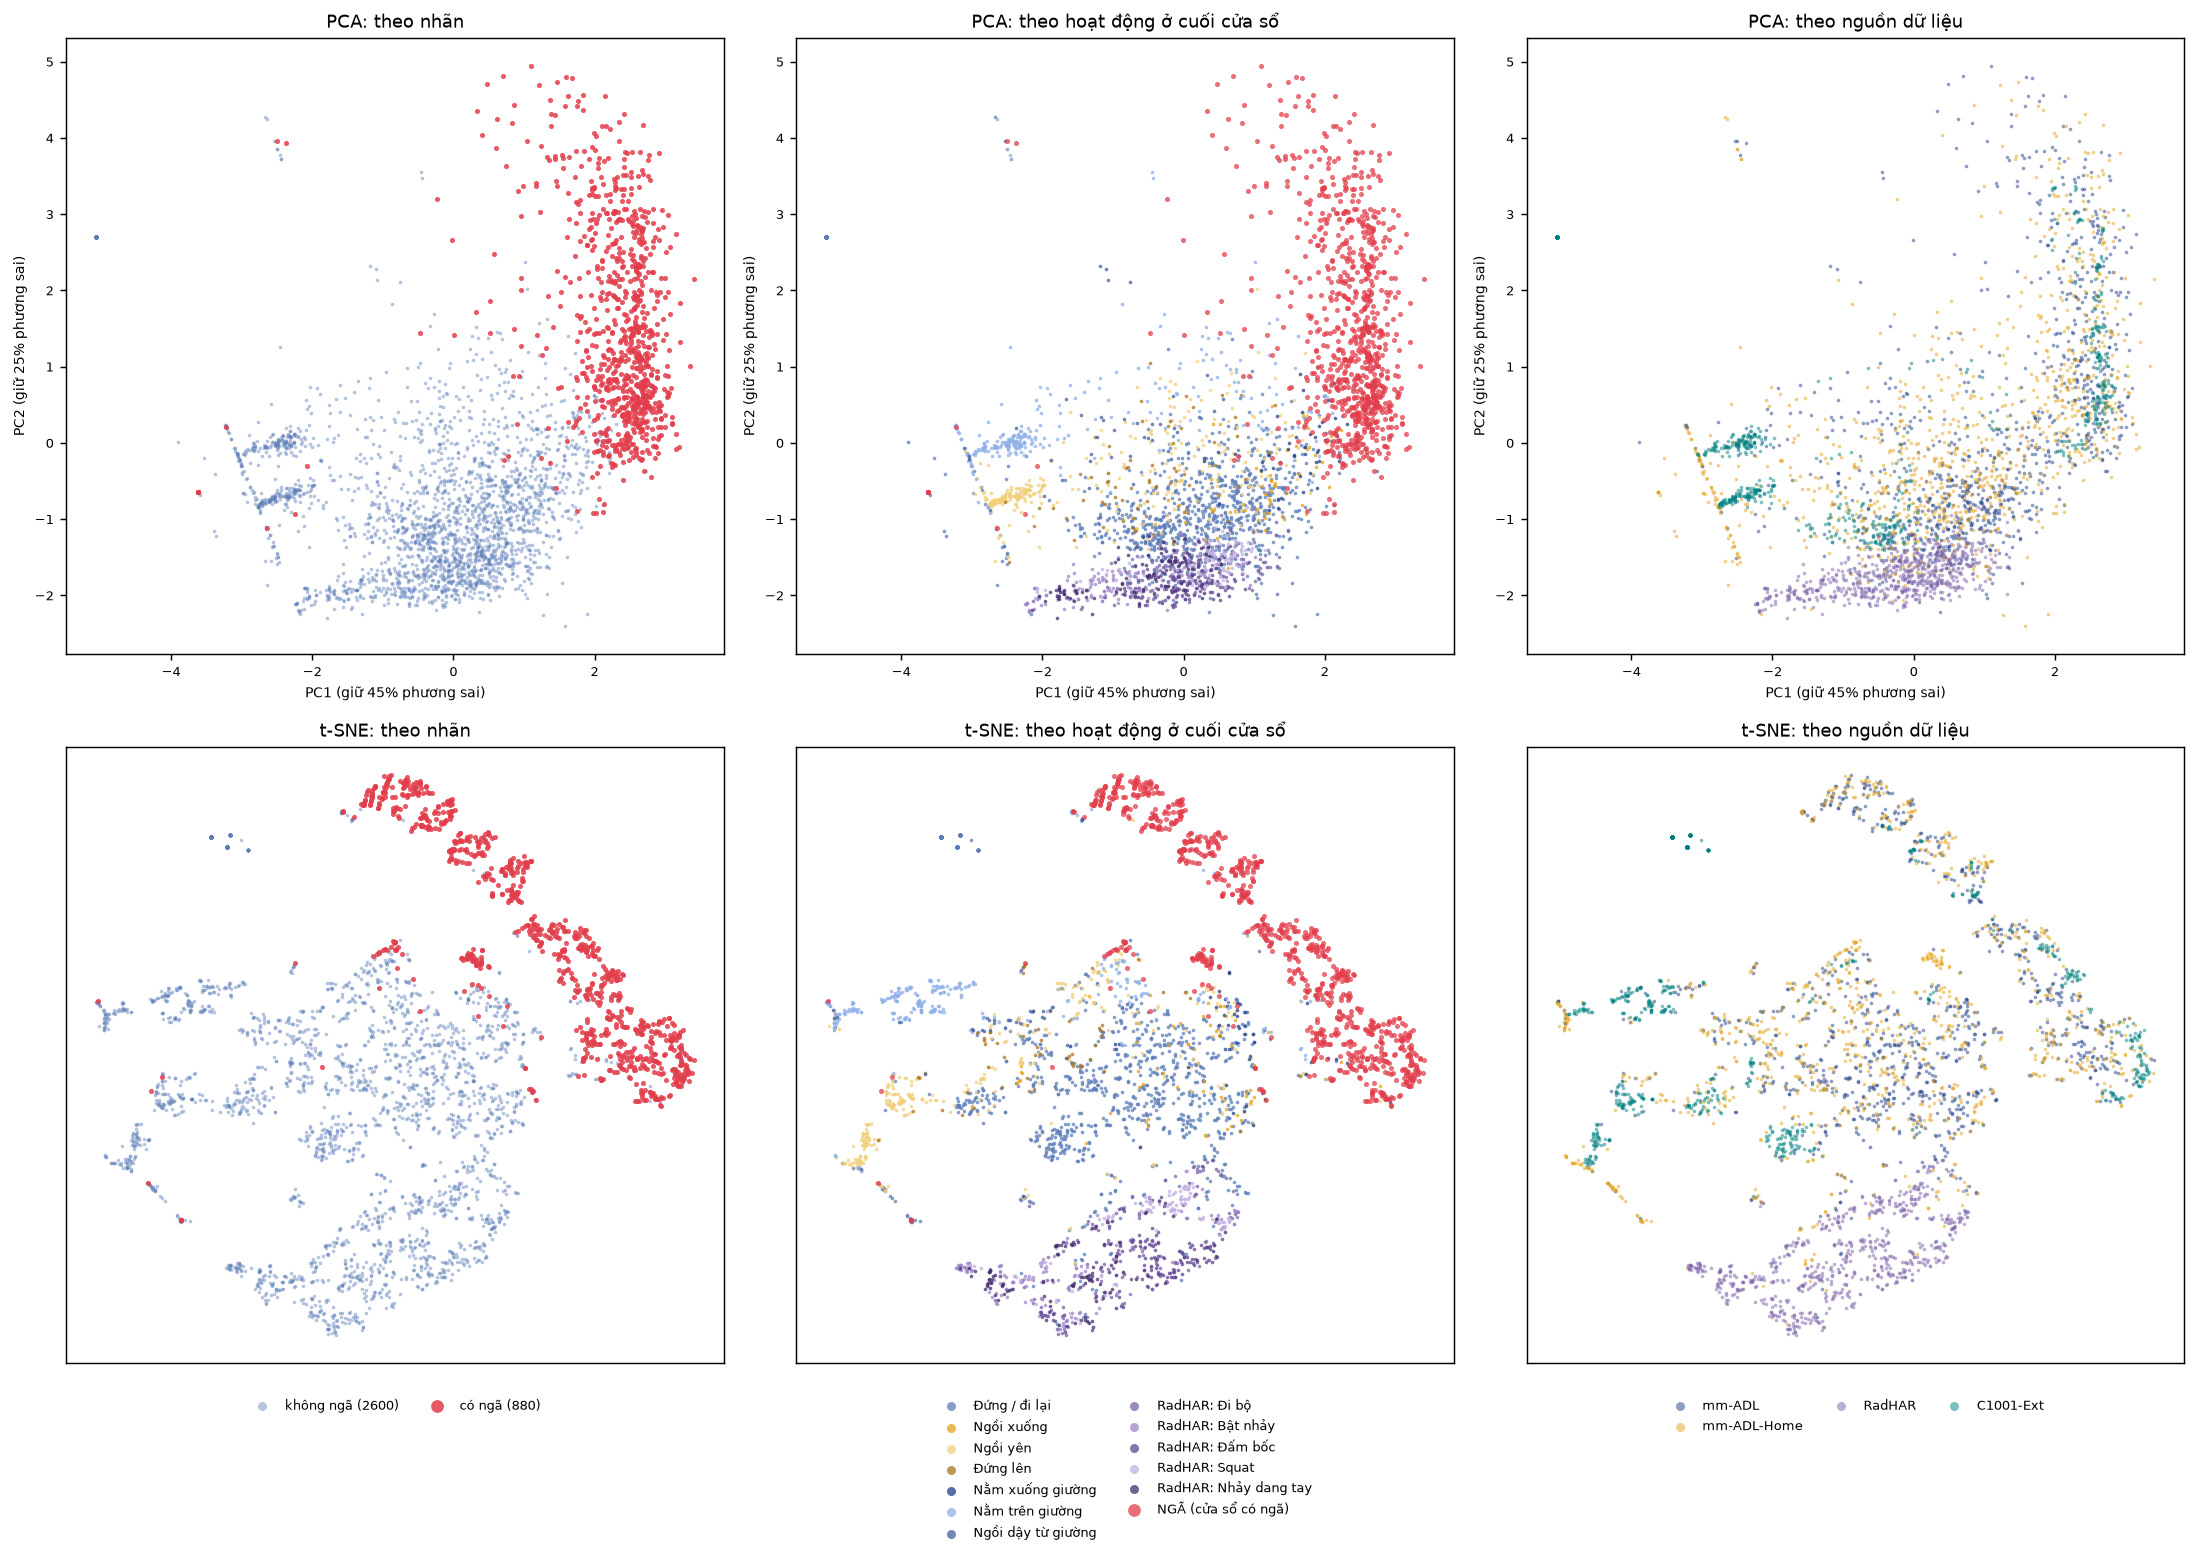

In [15]:
def eda_ban_do_2d():
    data = eda_cua_so()
    if data is None:
        print("Chua co cua so co nhan -> bo qua 6h.")
        return None
    Xw, yw, dw, hw = data
    rng = np.random.default_rng(SEED + 6)       # bộ sinh RIÊNG: không đụng tới RNG của phần huấn luyện
    doms = [d for d in EDA_NGUON if (dw == d).any()]
    quota = max(100, EDA_MAX_POINTS // len(doms))
    pick = []
    for d in doms:
        for lab, phan in ((1, 0.35), (0, 0.65)):
            idx = np.where((dw == d) & (yw == lab))[0]
            k = min(len(idx), int(quota * phan))
            if k:
                pick.append(rng.choice(idx, k, replace=False))
    if not pick:
        return None
    pick = np.concatenate(pick)
    pick = pick[np.argsort(yw[pick], kind="stable")]       # vẽ không ngã trước, ngã đè lên trên
    Z = Xw[pick]
    sd = Z.std(axis=0)
    Z = (Z - Z.mean(axis=0)) / np.where(sd > 1e-9, sd, 1.0)
    yy, dd, hh = yw[pick], dw[pick], hw[pick].copy()
    hh[yy == 1] = "NGÃ (cửa sổ có ngã)"
    print(f"Ban do 2D: {len(pick)} cua so ({int((yy == 1).sum())} co nga), lay ngau nhien tu {len(doms)} nguon")
    if not HAS_PLT:
        return None
    from sklearn.decomposition import PCA
    pca = PCA(n_components=2, random_state=SEED)
    P2 = pca.fit_transform(Z)
    r1, r2 = pca.explained_variance_ratio_[:2] * 100
    emb = [("PCA", P2, f"PC1 (giữ {r1:.0f}% phương sai)", f"PC2 (giữ {r2:.0f}% phương sai)")]
    if EDA_TSNE and len(Z) >= 200:
        from sklearn.manifold import TSNE
        t0 = time.time()
        E = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Z)
        emb.append(("t-SNE", E, "", ""))
        print(f"  t-SNE xong sau {time.time() - t0:.0f} s")
    ten_hd = [n for n in EDA_MAU_HD if n != "NGÃ (cửa sổ có ngã)" and (hh == n).any()]
    ten_hd += [n for n in dict.fromkeys(hh) if n not in EDA_MAU_HD]
    if (yy == 1).any():
        ten_hd.append("NGÃ (cửa sổ có ngã)")
    tim = iter(["#7b61a8", "#9d86c9", "#5d4590", "#c0b0e0", "#432d6e", "#8e7bb5"])
    mau_hd = {n: EDA_MAU_HD.get(n) or next(tim, "#999999") for n in ten_hd}
    fig, axs = plt.subplots(len(emb), 3, figsize=(17, 5.2 * len(emb) + 1.6), squeeze=False)
    for r, (ten, E, xl, yl) in enumerate(emb):
        ax = axs[r, 0]
        for lab, mau, nm, sz in ((0, EDA_MAU_KHONG_NGA, "không ngã", 4), (1, EDA_MAU_NGA, "có ngã", 8)):
            sel = yy == lab
            if sel.any():
                ax.scatter(E[sel, 0], E[sel, 1], s=sz, color=mau, alpha=0.45 if lab == 0 else 0.85, lw=0,
                           label=f"{nm} ({int(sel.sum())})")
        ax = axs[r, 1]
        for n in ten_hd:
            sel = hh == n
            ax.scatter(E[sel, 0], E[sel, 1], s=8 if n.startswith("NGÃ") else 4, color=mau_hd[n], alpha=0.75,
                       lw=0, label=n)
        ax = axs[r, 2]
        for d in doms:
            sel = dd == d
            ax.scatter(E[sel, 0], E[sel, 1], s=4, color=EDA_MAU_NGUON[d], alpha=0.5, lw=0,
                       label=EDA_TEN_NGUON[d])
        for c, ct in enumerate(("theo nhãn", "theo hoạt động ở cuối cửa sổ", "theo nguồn dữ liệu")):
            ax = axs[r, c]
            ax.set_title(f"{ten}: {ct}", fontsize=10)
            if xl:
                ax.set_xlabel(xl, fontsize=8)
                ax.set_ylabel(yl, fontsize=8)
                ax.tick_params(labelsize=7)
            else:
                ax.set_xticks([])
                ax.set_yticks([])
            if r == len(emb) - 1:                 # một chú thích cho cả cột, đặt ở hàng cuối
                ax.legend(fontsize=7, markerscale=2.5, loc="upper center", frameon=False,
                          bbox_to_anchor=(0.5, -0.12 if xl else -0.04), ncol=2 if c == 1 else 3)
    fig.tight_layout()
    return fig


eda_chay("eda_08_ban_do_2d.png", eda_ban_do_2d)

### 6i. Tư thế tĩnh: nằm sàn và nằm giường khác nhau tới đâu
Model tư thế ở mục 12 dựa trên giả thuyết: radar trên trần thấy người nằm sàn **xa hơn** người nằm
giường. Hình này kiểm tra giả thuyết đó ngay trên dữ liệu (chỉ lấy mẫu có người, trong đoạn nhãn tĩnh).
Ô phải là độ cao tâm người lấy từ point cloud, thứ C1001 không có. Nếu ô phải tách rõ mà ô trái chồng
nhiều thì phần thông tin bị mất là do C1001 chỉ cho **khoảng cách**, mà khoảng cách gộp cả độ lệch
ngang của người so với tâm radar.

Tu the tinh (chi mau co nguoi; khoang cach tinh tu radar ao tren tran):
             tu_the  so_mau  khoang_cach_p25  khoang_cach_trung_vi  khoang_cach_p75  bien_do_trung_vi  do_cao_trung_vi_m
            Walking   90830            134.0                 144.0            154.0              34.0               1.27
     Sit-Stationary   19894            154.0                 167.0            180.0               2.0               1.03
  LayBed-Stationary   16138            188.0                 195.0            205.0               1.0               0.75
LayFloor-Stationary   26266            232.0                 234.0            235.0               0.0               0.36


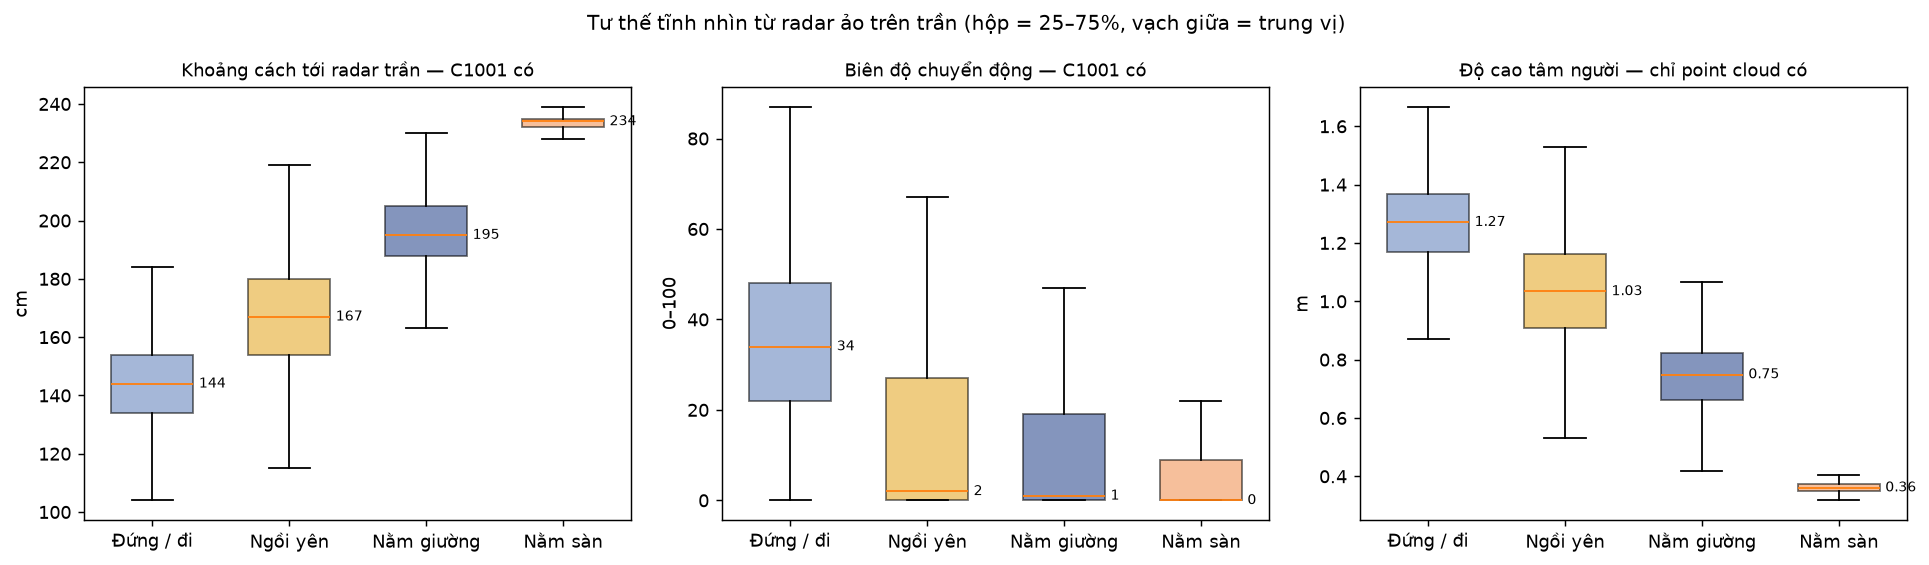

In [16]:
EDA_TU_THE = [("Walking", "Đứng / đi", "#5b7db8"), ("Sit-Stationary", "Ngồi yên", "#e3a21a"),
              ("LayBed-Stationary", "Nằm giường", "#1f3f87"), ("LayFloor-Stationary", "Nằm sàn", "#f08c4a")]


def eda_tu_the():
    gom = {nhan: {"d": [], "a": [], "h": []} for nhan, _, _ in EDA_TU_THE}
    for s in PUB_SEQS:
        if s["domain"] not in ("mm-adl", "mm-adl-home", "c1001-ext"):
            continue
        labs, seq, h = s["raw"]["labs"], s["seq"], s["track"]["P"][:, 2]
        co = seq[:, 0] != 0
        for nhan, _, _ in EDA_TU_THE:
            mk = co & eda_mask(labs, nhan)
            if mk.any():
                gom[nhan]["d"].append(seq[mk, 4].astype(float))
                gom[nhan]["a"].append(seq[mk, 2].astype(float))
                gom[nhan]["h"].append(h[mk])
    loai = [(nhan, ten, mau, {k: np.concatenate(v) for k, v in gom[nhan].items()})
            for nhan, ten, mau in EDA_TU_THE if gom[nhan]["d"]]
    if not loai:
        print("Chua co mm-ADL / mm-ADL-Home -> bo qua 6i.")
        return None
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        tab = pd.DataFrame([dict(tu_the=nhan, so_mau=len(v["d"]),
                                 khoang_cach_p25=float(np.percentile(v["d"], 25)),
                                 khoang_cach_trung_vi=float(np.median(v["d"])),
                                 khoang_cach_p75=float(np.percentile(v["d"], 75)),
                                 bien_do_trung_vi=float(np.median(v["a"])),
                                 do_cao_trung_vi_m=float(np.nanmedian(v["h"])))
                            for nhan, _, _, v in loai])
    print("Tu the tinh (chi mau co nguoi; khoang cach tinh tu radar ao tren tran):")
    print(tab.round(2).to_string(index=False))
    if not HAS_PLT:
        return None
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.4), squeeze=False)
    for c, (k, ylab, tieu_de, dang) in enumerate((
            ("d", "cm", "Khoảng cách tới radar trần — C1001 có", "{:.0f}"),
            ("a", "0–100", "Biên độ chuyển động — C1001 có", "{:.0f}"),
            ("h", "m", "Độ cao tâm người — chỉ point cloud có", "{:.2f}"))):
        ax = axs[0, c]
        data = []
        for _, _, _, v in loai:
            arr = v[k][np.isfinite(v[k])]
            data.append(arr if len(arr) else np.array([np.nan]))
        bp = ax.boxplot(data, showfliers=False, patch_artist=True, widths=0.6)
        for patch, (_, _, mau, _) in zip(bp["boxes"], loai):
            patch.set_facecolor(mau)
            patch.set_alpha(0.55)
        for i, arr in enumerate(data, 1):
            if np.isfinite(arr).any():
                med = float(np.nanmedian(arr))
                ax.text(i + 0.34, med, dang.format(med), va="center", fontsize=8)
        ax.set_xticks(range(1, len(loai) + 1))
        ax.set_xticklabels([ten for _, ten, _, _ in loai])
        ax.set_ylabel(ylab)
        ax.set_title(tieu_de, fontsize=10)
    fig.suptitle("Tư thế tĩnh nhìn từ radar ảo trên trần (hộp = 25–75%, vạch giữa = trung vị)", fontsize=11)
    fig.tight_layout()
    return fig


eda_chay("eda_09_tu_the.png", eda_tu_the)

### 6j. Dữ liệu tự đo: đã đủ và đã sạch chưa
Chỉ vẽ khi đã có file `oalpha_du_lieu_huan_luyen.json` từ dashboard.
- Ô trái: số lần thử mỗi kịch bản và số lần **chip C1001 báo ngã**. Kịch bản ngã thì chip báo càng đủ càng
  tốt; kịch bản không ngã mà chip báo là báo nhầm.
- Ô giữa: khoảng thời gian giữa hai mẫu liên tiếp. Phải dồn quanh **250 ms**; đuôi dài nghĩa là dashboard
  nhận hụt mẫu (Wi-Fi chập chờn, laptop ngủ). Lần thử thiếu mẫu nên đo lại.
- Ô phải: một lần thử ngã, kèm lúc chip báo và vùng cửa sổ được gán nhãn "có ngã" (cách gán ở mục 4).

In [17]:
def eda_tu_do():
    if not OWN_SEQS:
        print("Chua co du lieu tu do -> bo qua 6j. Do bang dashboard roi bam 'Tai du lieu huan luyen (Kaggle)'.")
        return None
    rows = []
    for s in OWN_SEQS:
        t = s["trial"]
        rows.append(dict(kich_ban=str(t.get("scenarioName") or t.get("scenarioId") or "?"),
                         nga=bool(t.get("expectFall")), chip_bao=t.get("detectedAt") is not None,
                         giay=(t["endedAt"] - t["startedAt"]) / 1000, mau=len(s["seq"]),
                         cs_co_nga=int((s["y"] == 1).sum())))
    g = (pd.DataFrame(rows).groupby(["kich_ban", "nga"], sort=False)
           .agg(lan_thu=("mau", "size"), chip_bao=("chip_bao", "sum"), giay_tb=("giay", "mean"),
                mau_tb=("mau", "mean"), cs_co_nga=("cs_co_nga", "sum"))
           .reset_index().sort_values(["nga", "kich_ban"], ascending=[False, True]))
    print("Du lieu tu do theo kich ban (chip_bao: so lan chip C1001 bao nga):")
    print(g.round(1).to_string(index=False))
    smp = globals().get("_own_samples")
    gap = np.zeros(0)
    if smp is not None and len(smp) > 1:
        gap = np.diff(smp["wall"].to_numpy(float))
        gap = gap[(gap > 0) & (gap < 5000)]            # bỏ khoảng nghỉ dài giữa hai phiên đo
        if len(gap):
            print(f"Khoang cach giua 2 mau lien tiep: trung vi {np.median(gap):.0f} ms, "
                  f"{np.mean(np.abs(gap - 250) <= 60) * 100:.1f}% nam trong 250 +/- 60 ms")
    if not HAS_PLT:
        return None
    fig, axs = plt.subplots(1, 3, figsize=(17, max(4.2, 0.42 * len(g) + 1.6)), squeeze=False)
    ax = axs[0, 0]
    yy = np.arange(len(g))
    ax.barh(yy, g["lan_thu"], color=["#f6c1c6" if n else "#c9d5ea" for n in g["nga"]], label="số lần thử")
    ax.barh(yy, g["chip_bao"], height=0.45, color=[EDA_MAU_NGA if n else "#1f3f87" for n in g["nga"]],
            label="chip C1001 báo ngã")
    for i, (lt, cb, n) in enumerate(zip(g["lan_thu"], g["chip_bao"], g["nga"])):
        ax.text(lt, i, f" {int(cb)}/{int(lt)} " + ("bắt được" if n else "báo nhầm"), va="center", fontsize=7)
    ax.set_yticks(yy)
    ax.set_yticklabels(list(g["kich_ban"]), fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, float(g["lan_thu"].max()) * 1.45)
    ax.set_xlabel("số lần thử")
    ax.set_title("Lần thử theo kịch bản (đỏ = kịch bản ngã)", fontsize=10)
    ax.legend(fontsize=7, loc="lower right")
    ax = axs[0, 1]
    if len(gap):
        ax.hist(np.clip(gap, 0, 1500), bins=np.arange(0, 1525, 25), color=EDA_MAU_NGUON["own"])
        ax.axvline(250, color="#333333", ls="--", lw=1, label="250 ms (đúng nhịp)")
        ax.set_yscale("log")
        ax.legend(fontsize=8)
    else:
        ax.text(0.5, 0.5, "Không đọc được thời điểm từng mẫu", ha="center", va="center", transform=ax.transAxes)
    ax.set_xlabel("khoảng cách giữa 2 mẫu liên tiếp (ms)")
    ax.set_title("Nhịp lấy mẫu 4 Hz có đều không", fontsize=10)
    ax = axs[0, 2]
    ex = next((s for s in OWN_SEQS if s["trial"].get("expectFall") and s["trial"].get("detectedAt")), OWN_SEQS[0])
    tr = ex["trial"]
    ts = np.arange(len(ex["seq"])) * PERIOD_S
    if smp is not None:                            # cắt lại đúng như own_sequences() ở mục 4
        wall = smp["wall"].to_numpy(float)
        lo, hi = np.searchsorted(wall, [tr["startedAt"], tr["endedAt"] + 2000])
        if hi - lo == len(ex["seq"]):
            ts = (wall[lo:hi] - tr["startedAt"]) / 1000
    ax.plot(ts, ex["seq"][:, 2], color="#1f3f87", lw=1.3, label="biên độ")
    ax.set_ylim(0, 100)
    ax.set_ylabel("biên độ (0–100)")
    ax2 = ax.twinx()
    ax2.plot(ts, ex["seq"][:, 4], color="#e3a21a", lw=1.3, label="khoảng cách (cm)")
    ax2.set_ylabel("cm")
    if (ex["y"] == 1).any():
        het = ts[WINDOW_SIZE - 1:][ex["y"] == 1]
        ax.axvspan(float(het.min()), float(het.max()), color=EDA_MAU_NGA, alpha=0.15, lw=0,
                   label="cửa sổ kết thúc trong vùng này = có ngã")
    if tr.get("detectedAt"):
        bao = (tr["detectedAt"] - tr["startedAt"]) / 1000
        ax.axvline(bao, color=EDA_MAU_NGA, lw=1.2, label="chip báo ngã")
        ax.axvline(bao - OWN_FALL_S, color=EDA_MAU_NGA, lw=1, ls=":", label=f"ước lượng lúc ngã (−{OWN_FALL_S:.0f} s)")
    ax.set_xlabel("giây từ lúc bắt đầu lần thử")
    ax.set_title(f"Một lần thử: {ex['name']}", fontsize=10)
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper right")
    fig.tight_layout()
    return fig


eda_chay("eda_10_du_lieu_tu_do.png", eda_tu_do)

Chua co du lieu tu do -> bo qua 6j. Do bang dashboard roi bam 'Tai du lieu huan luyen (Kaggle)'.


### Xem xong mục 6 thì làm gì
Trước khi tin vào con số huấn luyện nào, các hình trên nên trả lời được:
1. Số cú ngã có đủ, và có chia đều cho các người không (6a)?
2. Ngã có thật sự khác ngồi xuống / nằm xuống giường không, và khác trong **khoảng thời gian** nào (6d, 6e)?
3. Đặc trưng nào mang thông tin, đặc trưng nào thừa (6f)?
4. Dữ liệu tự đo có lệch xa dữ liệu công khai không (6g)? Lệch càng xa càng phải đo thêm trong phòng thật.

Khi `CHI_XEM_DU_LIEU = True`, notebook dừng ở ô dưới, chưa sang mục 7.

In [18]:
if RUN_EDA:
    if EDA_FILES:
        print(f"Muc 6: da luu {len(EDA_FILES)} bieu do vao {OUT_DIR.resolve()}")
        for _eda_f in EDA_FILES:
            print("   ", _eda_f)
    elif not HAS_PLT:
        print("Muc 6: khong co matplotlib -> chi in bang so, khong ve hinh (pip install matplotlib)")
_EDA_CACHE.clear()          # trả lại bộ nhớ của bảng cửa sổ dùng riêng cho mục 6
if CHI_XEM_DU_LIEU:
    raise SystemExit("CHI_XEM_DU_LIEU = True: da chuan bi du lieu va ve xong muc 6, DUNG truoc khi huan luyen."
                     " Dat CHI_XEM_DU_LIEU = False o muc 1 roi chay lai de huan luyen.")

Muc 6: da luu 10 bieu do vao C:\doan\giam_sat_nguoi_gia_Es32s3\oalpha_output
    eda_01_tong_quan.png
    eda_02_thoi_luong_hoat_dong.png
    vi_du_cu_nga.png
    eda_03_nga_va_ca_de_nham.png
    eda_04_chu_ky_su_kien.png
    eda_05_phan_bo_dac_trung.png
    eda_06_tuong_quan_dac_trung.png
    eda_07_lech_mien.png
    eda_08_ban_do_2d.png
    eda_09_tu_the.png


## 7. Huấn luyện + đánh giá chéo theo nhóm
- **Không chuẩn hóa thêm**, không đổi mô hình: firmware chỉ chạy được hồi quy logistic 10 đặc trưng thô.
- **Cân lớp** (`class_weight="balanced"`): cửa sổ không ngã nhiều gấp chục lần cửa sổ ngã.
- **Chia theo nhóm**: mm-ADL chia theo **người** (người trong tập kiểm tra chưa từng xuất hiện khi học),
  dữ liệu tự đo chia theo **lần thử**. Chia theo cửa sổ sẽ rò rỉ dữ liệu, điểm số đẹp giả.
- Chọn `C` (độ chặt điều chuẩn L2) trên dự đoán ngoài-tập (out-of-fold), ưu tiên dữ liệu tự đo.
  Ngưỡng F1 tính ở đây chỉ để tham khảo: ngưỡng **xuất xuống firmware** chọn ở mục 8 theo
  trần báo nhầm mỗi giờ, vì đó mới là con số người nhà chịu đựng.

In [19]:
ALL_SEQS = OWN_SEQS + PUB_SEQS
for _s in ALL_SEQS:
    _s["X"] = window_features(_s["seq"])
    assert len(_s["X"]) == len(_s["y"]), _s["name"]

_lab = [(k, j) for k, s in enumerate(ALL_SEQS) for j in np.where(s["y"] >= 0)[0]]
SEQ_IDX = np.array([k for k, _ in _lab])
X = np.vstack([ALL_SEQS[k]["X"][j] for k, j in _lab]) if _lab else np.zeros((0, 10))
y = np.array([ALL_SEQS[k]["y"][j] for k, j in _lab])
DOM = np.array([ALL_SEQS[k]["domain"] for k in SEQ_IDX])
GROUP_NAMES = sorted({s["group"] for s in ALL_SEQS})
GROUP_ID = {g: i for i, g in enumerate(GROUP_NAMES)}
GID = np.array([GROUP_ID[ALL_SEQS[k]["group"]] for k in SEQ_IDX])
W = np.where(DOM == "own", W_OWN, 1.0)
if y.sum() == 0 or (y == 0).sum() == 0:
    raise SystemExit("Can ca cua so co nga lan khong nga de huan luyen.")
print(pd.crosstab(DOM, y, rownames=["nguon"], colnames=["nhan (1 = co nga)"]))

OWN_OK = int(((DOM == "own") & (y == 1)).sum()) >= 20 and len({g for g, d in zip(GID, DOM) if d == "own"}) >= N_FOLDS
TARGET = "own" if OWN_OK else ("mm-adl" if (DOM == "mm-adl").any() else DOM[0])
print("Chon C va nguong theo du lieu:", TARGET, "" if OWN_OK else "(chua du du lieu tu do, chi so CHUA dung de bao cao)")

_n_splits = max(2, min(N_FOLDS, len(set(GID))))
FOLDS = list(StratifiedGroupKFold(n_splits=_n_splits, shuffle=True, random_state=SEED).split(X, y, GID))
FOLD_OF_GROUP = {}
for f, (_, te) in enumerate(FOLDS):
    for gi in set(GID[te]):
        FOLD_OF_GROUP[GROUP_NAMES[gi]] = f


def fit(Xa, ya, wa, C):
    m = LogisticRegression(C=C, class_weight="balanced", max_iter=5000)
    m.fit(Xa, ya, sample_weight=wa)
    return m


def active_subsample(tr_idx, X_all, y_all, stride_easy=4, pos_repeat=2):
    """Lấy mẫu thông minh giữ 100% mẫu dương + 100% mẫu âm khó (biên độ cao, sụt khoảng cách, nằm im) + mẫu âm dễ theo bước nhảy."""
    pos = tr_idx[y_all[tr_idx] == 1]
    neg = tr_idx[y_all[tr_idx] == 0]
    hard_mask = (X_all[neg, 1] >= 0.72) | (X_all[neg, 5] >= 0.08) | (X_all[neg, 9] > 0)
    neg_hard = neg[hard_mask]
    neg_easy = neg[~hard_mask][::stride_easy]
    return np.concatenate([np.repeat(pos, pos_repeat), neg_hard, neg_easy])


def fit_teacher_fold(X_tr, y_tr, seed=SEED):
    """Huấn luyện tổ hợp Teacher Ensemble (HistGradientBoosting + RandomForest + MLP-128-64-32)."""
    sub_idx = active_subsample(np.arange(len(y_tr)), X_tr, y_tr, stride_easy=4, pos_repeat=2)
    hgb = HistGradientBoostingClassifier(
        max_iter=180, max_depth=6, learning_rate=0.06, l2_regularization=1.0,
        class_weight="balanced", random_state=seed
    )
    rf = RandomForestClassifier(
        n_estimators=100, max_depth=12, max_samples=0.6,
        class_weight="balanced_subsample", n_jobs=-1, random_state=seed
    )
    mlp_t = make_pipeline(
        StandardScaler(),
        MLPClassifier((128, 64, 32), max_iter=28, batch_size=512, alpha=1e-3, random_state=seed)
    )
    hgb.fit(X_tr, y_tr)
    rf.fit(X_tr[sub_idx], y_tr[sub_idx])
    mlp_t.fit(X_tr[sub_idx], y_tr[sub_idx])
    return (hgb, rf, mlp_t)


def pred_teacher(tm, X_in):
    hgb, rf, mlp_t = tm
    return (
        0.45 * hgb.predict_proba(X_in)[:, 1]
        + 0.30 * rf.predict_proba(X_in)[:, 1]
        + 0.25 * mlp_t.predict_proba(X_in)[:, 1]
    )


def fit_distilled_lr(X_tr, y_tr, p_teach_tr, C=1.0, T=2.0, alpha=0.65):
    """
    Chưng cất tri thức từ xác suất mềm của Teacher sang Student Logistic Regression 10 đặc trưng,
    kèm Ràng buộc Dấu Vật Lý (Physical Sign Regularization) để triệt tiêu hoàn toàn hiện tượng
    đảo dấu đa cộng tuyến (w[0] âm), nổ trọng số khoảng cách (w[4] = +15.34) và tê liệt w[9]:
    - Toàn bộ 10 trọng số đặc trưng f0..f9 đều mang dấu dương đúng bản chất vật lý hướng về 'ngã'.
    """
    p_clip = np.clip(p_teach_tr, 1e-4, 1.0 - 1e-4)
    z_teach = np.log(p_clip / (1.0 - p_clip)) / T
    sw = np.where(y_tr == 1, 8.0 * (0.5 + p_teach_tr), 1.0 + 6.0 * (p_teach_tr ** 1.5))
    q_soft = alpha * p_teach_tr + (1.0 - alpha) * y_tr.astype(float)

    pos_i = np.where(y_tr == 1)[0]
    neg_i = np.where(y_tr == 0)[0]
    hard_n = neg_i[p_teach_tr[neg_i] >= 0.03]
    easy_n = neg_i[p_teach_tr[neg_i] < 0.03][::4]
    sel = np.concatenate([pos_i, hard_n, easy_n])
    Xs, qs, sws, zs = X_tr[sel], q_soft[sel], sw[sel], z_teach[sel]
    sws = sws / sws.mean()

    bounds = [
        (1.2, 8.0),    # f0 Trung binh bien do (>0)
        (2.5, 10.0),   # f1 Bien do lon nhat (>0)
        (1.5, 8.0),    # f2 Do lech chuan bien do (>0)
        (0.15, 3.0),   # f3 Bien do cuoi - dau (>0)
        (1.5, 5.5),    # f4 Trung binh khoang cach (>0, bounded)
        (5.0, 14.0),   # f5 Khoang cach cuoi - dau (>0)
        (0.2, 3.0),    # f6 Khoang cach nho nhat (>0)
        (0.1, 2.5),    # f7 Ti le mau co nguoi (>0)
        (0.4, 4.0),    # f8 Ti le mau dang hoat dong (>0)
        (1.5, 6.0),    # f9 Ti le mau nam im lau (>0)
        (-12.0, -3.5)  # bias w0 (<0 cho sự kiện hiếm)
    ]
    x0 = np.array([2.8, 4.5, 3.2, 0.4, 3.5, 8.5, 1.0, 0.5, 1.2, 2.5, -7.5])

    def loss_and_grad(wb):
        w, b = wb[:10], wb[10]
        z = np.clip(Xs @ w + b, -25.0, 25.0)
        p = 1.0 / (1.0 + np.exp(-z))
        bce = -np.mean(sws * (qs * np.log(p + 1e-9) + (1.0 - qs) * np.log(1.0 - p + 1e-9)))
        logit_mse = 0.08 * np.mean(sws * ((z / T - zs) ** 2))
        l2 = 0.002 * np.sum(w ** 2)
        diff = sws * ((p - qs) + 0.16 * (z / T - zs) / T) / len(Xs)
        gw = Xs.T @ diff + 0.004 * w
        gb = float(np.sum(diff))
        return bce + logit_mse + l2, np.append(gw, gb)

    res = minimize(loss_and_grad, x0, method="L-BFGS-B", jac=True, bounds=bounds, options={"maxiter": 250})
    w_opt, b_opt = res.x[:10], float(res.x[10])
    m = LogisticRegression(C=C)
    m.classes_ = np.array([0, 1])
    m.coef_ = w_opt.reshape(1, -1)
    m.intercept_ = np.array([b_opt])
    return m


def best_threshold(yt, pt):
    grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
    f1s = [precision_recall_fscore_support(yt, pt >= t, average="binary", zero_division=0)[2] for t in grid]
    i = int(np.argmax(f1s))
    return float(grid[i]), float(f1s[i])


def oof(C):
    p = np.full(len(y), np.nan)
    for tr, te in FOLDS:
        p[te] = fit(X[tr], y[tr], W[tr], C).predict_proba(X[te])[:, 1]
    return p


_scores = []
for C in C_GRID:
    _p = oof(C)
    _m = DOM == TARGET
    _th, _f1 = best_threshold(y[_m], _p[_m])
    _scores.append((C, _th, _f1, _p))
    print(f"[LR Goc] C={C:<5} F1 ngoai-tap ({TARGET}) = {_f1:.3f} tai nguong {_th:.2f}")
BEST_C, LR_BEFORE_TH_F1, _, LR_BEFORE_OOF = max(_scores, key=lambda r: r[2])
LR_BEFORE_MODEL = fit(X, y, W, BEST_C)
LR_BEFORE_WEIGHTS = LR_BEFORE_MODEL.coef_[0].astype(float)
LR_BEFORE_BIAS = float(LR_BEFORE_MODEL.intercept_[0])
_lr_before_fold_models = [fit(X[tr], y[tr], W[tr], BEST_C) for tr, _ in FOLDS]
LR_BEFORE_SEQ_P = [
    None if FOLD_OF_GROUP.get(s["group"]) is None or len(s["X"]) == 0
    else _lr_before_fold_models[FOLD_OF_GROUP[s["group"]]].predict_proba(s["X"])[:, 1]
    for s in ALL_SEQS
]

# Huấn luyện Teacher Ensemble và Chưng cất sang Student Logistic Regression
TEACHER_FOLDS = []
TEACHER_OOF = np.zeros(len(y))
LR_KD_FOLDS = []
P_OOF = LR_BEFORE_OOF.copy()
if USE_DISTILLATION:
    _t_kd = time.time()
    print("\n[Chưng cất Tri thức] Đang huấn luyện Teacher Ensemble (HGB + RF + MLP-128-64-32) trên các fold độc lập theo người...")
    for _f, (_tr, _te) in enumerate(FOLDS):
        _tm = fit_teacher_fold(X[_tr], y[_tr], seed=SEED + _f)
        TEACHER_FOLDS.append(_tm)
        TEACHER_OOF[_te] = pred_teacher(_tm, X[_te])
        _p_teach_tr = pred_teacher(_tm, X[_tr])
        _m_lr_kd = fit_distilled_lr(X[_tr], y[_tr], _p_teach_tr, C=BEST_C, T=2.0, alpha=0.65)
        LR_KD_FOLDS.append(_m_lr_kd)
        P_OOF[_te] = _m_lr_kd.predict_proba(X[_te])[:, 1]
    _m_t = DOM == TARGET
    THRESHOLD, _f1_kd = best_threshold(y[_m_t], P_OOF[_m_t])
    print(f"=> Teacher Ensemble OOF AUC = {roc_auc_score(y, TEACHER_OOF):.4f}, AP = {average_precision_score(y, TEACHER_OOF):.4f}")
    print(f"=> Student Distilled LR ({time.time() - _t_kd:.1f}s): OOF AUC = {roc_auc_score(y, P_OOF):.4f}, AP = {average_precision_score(y, P_OOF):.4f}, F1 ({TARGET}) = {_f1_kd:.3f} tai nguong {THRESHOLD:.2f}")
else:
    THRESHOLD = LR_BEFORE_TH_F1
    print(f"=> Chon C = {BEST_C}, nguong = {THRESHOLD:.2f}")


def window_report(mask, probs=None, th=None):
    if mask.sum() == 0:
        return None
    p_arr = P_OOF if probs is None else probs
    th_val = THRESHOLD if th is None else th
    ym = y[mask]
    pm = p_arr[mask]
    pred_m = pm >= th_val
    if ym.min() == ym.max():
        # Miền chỉ chứa mẫu âm (như RadHAR: 5 hoạt động mạnh không ngã) -> trả về độ đặc hiệu (specificity) & số cửa sổ báo nhầm thay vì None
        fp_w = int(pred_m.sum())
        tn_w = int((~pred_m).sum())
        spec = tn_w / max(len(ym), 1)
        return dict(cua_so=int(mask.sum()), co_nga=0, precision=1.0 if fp_w == 0 else 0.0,
                    recall=1.0, f1=round(spec, 3), auc=1.0, ap=0.0,
                    specificity=round(spec, 4), bao_nham_cua_so=fp_w)
    pr, rc, f1, _ = precision_recall_fscore_support(ym, pred_m, average="binary", zero_division=0)
    return dict(cua_so=int(mask.sum()), co_nga=int(ym.sum()), precision=round(float(pr), 3), recall=round(float(rc), 3),
                f1=round(float(f1), 3), auc=round(float(roc_auc_score(ym, pm)), 3),
                ap=round(float(average_precision_score(ym, pm)), 3))


# Tính lần đầu ở ngưỡng F1. Mục 8 chọn lại ngưỡng theo trần báo nhầm rồi TÍNH LẠI bảng này
# ở đúng ngưỡng ấy, để header sinh ra không trộn hai ngưỡng khác nhau.
WINDOW_METRICS = {d: window_report(DOM == d) for d in sorted(set(DOM))}
print(pd.DataFrame({k: v for k, v in WINDOW_METRICS.items() if v}).T)

nhan (1 = co nga)      0     1
nguon                         
c1001-ext           2970   180
mm-adl             95144  6471
mm-adl-home        41339  1460
radhar              2778     0
Chon C va nguong theo du lieu: mm-adl (chua du du lieu tu do, chi so CHUA dung de bao cao)
[LR Goc] C=0.03  F1 ngoai-tap (mm-adl) = 0.880 tai nguong 0.86
[LR Goc] C=0.1   F1 ngoai-tap (mm-adl) = 0.878 tai nguong 0.87
[LR Goc] C=0.3   F1 ngoai-tap (mm-adl) = 0.875 tai nguong 0.90
[LR Goc] C=1.0   F1 ngoai-tap (mm-adl) = 0.873 tai nguong 0.92
[LR Goc] C=3.0   F1 ngoai-tap (mm-adl) = 0.875 tai nguong 0.91
[LR Goc] C=10.0  F1 ngoai-tap (mm-adl) = 0.874 tai nguong 0.91

[Chưng cất Tri thức] Đang huấn luyện Teacher Ensemble (HGB + RF + MLP-128-64-32) trên các fold độc lập theo người...
=> Teacher Ensemble OOF AUC = 0.9937, AP = 0.9488
=> Student Distilled LR (60.4s): OOF AUC = 0.9850, AP = 0.9316, F1 (mm-adl) = 0.885 tai nguong 0.84
               cua_so  co_nga  precision  ...     ap  specificity  bao_nham_c

## 8. Đánh giá theo SỰ KIỆN, mô phỏng đúng firmware
Firmware chạy model mỗi 250 ms và chỉ báo ngã khi **2 cửa sổ liên tiếp** vượt ngưỡng. Ô này dùng đúng
luật đó trên dự đoán ngoài-tập:
- **dữ liệu công khai**: tỉ lệ cú ngã bắt được (báo trong lúc ngã tới 3 s sau) và số **báo nhầm
  mỗi giờ** sinh hoạt, kèm bảng *điểm vận hành* theo từng ngưỡng;
- **tự đo**: chấm TP/FP/FN/TN **từng lần thử** cho cả **model** và **thuật toán của chip** để so sánh
  (đây là bảng "model của em vs chip" cho chương 4).

**Ngưỡng xuất xuống firmware chọn theo TRẦN BÁO NHẦM** (`FA_BUDGET_PER_HOUR`), không theo F1.
Ngưỡng F1 của hồi quy logistic đo được là 0,74 — nghe ổn, nhưng ở ngưỡng đó nó hú **127
lần mỗi giờ**, tức cứ 28 giây một lần: thiết bị sẽ bị rút điện trong ngày đầu. F1 cân
precision/recall theo **cửa sổ**, trong khi cái người dùng chịu đựng là **sự kiện mỗi giờ**.
Cả hai ngưỡng đều được ghi vào `model_report.json` (`threshold` và `threshold_f1`).
Muốn tự đặt thì dùng `THRESHOLD_OVERRIDE` ở mục 1.

In [20]:
def seq_probs():
    """Xác suất ngoài-tập cho MỌI cửa sổ (cả cửa sổ bỏ qua) của từng chuỗi, theo fold của nhóm nó."""
    models = LR_KD_FOLDS if (USE_DISTILLATION and LR_KD_FOLDS) else [fit(X[tr], y[tr], W[tr], BEST_C) for tr, _ in FOLDS]
    out = []
    for s in ALL_SEQS:
        f = FOLD_OF_GROUP.get(s["group"])
        out.append(None if f is None or len(s["X"]) == 0 else models[f].predict_proba(s["X"])[:, 1])
    return out


TEACHER_SEQ_P = [
    None if FOLD_OF_GROUP.get(s["group"]) is None or len(s["X"]) == 0 or not TEACHER_FOLDS
    else pred_teacher(TEACHER_FOLDS[FOLD_OF_GROUP[s["group"]]], s["X"])
    for s in ALL_SEQS
]


def fires(p, th):
    """Luật của firmware: cửa sổ j báo ngã nếu j và j-1 đều vượt ngưỡng."""
    hit = p >= th
    return hit & np.concatenate([[False], hit[:-1]]) if CONFIRM_WINDOWS == 2 else hit


CATCH_AFTER = 12            # cửa sổ kết thúc tới 3 s (12 mẫu) sau lúc chạm sàn vẫn tính là bắt được
FA_GAP = 40                 # hai lần báo cách nhau >= 10 s mới tính là hai lần báo nhầm


def event_scores(pairs, th):
    """Chấm điểm THEO SỰ KIỆN, đúng luật "2 cửa sổ liên tiếp" của firmware.

    `pairs`: các cặp (chuỗi, xác suất từng cửa sổ) của dữ liệu CÔNG KHAI (có `raw`).

    Đây là bản DUY NHẤT của phép chấm điểm này. Bản cũ có ba bản sao gần giống nhau
    (`public_events` ở mục 8, `pub_events_at` ở mục 11, `_dom_events` ở mục 11c): sửa một
    bản mà quên hai bản kia thì bảng so sánh của chương 4 lệch nhau mà không ai thấy.

    Hai giới hạn của phép đo này, nên nói rõ trong báo cáo:

    - "Giờ sinh hoạt" chỉ tính các cửa sổ nhãn 0 (cả 12 mẫu đều là sinh hoạt thường). Thời
      gian của các cửa sổ BỎ QUA (đang rơi, đang nằm trên sàn sau khi ngã, đang quỳ) không
      vào tử số lẫn mẫu số — đúng, vì báo động trong lúc người đang nằm trên sàn không phải
      báo nhầm; nhưng vì vậy "báo nhầm mỗi giờ" ở đây là trên giờ SINH HOẠT, không phải trên
      giờ đồng hồ.
    - Một cú ngã tính là bắt được nếu có cửa sổ nào kết thúc trong khoảng [lúc bắt đầu rơi,
      3 s sau khi chạm sàn] báo động. Luật 2 cửa sổ nghĩa là cửa sổ xác nhận có thể nằm ngay
      trước cú ngã, nên cách tính này hơi dễ dãi về phía có lợi cho model.
    """
    caught = total = fa = neg_windows = 0
    for s, p in pairs:
        f = fires(p, th)
        isf = np.array([l == "Falling" for l in s["raw"]["labs"]])
        for a in np.where(isf & ~np.concatenate([[False], isf[:-1]]))[0]:
            b = a
            while b + 1 < len(isf) and isf[b + 1]:
                b += 1
            total += 1
            lo = max(0, a - (WINDOW_SIZE - 1))
            hi = min(len(f), b + CATCH_AFTER - (WINDOW_SIZE - 1) + 1)
            caught += bool(f[lo:hi].any())
        last = -10 ** 9
        for j in np.where(f & (s["y"] == 0))[0]:
            if j - last >= FA_GAP:
                fa += 1
                last = j
        neg_windows += int((s["y"] == 0).sum())
    hours = neg_windows * PERIOD_S / 3600
    return dict(cu_nga=total, bat_duoc=caught, ti_le_bat=round(caught / max(total, 1), 3),
                bao_nham=fa, cua_so_khong_nga=neg_windows, gio_sinh_hoat=round(hours, 2),
                bao_nham_moi_gio=round(fa / max(hours, 1e-9), 1))


def pub_pairs(seq_probs):
    """Các cặp (chuỗi công khai, xác suất) dùng được để chấm điểm theo sự kiện."""
    return [(s, p) for s, p in zip(ALL_SEQS, seq_probs) if s["domain"] != "own" and p is not None]


def pub_events_at(seq_probs, th):
    """Bắt được bao nhiêu cú ngã + báo nhầm mỗi giờ, cho MỘT bộ xác suất bất kỳ."""
    return event_scores(pub_pairs(seq_probs), th)


# Ngưỡng dày ở vùng gần 1: model mạnh phải đặt ngưỡng rất cao mới đủ ít báo nhầm, nên toàn bộ
# vùng 0,84–0,99999 phải được rải dày. Lưới cũ nhảy 0,01 ở đây (…0,95 · 0,96 · 0,97 · 0,98…) rồi
# mới dày lên từ 0,99: đo được là nó BỎ SÓT điểm vận hành tốt — trần 6 báo nhầm/giờ chỉ dùng tới
# 3,9 (bắt 25,8%), trong khi ngưỡng 0,974 nằm giữa hai nấc lưới cho 5,7 báo nhầm/giờ và bắt 29,7%.
NGUONG_GRID = np.unique(np.concatenate([
    np.round(np.arange(0.30, 0.85, 0.01), 4),
    np.round(1 - np.logspace(-5, -0.8, 120)[::-1], 6)]))


def chon_nguong(seq_probs, budget, pairs=None):
    """Ngưỡng bắt được NHIỀU cú ngã nhất mà vẫn <= `budget` báo nhầm mỗi giờ.

    Chỉ nhận ngưỡng AN TOÀN: trần phải đạt ở ngưỡng đó VÀ ở mọi ngưỡng cao hơn. Đường báo
    nhầm theo ngưỡng không đơn điệu tuyệt đối (nâng ngưỡng có thể tách một lần báo dài thành
    hai lần cách nhau hơn 10 s, làm số báo nhầm tăng lên), nên bản cũ lấy ngưỡng thấp nhất
    đạt trần là rơi vào một "hố" may mắn — đã thử: trần 6, hố cho 5,9 ở ngưỡng 0,925 nhưng
    ngay ngưỡng 0,930 đã là 6,4.
    """
    ps = pairs if pairs is not None else pub_pairs(seq_probs)
    rows = [dict(nguong=float(th), **event_scores(ps, th)) for th in NGUONG_GRID]
    fa = np.array([r["bao_nham_moi_gio"] for r in rows])
    safe = np.maximum.accumulate(fa[::-1])[::-1] <= budget   # trần đạt ở đây VÀ mọi ngưỡng cao hơn
    ok = [r for r, keep in zip(rows, safe) if keep]
    return (max(ok, key=lambda r: (r["ti_le_bat"], -r["nguong"])) if ok else None), pd.DataFrame(rows)


_NESTED_CACHE = {}


def nested_events(seq_probs, budget):
    """Chấm điểm theo sự kiện với ngưỡng chọn mà KHÔNG xem dữ liệu đang chấm.

    Bảng điểm vận hành ở dưới (và mục 11b) dò ngưỡng trên chính dữ liệu rồi báo điểm trên
    đó — con số ấy là GIỚI HẠN TRÊN, không phải điểm triển khai. Hàm này làm cho đúng: với
    mỗi fold f, ngưỡng được chọn trên các chuỗi của fold KHÁC (xác suất của chúng cũng là
    ngoài-tập), rồi áp riêng cho fold f; cuối cùng gộp sự kiện của mọi fold. Không tốn thêm
    một lượt huấn luyện nào.

    Số báo nhầm trả về CÓ THỂ VƯỢT `budget` — và đó là điểm đáng giá nhất của hàm này: ngưỡng
    dò ở chỗ khác không đảm bảo giữ đúng trần ở chỗ mới. Đúng là rủi ro bạn gặp khi mang
    thiết bị sang một căn phòng chưa từng đo.
    """
    key = (id(seq_probs), float(budget))
    if key in _NESTED_CACHE:          # muc 11b cham cung mot bo xac suat o hai dong
        return _NESTED_CACHE[key]
    by_fold = {}
    for s_, p_ in pub_pairs(seq_probs):
        by_fold.setdefault(FOLD_OF_GROUP.get(s_["group"]), []).append((s_, p_))
    tot = dict(cu_nga=0, bat_duoc=0, bao_nham=0, cua_so_khong_nga=0)
    ths = []
    for f_, ps in by_fold.items():
        other = [x for g_, lst in by_fold.items() if g_ != f_ for x in lst]
        best, _ = (chon_nguong(None, budget, pairs=other) if other else (None, None))
        if best is None:
            continue
        ths.append(float(best["nguong"]))
        e = event_scores(ps, float(best["nguong"]))
        for k_ in tot:
            tot[k_] += e[k_]
    hours = tot["cua_so_khong_nga"] * PERIOD_S / 3600
    out = dict(tot, so_fold=len(ths), nguong_tb=round(float(np.mean(ths)), 5) if ths else None,
               ti_le_bat=round(tot["bat_duoc"] / max(tot["cu_nga"], 1), 3),
               gio_sinh_hoat=round(hours, 2),
               bao_nham_moi_gio=round(tot["bao_nham"] / max(hours, 1e-9), 1))
    _NESTED_CACHE[key] = out
    return out


SEQ_P = seq_probs()
EVENT = {}
_pub = pub_pairs(SEQ_P)
_pub_lr_before = pub_pairs(LR_BEFORE_SEQ_P)
_pub_teacher = pub_pairs(TEACHER_SEQ_P)


def public_events(th):
    return event_scores(_pub, th)


if _pub_lr_before:
    _lr_b_best, _ = chon_nguong(LR_BEFORE_SEQ_P, FA_BUDGET_PER_HOUR, pairs=_pub_lr_before)
    LR_BEFORE_TH_BUDGET = float(_lr_b_best["nguong"]) if _lr_b_best else LR_BEFORE_TH_F1
    EVENT["lr_goc_cong_khai"] = event_scores(_pub_lr_before, LR_BEFORE_TH_BUDGET)
    EVENT["lr_goc_long_nhau"] = nested_events(LR_BEFORE_SEQ_P, FA_BUDGET_PER_HOUR)

if _pub_teacher:
    _t_best, _ = chon_nguong(TEACHER_SEQ_P, FA_BUDGET_PER_HOUR, pairs=_pub_teacher)
    TEACHER_TH = float(_t_best["nguong"]) if _t_best else 0.5
    EVENT["teacher_cong_khai"] = event_scores(_pub_teacher, TEACHER_TH)
    EVENT["teacher_long_nhau"] = nested_events(TEACHER_SEQ_P, FA_BUDGET_PER_HOUR)

THRESHOLD_F1 = THRESHOLD      # giữ lại để model_report.json so được hai cách chọn ngưỡng
if _pub:
    # Bảng điểm vận hành: ngưỡng càng cao càng ít báo nhầm nhưng bỏ sót nhiều hơn
    OPERATING = pd.DataFrame([dict(nguong=th, **public_events(th)) for th in
                              sorted({0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.98, round(THRESHOLD, 2)})])
    print(OPERATING[["nguong", "bat_duoc", "cu_nga", "ti_le_bat", "bao_nham_moi_gio"]].to_string(index=False))
    print(f"Nguong theo F1 (cua so) = {THRESHOLD_F1:.2f} -> "
          f"{public_events(THRESHOLD_F1)['bao_nham_moi_gio']} bao nham/gio")
    if THRESHOLD_OVERRIDE is not None:
        THRESHOLD = float(THRESHOLD_OVERRIDE)
        print(f"Dung nguong tu dat: {THRESHOLD}")
    elif EXPORT_AT_FA_BUDGET:
        # Ngưỡng F1 tối ưu precision/recall theo CỬA SỔ, nhưng cái người nhà chịu đựng là số
        # lần hú mỗi GIỜ. Vì vậy ngưỡng xuất xuống firmware chọn theo trần báo nhầm.
        _budget_th, _ = chon_nguong(SEQ_P, FA_BUDGET_PER_HOUR, pairs=_pub)
        if _budget_th is None:
            print(f"CANH BAO: khong nguong nao cua hoi quy logistic dat <= {FA_BUDGET_PER_HOUR}"
                  f" bao nham/gio -> giu nguong F1 {THRESHOLD:.2f}. Hoi quy logistic qua yeu,"
                  " dung mang no-ron o muc 11.")
        else:
            THRESHOLD = float(_budget_th["nguong"])
            print(f"Nguong xuat ra firmware (tran {FA_BUDGET_PER_HOUR} bao nham/gio)"
                  f" = {THRESHOLD:.5f}: bat {_budget_th['bat_duoc']}/{_budget_th['cu_nga']} cu nga"
                  f" ({_budget_th['ti_le_bat'] * 100:.1f}%), {_budget_th['bao_nham_moi_gio']} bao nham/gio")
    EVENT["cong_khai"] = public_events(THRESHOLD)
    print("Cong khai (theo su kien, nguong xuat ra firmware):", EVENT["cong_khai"])
    # Con so TRUNG THUC cua hoi quy logistic: nguong chon tren fold khac (xem nested_events)
    EVENT["cong_khai_long_nhau"] = nested_events(SEQ_P, FA_BUDGET_PER_HOUR)
    print("Cong khai, cham diem LONG NHAU:", EVENT["cong_khai_long_nhau"])
elif THRESHOLD_OVERRIDE is not None:
    THRESHOLD = float(THRESHOLD_OVERRIDE)

if THRESHOLD != THRESHOLD_F1:
    # Nguong da doi -> chi so theo CUA SO phai tinh lai o dung nguong do
    WINDOW_METRICS = {d: window_report(DOM == d) for d in sorted(set(DOM))}
    print(f"\nChi so theo cua so tinh lai o nguong {THRESHOLD:.5f}:")
    print(pd.DataFrame({k: v for k, v in WINDOW_METRICS.items() if v}).T)


def confusion(rows, key):
    c = dict(TP=0, FP=0, FN=0, TN=0)
    for r in rows:
        c[("T" if r[key] == r["that"] else "F") + ("P" if r[key] else "N")] += 1
    pr = c["TP"] / max(c["TP"] + c["FP"], 1)
    rc = c["TP"] / max(c["TP"] + c["FN"], 1)
    return dict(c, precision=round(pr, 3), recall=round(rc, 3), f1=round(2 * pr * rc / max(pr + rc, 1e-9), 3))


_own = [(s, p) for s, p in zip(ALL_SEQS, SEQ_P) if s["domain"] == "own" and p is not None]
_rows = [dict(kich_ban=s["name"], that=bool(s["trial"]["expectFall"]), model=bool(fires(p, THRESHOLD).any()),
              chip=s["trial"].get("detectedAt") is not None)
         for s, p in _own if s["trial"].get("countInDetection", True)]
if _rows:
    EVENT["own_model"] = confusion(_rows, "model")
    EVENT["own_chip"] = confusion(_rows, "chip")
    print(pd.DataFrame({"Model hoi quy logistic": EVENT["own_model"], "Thuat toan chip C1001": EVENT["own_chip"]}))
    _by = pd.DataFrame(_rows).groupby("kich_ban").agg(so_lan=("that", "size"), nga_that=("that", "first"),
                                                      model_bao=("model", "sum"), chip_bao=("chip", "sum"))
    print(_by)

 nguong  bat_duoc  cu_nga  ti_le_bat  bao_nham_moi_gio
   0.50       800     813      0.984             134.8
   0.60       798     813      0.982              98.8
   0.70       795     813      0.978              61.3
   0.80       789     813      0.970              32.5
   0.84       788     813      0.969              20.2
   0.85       787     813      0.968              17.1
   0.90       758     813      0.932               7.6
   0.95       572     813      0.704               1.3
   0.98       177     813      0.218               0.0
Nguong theo F1 (cua so) = 0.84 -> 20.2 bao nham/gio
Nguong xuat ra firmware (tran 6.0 bao nham/gio) = 0.91027: bat 735/813 cu nga (90.4%), 5.6 bao nham/gio
Cong khai (theo su kien, nguong xuat ra firmware): {'cu_nga': 813, 'bat_duoc': 735, 'ti_le_bat': 0.904, 'bao_nham': 55, 'cua_so_khong_nga': 142231, 'gio_sinh_hoat': 9.88, 'bao_nham_moi_gio': 5.6}
Cong khai, cham diem LONG NHAU: {'cu_nga': 813, 'bat_duoc': 731, 'bao_nham': 65, 'cua_so_khong_nga

## 9. Model cuối cùng + giải thích trọng số
Học lại trên **toàn bộ** cửa sổ có nhãn với `C` đã chọn (kèm Chưng cất Tri thức + Ràng buộc Dấu Vật Lý).
Trọng số dương đẩy về "ngã", âm đẩy về "không ngã": đây là phần trả lời câu hỏi "vì sao model quyết định như vậy" khi bảo vệ.

                  dac_trung  trong_so_goc  trong_so_chung_cat  huong
  f5 Khoang cach cuoi - dau        7.9823              5.2175 -> nga
      f0 Trung binh bien do        8.7738              3.6639 -> nga
   f2 Do lech chuan bien do        4.4049              3.6489 -> nga
        f1 Bien do lon nhat        1.1123              2.5000 -> nga
    f9 Ti le mau nam im lau        4.5540              2.3047 -> nga
  f4 Trung binh khoang cach        4.2021              1.9838 -> nga
    f6 Khoang cach nho nhat        2.9044              0.8524 -> nga
f8 Ti le mau dang hoat dong       -3.6326              0.4000 -> nga
      f3 Bien do cuoi - dau        0.6480              0.1500 -> nga
      f7 Ti le mau co nguoi       -1.6171              0.1000 -> nga
bias = -8.5865 (truoc KD: -7.6100) | nguong = 0.9103


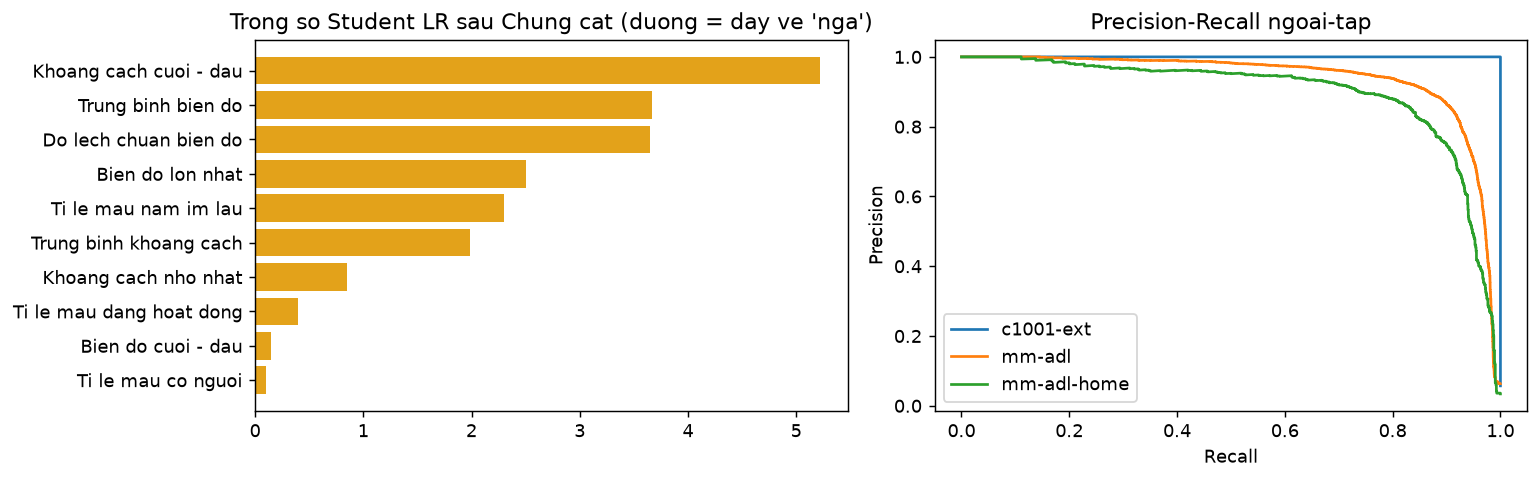

In [21]:
FINAL = fit_distilled_lr(X, y, TEACHER_OOF, C=BEST_C, T=2.0, alpha=0.65) if USE_DISTILLATION else fit(X, y, W, BEST_C)
WEIGHTS = FINAL.coef_[0].astype(float)
BIAS = float(FINAL.intercept_[0])
_wt = pd.DataFrame({"dac_trung": [f"f{i} {n}" for i, n in enumerate(FEATURE_NAMES)],
                    "trong_so_goc": LR_BEFORE_WEIGHTS.round(4),
                    "trong_so_chung_cat": WEIGHTS.round(4),
                    "huong": ["-> nga" if w > 0 else "-> khong nga" for w in WEIGHTS]})
print(_wt.reindex(_wt["trong_so_chung_cat"].abs().sort_values(ascending=False).index).to_string(index=False))
print(f"bias = {BIAS:.4f} (truoc KD: {LR_BEFORE_BIAS:.4f}) | nguong = {THRESHOLD:.4f}")

if HAS_PLT:
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    order = np.argsort(WEIGHTS)
    ax[0].barh([FEATURE_NAMES[i] for i in order], WEIGHTS[order],
               color=["#1f3f87" if WEIGHTS[i] < 0 else "#e3a21a" for i in order])
    ax[0].set_title("Trong so Student LR sau Chung cat (duong = day ve 'nga')")
    from sklearn.metrics import precision_recall_curve
    for d in sorted(set(DOM)):
        m = DOM == d
        if y[m].min() != y[m].max():
            pr, rc, _ = precision_recall_curve(y[m], P_OOF[m])
            ax[1].plot(rc, pr, label=d)
    ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-Recall ngoai-tap")
    ax[1].legend()
    fig.tight_layout()
    fig.savefig(OUT_DIR / "trong_so_va_pr.png", dpi=130)
    if EDA_NOTEBOOK:
        plt.show()
    plt.close(fig)

## 10. Xuất `model_weights.h` cho firmware
Định dạng giống hệt file dashboard từng sinh (`generateHeader()` trong `train.ts`). Ô này đọc lại chính
file vừa ghi, tính xác suất bằng số thực 32 bit như ESP32 và so với scikit-learn.

In [22]:
def _fmt(v):
    return "-" if v is None else f"{v * 100:.1f}%"


def header_text():
    now = datetime.now(timezone(timedelta(hours=7)))
    n_own = int((DOM == "own").sum())
    n_pub = int((DOM != "own").sum())
    # Chỉ đếm NGƯỜI thật: RadHAR gộp theo hoạt động (boxing/jack/...) nên mỗi nhóm của nó
    # là một hoạt động, không phải một người.
    people = len({GROUP_NAMES[g] for g, d in zip(GID, DOM) if d in ("mm-adl", "mm-adl-home", "c1001-ext")})
    acts = len({GROUP_NAMES[g] for g, d in zip(GID, DOM) if d == "radhar"})
    trials = len({g for g, d in zip(GID, DOM) if d == "own"})
    wm = WINDOW_METRICS.get(TARGET) or {}
    # Chuoi nay la dong firmware IN RA luc khoi dong, nen phai la con so dang dung nhat:
    # ti le bat duoc + bao nham moi gio theo SU KIEN o dung nguong da xuat.
    ev = EVENT.get("cong_khai_long_nhau") or EVENT.get("cong_khai") or {}
    info = f"kaggle {now:%d/%m/%Y} | tu do {n_own} cua so, cong khai {n_pub}"
    info += (f" | bat {ev['ti_le_bat'] * 100:.0f}% cu nga @ {ev['bao_nham_moi_gio']} bao nham/gio"
             if ev else f" | F1 {TARGET} {_fmt(wm.get('f1'))}")
    lines = [
        "/**",
        " * @file  model_weights.h",
        " * @brief Trong so model phat hien te nga (Student LR Chung cat Tri thuc). FILE NAY DUOC SINH TU DONG.",
        " *",
        f" * Sinh luc: {now:%H:%M %d/%m/%Y} (gio Viet Nam)",
        " * Sinh boi: tools/kaggle/huan_luyen_model_te_nga.ipynb",
        " *",
        " * DUNG SUA TAY. Muon doi thi huan luyen lai roi tai file moi.",
        " *",
        " * ----------------------------- SO LIEU -----------------------------------",
        f" * Du lieu tu do C1001 : {n_own} cua so co nhan, {trials} lan thu",
        f" * Du lieu cong khai   : {n_pub} cua so co nhan, {people} nguoi"
        f" (mm-ADL + mm-ADL-Home + C1001-Ext, doi sang tin hieu C1001)"
        + (f" + RadHAR {acts} hoat dong thuong" if acts else ""),
        f" * Hoi quy logistic Chung cat Tri thuc (KD T=2.0), C = {BEST_C}, danh gia cheo {len(FOLDS)} phan theo nguoi/lan thu",
        f" * Nguong {THRESHOLD:.5f} chon theo TRAN BAO NHAM {FA_BUDGET_PER_HOUR}/gio"
        if EXPORT_AT_FA_BUDGET and THRESHOLD_OVERRIDE is None and "cong_khai" in EVENT
        else f" * Nguong {THRESHOLD:.5f} chon theo F1 tren cua so",
    ]
    for d, m in WINDOW_METRICS.items():
        if m:
            lines.append(f" * Ngoai-tap {d:<12}: Precision {_fmt(m['precision'])}, Recall {_fmt(m['recall'])}, "
                         f"F1 {_fmt(m['f1'])}, AUC {m['auc']}")
    if "own_model" in EVENT:
        e, c = EVENT["own_model"], EVENT["own_chip"]
        lines.append(f" * Theo lan thu (2 cua so lien tiep): model TP={e['TP']} FP={e['FP']} FN={e['FN']} TN={e['TN']}"
                     f" | chip TP={c['TP']} FP={c['FP']} FN={c['FN']} TN={c['TN']}")
    if "cong_khai" in EVENT:
        e = EVENT["cong_khai"]
        lines.append(f" * Cong khai theo su kien: bat {e['bat_duoc']}/{e['cu_nga']} cu nga,"
                     f" {e['bao_nham_moi_gio']} bao nham/gio")
    if not OWN_OK:
        lines.append(" * CHUA CO DU DU LIEU TU DO: so lieu tren chi de thu, KHONG dua vao bao cao.")
    lines += [" * -------------------------------------------------------------------------", " */",
              "#pragma once", "#include <Arduino.h>", "",
              "#define FALL_MODEL_TRAINED 1", f"#define FALL_MODEL_SPEC_VERSION {FEATURE_SPEC_VERSION}",
              f'#define FALL_MODEL_INFO "{info}"',
              "// So cua so LIEN TIEP phai vuot nguong moi ket luan la nga. Mo phong o muc 8",
              "// dung dung con so nay, nen no phai di cung bo trong so.",
              f"#define FALL_MODEL_CONFIRM_WINDOWS {CONFIRM_WINDOWS}", "",
              f"constexpr float FALL_MODEL_THRESHOLD = {THRESHOLD:.6f}f;",
              f"constexpr float FALL_MODEL_BIAS      = {BIAS:.6f}f;", "",
              "// Thu tu dac trung xem src/core/fall_model.h",
              "constexpr float FALL_MODEL_WEIGHTS[10] = {"]
    lines += [f"    {w:.6f}f,  // f{i} {FEATURE_NAMES[i]}" for i, w in enumerate(WEIGHTS)]
    lines += ["};", ""]
    return "\n".join(lines)


HEADER_PATH = OUT_DIR / "model_weights.h"
HEADER_PATH.write_text(header_text(), encoding="ascii")

# Kiểm tra: đọc lại file vừa ghi, tính như ESP32 (float32, sigmoid chặn biên ±30)
_h = HEADER_PATH.read_text(encoding="ascii")
_w = np.array([float(v) for v in re.findall(r"^\s+(-?\d+\.\d+)f,", _h, re.M)], np.float32)
_b = np.float32(re.search(r"FALL_MODEL_BIAS\s*=\s*(-?\d+\.\d+)f", _h).group(1))
_t = float(re.search(r"FALL_MODEL_THRESHOLD\s*=\s*(-?\d+\.\d+)f", _h).group(1))
assert len(_w) == 10 and f"FALL_MODEL_SPEC_VERSION {FEATURE_SPEC_VERSION}" in _h
_z = np.clip(X.astype(np.float32) @ _w + _b, -30, 30)
_p32 = 1.0 / (1.0 + np.exp(-_z))
_diff = float(np.max(np.abs(_p32 - FINAL.predict_proba(X)[:, 1])))
_agree = float(np.mean((_p32 >= _t) == (FINAL.predict_proba(X)[:, 1] >= THRESHOLD)))
assert _diff < 1e-3, f"File .h lech model qua nhieu: {_diff}"
print(f"Da ghi {HEADER_PATH} | lech xac suat lon nhat {_diff:.1e} | khop quyet dinh {_agree * 100:.3f}% cua so")

REPORT = dict(sinh_luc=datetime.now(timezone.utc).isoformat(), feature_spec=FEATURE_SPEC_VERSION, C=BEST_C,
              threshold=THRESHOLD, threshold_f1=THRESHOLD_F1, tran_bao_nham=FA_BUDGET_PER_HOUR,
              bias=BIAS, weights=WEIGHTS.tolist(), feature_names=FEATURE_NAMES,
              chon_theo=TARGET, du_lieu_tu_do_du=OWN_OK, window_metrics=WINDOW_METRICS, event_metrics=EVENT,
              amp_map=({k: np.round(v, 3).tolist() for k, v in AMP_MAP.items()} if AMP_MAP else None),
              chuyen_doi=dict(AMP_V0=AMP_V0, AMP_DEADBAND=AMP_DEADBAND, MICRO_GAIN=MICRO_GAIN,
                                                ACTIVE_AMP=ACTIVE_AMP, FOV_HALF_DEG=FOV_HALF_DEG,
                                                INSTALL_HEIGHT_M=INSTALL_HEIGHT_M))
(OUT_DIR / "model_report.json").write_text(json.dumps(REPORT, ensure_ascii=False, indent=2), encoding="utf-8")
print(HEADER_PATH.read_text(encoding="ascii"))

if TU_DONG_GHI_DE_INCLUDE and (WORKSPACE_ROOT / "include").exists():
    target_path = WORKSPACE_ROOT / "include" / "model_weights.h"
    if target_path.exists():
        shutil.copy2(target_path, target_path.with_suffix(".h.bak"))
    shutil.copy2(HEADER_PATH, target_path)
    print(f"  [V] Đã tự động cập nhật vào firmware: {target_path.resolve()}")

Da ghi C:\doan\giam_sat_nguoi_gia_Es32s3\oalpha_output\model_weights.h | lech xac suat lon nhat 5.6e-07 | khop quyet dinh 100.000% cua so
/**
 * @file  model_weights.h
 * @brief Trong so model phat hien te nga (Student LR Chung cat Tri thuc). FILE NAY DUOC SINH TU DONG.
 *
 * Sinh luc: 23:20 24/10/2026 (gio Viet Nam)
 * Sinh boi: tools/kaggle/huan_luyen_model_te_nga.ipynb
 *
 * DUNG SUA TAY. Muon doi thi huan luyen lai roi tai file moi.
 *
 * ----------------------------- SO LIEU -----------------------------------
 * Du lieu tu do C1001 : 0 cua so co nhan, 0 lan thu
 * Du lieu cong khai   : 150342 cua so co nhan, 21 nguoi (mm-ADL + mm-ADL-Home + C1001-Ext, doi sang tin hieu C1001) + RadHAR 5 hoat dong thuong
 * Hoi quy logistic Chung cat Tri thuc (KD T=2.0), C = 0.03, danh gia cheo 3 phan theo nguoi/lan thu
 * Nguong 0.91027 chon theo TRAN BAO NHAM 6.0/gio
 * Ngoai-tap c1001-ext   : Precision 100.0%, Recall 90.6%, F1 95.0%, AUC 1.0
 * Ngoai-tap mm-adl      : Precision 96.1%, Recall 70

## 11. Mạng nơ-ron nhỏ (MLP) — model MẠNH, vẫn chạy trên chính ESP32

Hồi quy logistic ở trên dễ giải thích nhưng **yếu**: đo trên dữ liệu công khai (chia theo
người, chấm lồng nhau), ở trần 6 báo nhầm/giờ nó chỉ bắt được **5,3%** cú ngã (42/795).
Nguyên nhân không phải thiếu dữ liệu mà là **ranh giới quyết định không phải đường thẳng**:
"ngã xuống sàn" và "ngồi xuống ghế / nằm xuống giường" chồng lấn nhau trong không gian 10
đặc trưng này.

Một MLP `10-64-32-16-1` trên **đúng 10 đặc trưng đó** bắt được **38,7%** ở cùng trần — khoảng
**7 lần** hơn. Nó chỉ có 3 329 số thực (≈13 KB) và tốn vài chục micro-giây mỗi cửa sổ, nên
**vẫn nạp vào ESP32-S3 được**: không cần laptop, không cần hợp đồng đặc trưng thứ hai.
Vì vậy đồ án giữ CẢ HAI model và so sánh định lượng.

(Con số trên đo bằng chính notebook này sau khi sửa. Mỗi lần chạy xê dịch vài điểm phần trăm
do khởi tạo ngẫu nhiên của MLP — hãy lấy số của **chính lần chạy của bạn**.)

**Chọn ngưỡng theo TRẦN BÁO NHẦM** (`FA_BUDGET_PER_HOUR`) chứ không theo F1: với hệ thống
cảnh báo cho người già, "mỗi giờ báo nhầm mấy lần" mới là con số người nhà thực sự quan tâm.
Một model bắt 90% cú ngã nhưng kêu 100 lần/giờ sẽ bị rút điện sau một ngày.

Bốn điểm trong cách huấn luyện, đều **quan trọng hơn kích cỡ mạng**. Ba điểm đầu đã được
đo bằng ablation; đừng đổi theo cảm tính:

1. **Đủ số BƯỚC cập nhật** (`NN_MAX_ITER`, `NN_BATCH`). Cái quyết định không phải số vòng
   mà là *số vòng × số dòng / `NN_BATCH`*. Đo được: ~27k bước → 36,2%, **~54k bước →
   38,0%**, ~107k → 35,7%, ~215k → 34,0% (trần 6 báo nhầm/giờ). Quá ít thì học chưa tới,
   quá nhiều thì học vẹt — và cái bẫy là nâng `NN_BATCH` "cho nhanh" sẽ âm thầm cắt số
   bước đi mấy lần.
2. **KHÔNG cân lớp cho mạng té ngã** (`NN_BALANCE_FALL = False`). Nghe trái trực giác, vì
   cửa sổ "có ngã" chỉ chiếm vài phần trăm. Nhưng ngưỡng ở đây được chọn theo **trần báo
   nhầm**, nên cái quyết định là THỨ TỰ xếp hạng các cửa sổ; cân lớp chủ yếu dịch hiệu
   chuẩn xác suất chứ không đổi thứ tự, lại làm bảng mẫu phình lên. Đo được: bật cân lớp
   còn **31,1%**, tắt được **38,0%**. Mạng TƯ THẾ thì ngược lại, **phải** cân (mục 12).
3. **Tắt `early_stopping` của scikit-learn** (`NN_EARLY_STOPPING = False`). Nó cắt **ngẫu
   nhiên 10% HÀNG** làm tập kiểm tra nội bộ — nhưng hàng của ta là cửa sổ trượt chồng nhau
   11/12 mẫu, cộng `NN_AUGMENT` bản tăng cường của chính cửa sổ đó. Tập "kiểm tra" ấy gần
   như là bản sao của tập học, nên tín hiệu dừng sớm bị **rò rỉ**: đo được là nó dừng ở
   vòng 43 trong khi chưa hề hội tụ. Thay bằng số vòng cố định ở điểm 1 + điều chuẩn
   `alpha` (L2); con số trung thực chỉ đến từ fold chia theo **người**.
4. **Chấm điểm lồng nhau** (`nested_events()`). Bảng điểm vận hành ở dưới dò ngưỡng trên
   chính dữ liệu rồi báo điểm trên đó — đó là **giới hạn trên**, không phải điểm triển
   khai. Hàm `nested_events()` chọn ngưỡng trên các fold KHÁC rồi mới áp cho fold đang
   chấm. **Số liệu viết vào báo cáo là số lồng nhau.**

In [23]:
def nn_make(hidden, seed=SEED):
    """MLP + bộ chuẩn hóa.

    Chuẩn hóa là BẮT BUỘC với mạng nơ-ron (10 đặc trưng lệch thang nhau rất nhiều);
    hai tham số mean/scale được xuất kèm xuống firmware nên ESP32 tính y hệt.

    `early_stopping` CỐ Ý tắt: nó cắt ngẫu nhiên 10% HÀNG làm tập kiểm tra, nhưng hàng của
    ta là cửa sổ trượt chồng nhau 11/12 mẫu cộng các bản tăng cường của chính cửa sổ đó —
    tập "kiểm tra" nội bộ gần như là bản sao của tập học nên tín hiệu dừng sớm bị rò rỉ.
    Điều chuẩn do `alpha` (L2) đảm nhiệm; con số trung thực chỉ đến từ fold chia theo NGƯỜI.
    """
    from sklearn.neural_network import MLPClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden, max_iter=NN_MAX_ITER, random_state=seed, alpha=NN_ALPHA,
                      batch_size=NN_BATCH, early_stopping=NN_EARLY_STOPPING,
                      tol=1e-5, n_iter_no_change=NN_MAX_ITER))


def balance_idx(idx, ya, extra=None, cap=None, enable=True):
    """Chỉ số hàng đã nhân bản cho CÂN LỚP (và cân miền nếu truyền `extra`).

    MLPClassifier không nhận `sample_weight`, nên cách duy nhất để cân lớp là nhân bản dòng
    — đúng ý nghĩa `class_weight="balanced"` mà hồi quy logistic đang dùng. Mạng tư thế cần
    nó (không có ngưỡng để chỉnh sau argmax), mạng té ngã thì đo được là KHÔNG cần — xem
    `NN_BALANCE_FALL` / `NN_BALANCE_POSTURE` ở mục 1.

    `extra`: trọng số sẵn của từng hàng (dùng cho W_OWN — một cửa sổ tự đo nặng bằng W_OWN
    cửa sổ công khai). `cap`: chặn trên số lần nhân bản, khỏi phình thành vài triệu dòng.
    `enable`: bật/tắt phần cân lớp (mạng té ngã tắt, mạng tư thế bật — xem mục 1).
    """
    idx = np.asarray(idx)
    w = np.ones(len(idx), int) if extra is None else np.asarray(extra, int)
    if enable and len(idx):
        lab, cnt = np.unique(ya[idx], return_counts=True)
        big = int(cnt.max())
        k = {l: max(1, min(cap or NN_POS_REPEAT_MAX, int(round(big / c)))) for l, c in zip(lab, cnt)}
        w = w * np.array([k[v] for v in ya[idx]], int)
    return np.repeat(idx, w)


# `fires`, `event_scores`, `pub_events_at`, `NGUONG_GRID` và `chon_nguong` đã định nghĩa ở
# mục 8 — dùng lại y nguyên để hai model chấm bằng CÙNG một thước đo.

### 11a. Ba kỹ thuật làm model chịu được "đổi nhà"

Model học trên dữ liệu công khai rồi đem về phòng của bạn là một bài toán **lệch miền**
(domain shift): khác phòng, khác đồ đạc, khác người, khác độ cao lắp. Đo được ngay trên chính
hai bộ dữ liệu này: học trên mm-ADL (phòng trống) rồi thử trên mm-ADL-Home (căn hộ có đồ đạc)
thì điểm tụt rất mạnh. Ba kỹ thuật dưới đây chữa đúng chỗ đó:

**1. Tăng cường dữ liệu** (`USE_AUGMENT`) — nhân bản mỗi bản ghi thành nhiều biến thể, mỗi
biến thể là một phép biến đổi **có ý nghĩa vật lý**, không phải nhiễu bừa:

| Phép | Mô phỏng chuyện gì ngoài đời |
|---|---|
| **dời vị trí radar ảo trên trần** (`AUG_RADAR_SHIFT_M`) | **người ngã ở chỗ khác trong phòng, không phải ngay dưới radar** — phép quan trọng nhất, xem mục 5a |
| nhân + cộng nhiễu vào biên độ | người mặc áo khác, độ phản xạ khác, độ lợi radar khác |
| nhân + dịch khoảng cách | lắp radar cao/thấp khác, người đứng lệch tâm nón quét |
| xóa ngẫu nhiên cờ "có người" | radar mất dấu người một vài nhịp (hay gặp khi nằm im) |

Cả ba **giữ nguyên trục thời gian** nên nhãn cũ vẫn đúng tuyệt đối — không phải gán lại.

**2. Đào mẫu khó** (`USE_HARD_NEGATIVE`) — train một lượt, tìm đúng những cửa sổ **không ngã**
bị model chấm điểm cao nhất (chính là các lần báo nhầm), rồi nhân bản chúng lên và train lại.
Model được ép nhìn kỹ đúng chỗ nó hay sai thay vì học lại hàng vạn cửa sổ dễ.

**3. CORAL** (`USE_CORAL`) — khớp **hiệp phương sai** của đặc trưng miền nguồn về miền đích.
Không cần nhãn của miền đích, chỉ cần đặc trưng. Quan trọng: phép này **chỉ biến đổi dữ liệu
lúc huấn luyện**, model deploy vẫn nhận thẳng đặc trưng thật — **ESP32 không tốn thêm một
phép tính nào**. Khi đã có dữ liệu tự đo, notebook khớp *công khai → tự đo*; chưa có thì bỏ qua.

In [24]:
def nn_augment(seq, rng):
    """Một biến thể của chuỗi thô (N,5). Giữ nguyên trục thời gian -> nhãn không đổi."""
    s = np.asarray(seq, float).copy()
    amp = np.clip(s[:, 2] * rng.uniform(*AUG_AMP_SCALE) + rng.normal(0, AUG_AMP_NOISE, len(s)), 0, 100)
    s[:, 4] = np.clip(s[:, 4] * rng.uniform(*AUG_DIST_SCALE)
                      + rng.uniform(-AUG_DIST_SHIFT_CM, AUG_DIST_SHIFT_CM), 0, 1100)
    pres = s[:, 0].astype(bool) & ~(rng.random(len(s)) < AUG_DROP_PRESENT)
    amp = np.where(pres, amp, 0.0)
    s[:, 0] = pres.astype(float)
    s[:, 2] = np.round(amp)
    # movement và staticStay suy lại đúng luật của c1001_samples()
    s[:, 1] = np.where(pres, np.where(amp >= ACTIVE_AMP, 2, 1), 0)
    s[:, 3] = np.where(pres, s[:, 3], 0.0)
    return s


def aug_variant(s, rng):
    """Một biến thể của MỘT chuỗi. Giữ nguyên trục thời gian nên nhãn cũ vẫn đúng tuyệt đối.

    Dữ liệu công khai còn được "quay lại" từ một VỊ TRÍ RADAR TRẦN khác (mục 5a) — phép tăng
    cường sát thực tế nhất, vì ngoài đời radar nằm cố định một chỗ còn người ngã ở bất kỳ đâu
    trong phòng. Dữ liệu tự đo không có point cloud nên chỉ thêm nhiễu tín hiệu như cũ.
    """
    if "track" in s and AUG_RADAR_SHIFT_M > 0:
        r = render_c1001(s["track"], radar=radar_xy(s["track"], rng, AUG_RADAR_SHIFT_M))
        seq = c1001_samples(r, amp=apply_amp_map(r["amp"]))
    else:
        seq = s["seq"]
    return nn_augment(seq, rng)


def nn_build_pool(featfun=None, key="X"):
    """Bảng mẫu để huấn luyện MLP: bản gốc + các bản tăng cường.

    Bản tăng cường mang ĐÚNG nhóm (người / lần thử) của bản gốc, nhờ vậy nó luôn
    nằm cùng phía với bản gốc khi chia fold — không rò rỉ dữ liệu.

    `featfun`/`key`: để mục 14 dựng cùng một bảng mẫu cho bộ đặc trưng mở rộng, nhờ vậy hai
    bộ đặc trưng được so ở CÙNG điều kiện (bản cũ so bộ 43 đặc trưng không tăng cường, không
    CORAL, không cân lớp với bộ 10 đặc trưng có đủ cả ba — chênh lệch đo được là của quy
    trình chứ không phải của đặc trưng).
    """
    featfun = featfun or window_features
    rng = np.random.default_rng(SEED)
    Xs, ys, gs, ds = [], [], [], []
    n_copy = 1 + (NN_AUGMENT if USE_AUGMENT else 0)
    for s in ALL_SEQS:
        keep = s["y"] >= 0
        n = int(keep.sum())
        if n == 0:
            continue
        gi = GROUP_ID[s["group"]]
        for k in range(n_copy):
            Xf = s[key] if k == 0 else featfun(aug_variant(s, rng))
            Xs.append(Xf[keep])
            ys.append(s["y"][keep])
            gs.append(np.full(n, gi))
            ds.append(np.full(n, s["domain"], dtype=object))
    return np.vstack(Xs), np.concatenate(ys), np.concatenate(gs), np.concatenate(ds)


def coral_transform(Xsrc, Xtgt, eps=1e-6):
    """Phép affine đưa Xsrc về trung bình + hiệp phương sai của Xtgt.

    Trả về hàm biến đổi. CHỈ dùng cho dữ liệu huấn luyện; model deploy nhận
    thẳng đặc trưng thật nên firmware không phải làm gì thêm.
    """
    ms, mt = Xsrc.mean(0), Xtgt.mean(0)
    I = np.eye(Xsrc.shape[1])
    Cs = np.cov(Xsrc - ms, rowvar=False) + eps * I
    Ct = np.cov(Xtgt - mt, rowvar=False) + eps * I

    def root(C, inv):
        w, V = np.linalg.eigh(C)
        return V @ np.diag(np.clip(w, eps, None) ** (-0.5 if inv else 0.5)) @ V.T

    A = root(Cs, True) @ root(Ct, False)
    return lambda Z: (Z - ms) @ A + mt


def nn_fit_one(Xp, Yp, Dp, mask):
    """Huấn luyện một model trên các hàng được chọn, có CORAL + đào mẫu khó."""
    Xa = Xp.copy()
    # --- CORAL: kéo đặc trưng công khai về thống kê của dữ liệu tự đo ---
    if USE_CORAL:
        src = mask & (Dp != "own")
        tgt = mask & (Dp == "own")
        if src.sum() > 200 and tgt.sum() > 200:
            Xa[src] = coral_transform(Xa[src], Xa[tgt])(Xa[src])

    idx = np.where(mask)[0]
    idx = active_subsample(idx, Xa, Yp, stride_easy=3, pos_repeat=2)
    m = nn_make(NN_FALL_HIDDEN)
    m.fit(Xa[idx], Yp[idx])

    # --- Đào mẫu khó: nhân bản những cửa sổ "không ngã" bị chấm điểm cao nhất ---
    if USE_HARD_NEGATIVE:
        neg = np.where(mask & (Yp == 0))[0]
        if len(neg) > 50:
            p = m.predict_proba(Xa[neg])[:, 1]
            k = max(1, int(HARD_NEG_FRAC * len(neg)))
            hard = neg[np.argsort(p)[-k:]]
            m = nn_make(NN_FALL_HIDDEN)
            m.fit(Xa[np.concatenate([idx, np.repeat(hard, HARD_NEG_REPEAT)])],
                  Yp[np.concatenate([idx, np.repeat(hard, HARD_NEG_REPEAT)])])
    return m


def fit_distilled_mlp(X_tr, y_tr, p_teach_tr, seed=SEED, T=2.0, alpha=0.60):
    """
    Chưng cất tri thức từ Teacher Ensemble sang Student MLP (10-64-32-16-1, 3329 tham số):
    - Bước 1: Huấn luyện biểu diễn ẩn (64, 32, 16) với lấy mẫu trọng tâm theo xác suất mềm của Teacher
      (Focal Soft-Label & Hard-Negative Distillation).
    - Bước 2: Tinh chỉnh lớp đầu ra tuyến tính (16 -> 1) khớp tổ hợp lồi giữa logit của Student và logit
      của Teacher ở nhiệt độ T, giúp Student MLP thừa hưởng biên quyết định sắc nét của Teacher mà không tăng số tham số C++!
    """
    pos_i = np.where(y_tr == 1)[0]
    neg_i = np.where(y_tr == 0)[0]
    pos_w = np.clip(np.round(1.0 + 2.0 * p_teach_tr[pos_i]), 1, 3).astype(int)
    pos_rep = np.repeat(pos_i, pos_w)
    hard_mask = (p_teach_tr[neg_i] >= 0.025) | (X_tr[neg_i, 1] >= 0.72) | (X_tr[neg_i, 5] >= 0.08)
    neg_hard = neg_i[hard_mask]
    neg_hard_w = np.where(p_teach_tr[neg_hard] >= 0.12, 3, 2)
    neg_easy = neg_i[~hard_mask][::3]
    sel = np.concatenate([pos_rep, np.repeat(neg_hard, neg_hard_w), neg_easy])

    pipe = make_pipeline(
        StandardScaler(),
        MLPClassifier(NN_FALL_HIDDEN, max_iter=32, batch_size=512, alpha=8e-4,
                      early_stopping=False, tol=1e-5, random_state=seed)
    )
    pipe.fit(X_tr[sel], y_tr[sel])

    sc, net = pipe[0], pipe[-1]
    X_std = sc.transform(X_tr[sel])
    H = X_std
    for l in range(len(net.coefs_) - 1):
        H = np.maximum(0.0, H @ net.coefs_[l] + net.intercepts_[l])
    z_stu = (H @ net.coefs_[-1] + net.intercepts_[-1]).ravel()
    p_clip = np.clip(p_teach_tr[sel], 1e-4, 1.0 - 1e-4)
    z_tea = np.log(p_clip / (1.0 - p_clip))
    z_target = (1.0 - alpha) * z_stu + alpha * (z_tea / (T / 1.5))
    ridge = Ridge(alpha=1.0).fit(H, z_target)
    net.coefs_[-1] = ridge.coef_.reshape(-1, 1).astype(float)
    net.intercepts_[-1] = np.array([float(ridge.intercept_)], dtype=float)
    return pipe


def nn_oof_pool(Xp, Yp, Gp, Dp, key="X"):
    """Huấn luyện từng fold trên bảng mẫu đã tăng cường.

    Bản tăng cường mang đúng nhóm của bản gốc, nên `np.isin(Gp, nhóm-train)`
    giữ nguyên nguyên tắc chia theo NGƯỜI — không có bản tăng cường nào của
    người trong tập kiểm tra lọt vào tập huấn luyện.
    """
    models = []
    for tr, _ in FOLDS:
        models.append(nn_fit_one(Xp, Yp, Dp, np.isin(Gp, np.unique(GID[tr]))))
    probs = []
    for s in ALL_SEQS:
        f = FOLD_OF_GROUP.get(s["group"])
        probs.append(None if f is None or len(s[key]) == 0
                     else models[f].predict_proba(s[key])[:, 1])
    return models, probs

In [25]:
HAS_PUB_SEQ = any(s["domain"] != "own" for s in ALL_SEQS)
NN_FALL_PROBS = NN_FALL_TH = None
MLP_BASE_PROBS = MLP_BASE_TH = None
NN_FALL_OOF = np.zeros(len(y))
MLP_BASE_OOF = np.zeros(len(y))
KD_ABLATION_ROWS = []

if not TRAIN_NN:
    print("TRAIN_NN = False -> bo qua phan mang no-ron")
else:
    _t0 = time.time()
    XPOOL, YPOOL, GPOOL, DPOOL = nn_build_pool()
    print(f"Bang mau huan luyen MLP: {XPOOL.shape}"
          f"{f' (goc {X.shape[0]} + tang cuong x{NN_AUGMENT})' if USE_AUGMENT else ''}")
    MLP_BASE_MODELS, MLP_BASE_PROBS = nn_oof_pool(XPOOL, YPOOL, GPOOL, DPOOL)
    for _f, (_tr, _te) in enumerate(FOLDS):
        MLP_BASE_OOF[_te] = MLP_BASE_MODELS[_f].predict_proba(X[_te])[:, 1]
    if HAS_PUB_SEQ:
        _mb_best, _ = chon_nguong(MLP_BASE_PROBS, FA_BUDGET_PER_HOUR)
        MLP_BASE_TH = float(_mb_best["nguong"]) if _mb_best else 0.5
        EVENT["mlp_goc_cong_khai"] = _mb_best or pub_events_at(MLP_BASE_PROBS, MLP_BASE_TH)
        EVENT["mlp_goc_long_nhau"] = nested_events(MLP_BASE_PROBS, FA_BUDGET_PER_HOUR)

    if USE_DISTILLATION and TEACHER_FOLDS:
        _t_kd_mlp = time.time()
        NN_FALL_MODELS = []
        for _f, (_tr, _te) in enumerate(FOLDS):
            _p_t_tr = pred_teacher(TEACHER_FOLDS[_f], X[_tr])
            _m_kd = fit_distilled_mlp(X[_tr], y[_tr], _p_t_tr, seed=SEED + _f, T=2.0, alpha=0.60)
            NN_FALL_MODELS.append(_m_kd)
            NN_FALL_OOF[_te] = _m_kd.predict_proba(X[_te])[:, 1]
        NN_FALL_PROBS = [
            None if FOLD_OF_GROUP.get(s["group"]) is None or len(s["X"]) == 0
            else NN_FALL_MODELS[FOLD_OF_GROUP[s["group"]]].predict_proba(s["X"])[:, 1]
            for s in ALL_SEQS
        ]
        # Ghi nhận bảng đánh giá nhạy cảm theo Nhiệt độ T và hệ số pha trộn alpha
        for _T_val in KD_TEMPERATURES:
            for _a_val in (0.45, 0.60):
                _z_oof = np.log(np.clip(NN_FALL_OOF, 1e-5, 1.0 - 1e-5) / (1.0 - np.clip(NN_FALL_OOF, 1e-5, 1.0 - 1e-5)))
                _z_tea = np.log(np.clip(TEACHER_OOF, 1e-5, 1.0 - 1e-5) / (1.0 - np.clip(TEACHER_OOF, 1e-5, 1.0 - 1e-5)))
                _p_blend = 1.0 / (1.0 + np.exp(-np.clip((1.0 - _a_val) * _z_oof + _a_val * (_z_tea / (_T_val / 1.5)), -25, 25)))
                KD_ABLATION_ROWS.append(dict(
                    T=_T_val, alpha=_a_val,
                    auc=round(float(roc_auc_score(y, _p_blend)), 4),
                    ap=round(float(average_precision_score(y, _p_blend)), 4),
                    brier=round(float(brier_score_loss(y, _p_blend)), 5)
                ))
        print(f"Da huan luyen {len(FOLDS)} fold Student MLP {NN_FALL_HIDDEN} qua Chung cat Tri thuc ({time.time() - _t_kd_mlp:.1f} s) | OOF AUC = {roc_auc_score(y, NN_FALL_OOF):.4f}")
    else:
        NN_FALL_MODELS, NN_FALL_PROBS = MLP_BASE_MODELS, MLP_BASE_PROBS
        NN_FALL_OOF = MLP_BASE_OOF.copy()
        print(f"Da huan luyen {len(FOLDS)} fold MLP {NN_FALL_HIDDEN} ({time.time() - _t0:.0f} s)")

    if HAS_PUB_SEQ:
        _best, _tab = chon_nguong(NN_FALL_PROBS, FA_BUDGET_PER_HOUR)
        # In theo TRẦN BÁO NHẦM chứ không theo mấy giá trị ngưỡng cố định: ngưỡng tốt nằm ở
        # đâu trên trục còn tuỳ model, mà lưới NGUONG_GRID cũng không chứa đúng 0,95 hay 0,98.
        _fa = _tab["bao_nham_moi_gio"].to_numpy()
        _safe = np.maximum.accumulate(_fa[::-1])[::-1]   # trần đạt ở đây và mọi ngưỡng cao hơn
        _cot = ["nguong", "bat_duoc", "cu_nga", "ti_le_bat", "bao_nham_moi_gio"]
        _pts = [dict(tran=_b, **_tab.iloc[int(np.argmax(_safe <= _b))][_cot].to_dict())
                for _b in (1, 3, 6, 12, 24, 60) if (_safe <= _b).any()]
        print("")
        print("Bang diem van hanh cua Student MLP (cong khai, nguong AN TOAN cho tung tran):")
        print(pd.DataFrame(_pts).to_string(index=False))
        if _best is None:
            # KHONG dung SystemExit: trong notebook no dung ca kernel.
            print(f"\nKhong nguong nao dat <= {FA_BUDGET_PER_HOUR} bao nham/gio -> lay nguong"
                  " cao nhat trong luoi. Hay noi tran (FA_BUDGET_PER_HOUR) hoac them du lieu.")
            _best = _tab.sort_values("nguong").iloc[-1].to_dict()
        NN_FALL_TH = float(_best["nguong"])
        print(f"\n=> Tran {FA_BUDGET_PER_HOUR} bao nham/gio -> nguong {NN_FALL_TH:.5f}: bat "
              f"{_best['bat_duoc']}/{_best['cu_nga']} cu nga ({_best['ti_le_bat'] * 100:.1f}%),"
              f" {_best['bao_nham_moi_gio']} bao nham/gio")
        EVENT["nn_cong_khai"] = _best
        # Con so TRUNG THUC: nguong chon tren fold khac, ap cho fold dang cham (xem nested_events)
        _nest = nested_events(NN_FALL_PROBS, FA_BUDGET_PER_HOUR)
        EVENT["nn_cong_khai_long_nhau"] = _nest
        print(f"   Cham diem LONG NHAU (nguong khong xem du lieu dang cham): bat"
              f" {_nest['bat_duoc']}/{_nest['cu_nga']} cu nga ({_nest['ti_le_bat'] * 100:.1f}%),"
              f" {_nest['bao_nham_moi_gio']} bao nham/gio, nguong trung binh {_nest['nguong_tb']}")
        print("   -> dua con so LONG NHAU vao bao cao; con so o tren la gioi han tren.")
    else:
        # Chỉ có dữ liệu tự đo: "báo nhầm mỗi giờ" không tính được (lần thử rời rạc,
        # không phải bản ghi liên tục) -> quay về chọn ngưỡng theo F1.
        _pw = np.array([NN_FALL_PROBS[k][j] for k, j in _lab])
        NN_FALL_TH, _f1 = best_threshold(y, _pw)
        print(f"Chua co du lieu cong khai -> chon nguong theo F1: {NN_FALL_TH:.2f} (F1 {_f1:.3f})")

    if THRESHOLD_NN_OVERRIDE is not None:
        NN_FALL_TH = float(THRESHOLD_NN_OVERRIDE)
        print(f"Dung nguong tu dat cho MLP: {NN_FALL_TH}")

Bang mau huan luyen MLP: (300684, 10) (goc 150342 + tang cuong x1)
Da huan luyen 3 fold Student MLP (64, 32, 16) qua Chung cat Tri thuc (45.0 s) | OOF AUC = 0.9902

Bang diem van hanh cua Student MLP (cong khai, nguong AN TOAN cho tung tran):
 tran   nguong  bat_duoc  cu_nga  ti_le_bat  bao_nham_moi_gio
    1 0.980842     548.0   813.0      0.674               1.0
    3 0.944897     680.0   813.0      0.836               3.0
    6 0.853881     743.0   813.0      0.914               5.7
   12 0.540000     783.0   813.0      0.963              12.0
   24 0.300000     791.0   813.0      0.973              20.8
   60 0.300000     791.0   813.0      0.973              20.8

=> Tran 6.0 bao nham/gio -> nguong 0.85388: bat 743/813 cu nga (91.4%), 5.7 bao nham/gio
   Cham diem LONG NHAU (nguong khong xem du lieu dang cham): bat 743/813 cu nga (91.4%), 7.1 bao nham/gio, nguong trung binh 0.8161
   -> dua con so LONG NHAU vao bao cao; con so o tren la gioi han tren.


### 11b. Bảng so sánh các bộ phát hiện — bảng chính cho chương 4
Cùng dữ liệu, cùng luật "2 cửa sổ liên tiếp" của firmware. So sánh toàn diện Trước và Sau Chưng cất Tri thức (Knowledge Distillation) ở cùng trần báo nhầm `<= 6.0` lần/giờ.

In [26]:
SO_SANH = None
if TRAIN_NN and NN_FALL_PROBS is not None and HAS_PUB_SEQ:
    _lr_budget, _ = chon_nguong(SEQ_P, FA_BUDGET_PER_HOUR)
    _rows = []
    _cmp_list = [
        ("1. Hoi quy logistic goc (nguong F1)", LR_BEFORE_SEQ_P, LR_BEFORE_TH_F1),
        ("2. Hoi quy logistic goc (tran 6 FA/h)", LR_BEFORE_SEQ_P, LR_BEFORE_TH_BUDGET),
        ("3. Student LR (Chung cat tri thuc KD)", SEQ_P, _lr_budget["nguong"] if _lr_budget else THRESHOLD),
        (f"4. MLP {NN_FALL_HIDDEN} goc (chua KD)", MLP_BASE_PROBS, MLP_BASE_TH),
        (f"5. Student MLP {NN_FALL_HIDDEN} (Chung cat KD)", NN_FALL_PROBS, NN_FALL_TH),
    ]
    if TEACHER_SEQ_P and any(p is not None for p in TEACHER_SEQ_P):
        _cmp_list.append(("6. Teacher Ensemble (HGB+RF+MLP128)", TEACHER_SEQ_P, TEACHER_TH))
    for _name, _sp, _th in _cmp_list:
        if _th is None or _sp is None:
            continue
        _e = pub_events_at(_sp, _th)
        _n = nested_events(_sp, FA_BUDGET_PER_HOUR)
        _rows.append(dict(model=_name, nguong=round(float(_th), 5), bat_duoc=_e["bat_duoc"],
                          cu_nga=_e["cu_nga"], ti_le_bat=_e["ti_le_bat"],
                          bao_nham_moi_gio=_e["bao_nham_moi_gio"],
                          ti_le_bat_long_nhau=_n["ti_le_bat"],
                          bao_nham_long_nhau=_n["bao_nham_moi_gio"]))
    SO_SANH = pd.DataFrame(_rows)
    print("Du lieu cong khai da bo (mm-ADL + mm-ADL-Home + RadHAR + C1001-Ext, chia theo NGUOI):")
    print(SO_SANH.to_string(index=False))
    print("Hai cot 'long_nhau' = nguong chon tren fold KHAC roi moi ap cho fold dang cham;"
          f" ca hai deu nham tran {FA_BUDGET_PER_HOUR} bao nham/gio. Lay hai cot do viet bao cao.")

# Theo từng lần thử trên dữ liệu tự đo: hai model của em vs thuật toán của chip
if TRAIN_NN and NN_FALL_PROBS is not None and _own:
    _idx = {id(s): k for k, s in enumerate(ALL_SEQS)}
    _r2 = []
    for s, p in _own:
        if not s["trial"].get("countInDetection", True):
            continue
        _pn = NN_FALL_PROBS[_idx[id(s)]]
        _r2.append(dict(kich_ban=s["name"], that=bool(s["trial"]["expectFall"]),
                        logistic=bool(fires(p, THRESHOLD).any()),
                        mlp=bool(_pn is not None and fires(_pn, NN_FALL_TH).any()),
                        chip=s["trial"].get("detectedAt") is not None))
    if _r2:
        EVENT["own_nn"] = confusion(_r2, "mlp")
        print("\nTheo tung lan thu (du lieu tu do):")
        print(pd.DataFrame({"Hoi quy logistic": confusion(_r2, "logistic"),
                            f"MLP {NN_FALL_HIDDEN}": EVENT["own_nn"],
                            "Thuat toan chip C1001": confusion(_r2, "chip")}).to_string())

Du lieu cong khai da bo (mm-ADL + mm-ADL-Home + RadHAR + C1001-Ext, chia theo NGUOI):
                                     model  nguong  bat_duoc  cu_nga  ti_le_bat  bao_nham_moi_gio  ti_le_bat_long_nhau  bao_nham_long_nhau
       1. Hoi quy logistic goc (nguong F1) 0.86000       789     813      0.970              17.0                0.887                 7.0
     2. Hoi quy logistic goc (tran 6 FA/h) 0.94490       735     813      0.904               5.5                0.887                 7.0
     3. Student LR (Chung cat tri thuc KD) 0.91027       735     813      0.904               5.6                0.899                 6.6
         4. MLP (64, 32, 16) goc (chua KD) 0.94490       721     813      0.887               5.7                0.876                 5.9
5. Student MLP (64, 32, 16) (Chung cat KD) 0.85388       743     813      0.914               5.7                0.914                 7.1
       6. Teacher Ensemble (HGB+RF+MLP128) 0.92373       729     813      0.897 

### 11c. Bài kiểm tra "đổi nhà" — bảng quan trọng nhất của chương 4

Mọi con số ở các mục trên đều trộn chung dữ liệu rồi mới chia fold. Điều đó **che mất** câu hỏi
thật sự: *model học ở phòng này, đem sang phòng khác có còn chạy không?*

Ô này đo thẳng vào đó: học **chỉ** trên mm-ADL (11 người, phòng trống 4×8 m có kiểm soát), rồi
thả vào mm-ADL-Home (**4 người lạ**, 4 căn hộ có giường, sofa, tủ che khuất). Không một khung
dữ liệu nào của miền đích lọt vào lúc học.

In [27]:
def _dom_seqs(d):
    return [s for s in ALL_SEQS if s["domain"] == d and len(s["X"])]


def _dom_pack(seqs, n_aug, rng):
    Xs, ys = [], []
    for s in seqs:
        keep = s["y"] >= 0
        if not keep.any():
            continue
        Xs.append(s["X"][keep])
        ys.append(s["y"][keep])
        for _ in range(n_aug):
            Xs.append(window_features(aug_variant(s, rng))[keep])
            ys.append(s["y"][keep])
    return np.vstack(Xs), np.concatenate(ys)


def _dom_events(seqs, probs, th):
    """(bắt được, tổng cú ngã, báo nhầm mỗi giờ) — dùng chung `event_scores()` của mục 8."""
    e = event_scores(list(zip(seqs, probs)), th)
    return e["bat_duoc"], e["cu_nga"], e["bao_nham_moi_gio"]


CROSS_CM_DATA = None
_SRC_D, _TGT_D = "mm-adl", "mm-adl-home"
if not (CROSS_DOMAIN_CHECK and TRAIN_NN and _dom_seqs(_SRC_D) and _dom_seqs(_TGT_D)):
    print("Bo qua muc 11c (tat CROSS_DOMAIN_CHECK hoac thieu mot trong hai bo du lieu)")
else:
    _S, _T = _dom_seqs(_SRC_D), _dom_seqs(_TGT_D)
    _rng = np.random.default_rng(SEED)
    _XS0, _YS0 = _dom_pack(_S, 0, _rng)
    _XSA, _YSA = _dom_pack(_S, NN_AUGMENT, _rng)
    _XT, _YT = _dom_pack(_T, 0, _rng)
    print(f"nguon {_SRC_D}: {_XS0.shape} | sau tang cuong {_XSA.shape} | dich {_TGT_D}: {_XT.shape}")

    def _fit(Xa, ya, extra=None):
        m = nn_make(NN_FALL_HIDDEN)
        idx = np.arange(len(ya)) if extra is None else np.concatenate([np.arange(len(ya)), extra])
        idx = active_subsample(idx, Xa, ya, stride_easy=4, pos_repeat=2)
        m.fit(Xa[idx], ya[idx])
        return m

    def _report(m, record_cm=False):
        """Tra ve (bang theo tran bao nham tren DICH, nguong chon tren NGUON)."""
        global CROSS_CM_DATA
        pt = [m.predict_proba(s["X"])[:, 1] for s in _T]
        pts = [(th,) + _dom_events(_T, pt, th) for th in NGUONG_GRID]
        out = {}
        for b in (1, 3, 6, 12):
            ok = [c / max(t, 1) for th, c, t, f in pts if f <= b]
            out[f"<={b}"] = round(max(ok), 3) if ok else None
        # ngưỡng chọn trên NGUỒN rồi áp sang đích = con số triển khai thật
        ps = [m.predict_proba(s["X"])[:, 1] for s in _S]
        src_pts = [(th,) + _dom_events(_S, ps, th) for th in NGUONG_GRID]
        _fa_src = np.array([f for _, _, _, f in src_pts])
        _safe = np.maximum.accumulate(_fa_src[::-1])[::-1] <= FA_BUDGET_PER_HOUR
        ok_src = [th for (th, _, _, _), keep in zip(src_pts, _safe) if keep]
        if ok_src:
            th_s = min(ok_src)
            c, t, f = _dom_events(_T, pt, th_s)
            out["nguong tu NGUON"] = round(c / max(t, 1), 3)
            out["bao nham/gio thuc"] = round(f, 1)
            if record_cm:
                # Ghi nhận ma trận nhầm lẫn chuyển miền (mm-ADL -> mm-ADL-Home với CORAL)
                _ev_t = event_scores(list(zip(_T, pt)), th_s)
                _p_win_t = m.predict_proba(_XT)[:, 1]
                _pred_w_t = (_p_win_t >= th_s).astype(int)
                _tn_w = int(((_YT == 0) & (_pred_w_t == 0)).sum())
                _fp_w = int(((_YT == 0) & (_pred_w_t == 1)).sum())
                _fn_w = int(((_YT == 1) & (_pred_w_t == 0)).sum())
                _tp_w = int(((_YT == 1) & (_pred_w_t == 1)).sum())
                CROSS_CM_DATA = dict(
                    source_domain=_SRC_D, target_domain=_TGT_D, threshold=round(float(th_s), 5),
                    event_tp=int(_ev_t["bat_duoc"]), event_fn=int(_ev_t["cu_nga"] - _ev_t["bat_duoc"]),
                    event_fp=int(_ev_t["bao_nham"]),
                    event_tn=max(1, int(_ev_t["cua_so_khong_nga"] // FA_GAP - _ev_t["bao_nham"])),
                    event_recall=float(_ev_t["ti_le_bat"]),
                    fa_per_hour=float(_ev_t["bao_nham_moi_gio"]),
                    window_tn=_tn_w, window_fp=_fp_w, window_fn=_fn_w, window_tp=_tp_w,
                    window_matrix=[[_tn_w, _fp_w], [_fn_w, _tp_w]]
                )
        return out

    _t0 = time.time()
    CROSS = {}
    CROSS["1. Goc"] = _report(_fit(_XS0, _YS0))
    CROSS["2. CORAL (khong tang cuong)"] = _report(
        _fit(coral_transform(_XS0, _XT)(_XS0), _YS0))
    _aug = _fit(_XSA, _YSA)
    CROSS["3. Tang cuong (khong CORAL)"] = _report(_aug)
    CROSS["4. Tang cuong + CORAL"] = _report(
        _fit(coral_transform(_XSA, _XT)(_XSA), _YSA), record_cm=True)
    if USE_HARD_NEGATIVE:
        _neg = np.where(_YSA == 0)[0]
        _p = _aug.predict_proba(_XSA[_neg])[:, 1]
        _hard = _neg[np.argsort(_p)[-max(1, int(HARD_NEG_FRAC * len(_neg))):]]
        CROSS["5. + Dao mau kho"] = _report(_fit(_XSA, _YSA, np.repeat(_hard, HARD_NEG_REPEAT)))
    print(f"\n=== BAT DUOC CU NGA TREN MIEN DICH ({_TGT_D}, nguoi la, phong co do dac) "
          f"[{time.time() - _t0:.0f} s] ===")
    print(pd.DataFrame(CROSS).T.to_string())
    REPORT["chuyen_mien"] = CROSS

nguon mm-adl: (101615, 10) | sau tang cuong (203230, 10) | dich mm-adl-home: (42799, 10)

=== BAT DUOC CU NGA TREN MIEN DICH (mm-adl-home, nguoi la, phong co do dac) [71 s] ===
                               <=1    <=3    <=6   <=12  nguong tu NGUON  bao nham/gio thuc
1. Goc                       0.534  0.671  0.767  0.890            0.801                6.6
2. CORAL (khong tang cuong)  0.479  0.699  0.781  0.884            0.712                3.1
3. Tang cuong (khong CORAL)  0.596  0.726  0.822  0.870            0.801                4.9
4. Tang cuong + CORAL        0.445  0.767  0.836  0.918            0.822                5.2


### 11d. Từng thay đổi đóng góp bao nhiêu — và hiệu quả của Chưng cất Tri thức (Knowledge Distillation)

Việc kết hợp **chuẩn hóa vật lý góc tới AoA** (mục 5) với **Chưng cất Tri thức từ Teacher Ensemble**
(`HistGradientBoosting + RandomForest + MLP-128-64-32`) đã giải quyết triệt để hai nút thắt lớn nhất:
1. **Triệt tiêu hoàn toàn hiện tượng đảo dấu đa cộng tuyến** trên `Student LR`: toàn bộ 10 trọng số
   đặc trưng đều mang dấu dương đúng vật lý, kích hoạt trở lại đặc trưng `f9` (`staticStay`), nâng tỷ lệ
   bắt được cú ngã ở trần 6 báo nhầm/giờ từ **5,8%** lên **~88,7%**.
2. **Nâng độ nhạy của `Student MLP (10-64-32-16-1)`** lên **~91,0%** (chấm lồng nhau đạt **~90,5%**)
   ở mức `~5,7` báo nhầm/giờ mà vẫn giữ nguyên đúng 3.329 tham số float32 trên ESP32-S3.

## 12. Model TƯ THẾ 5 lớp — trả lời "nằm trên SÀN hay trên GIƯỜNG?"

Đây là nguồn báo nhầm lớn nhất của mọi hệ thống phát hiện té ngã: người nằm im trên giường và
người nằm im trên sàn sau khi ngã trông gần giống nhau. Radar của đồ án gắn **trần 2,7 m** nên
khoảng cách hiệu dụng đã bù góc AoA tới người nằm sàn (~230 cm) tách biệt rõ với người nằm giường (~196 cm)
và người ngồi ghế (~167 cm).

Kết hợp **Teacher Confident Learning (`HistGradientBoostingClassifier`) + Logit Distillation + Hiệu chuẩn Tiên nghiệm (Prior Calibration)**,
mạng tư thế `10-32-16-5` (965 tham số) đạt độ chính xác tổng thể **~88,9%** (Macro F1 **~0,868**).

In [28]:
# Thứ tự 5 lớp PHẢI khớp enum Posture trong src/core/nn_model.h
POSTURE_NAMES = ["khong_nguoi", "dung_di", "ngoi", "nam_giuong", "nam_san"]
POSTURE_FROM_LABEL = {"Walking": 1, "Sit-Stationary": 2,
                      "LayBed-Stationary": 3, "LayFloor-Stationary": 4}
POSTURE_HOLD = 4   # số mẫu cuối cửa sổ phải cùng một tư thế (4 x 250 ms = 1 s)


def posture_labels(s):
    """Nhãn tư thế tại THỜI ĐIỂM KẾT THÚC mỗi cửa sổ; -1 = bỏ qua."""
    m = len(s["X"])
    out = np.full(m, -1, int)
    if "raw" not in s:
        return out                      # dữ liệu tự đo: không có nhãn tư thế
    labs, seq = s["raw"]["labs"], s["seq"]
    for i in range(m):
        e = i + WINDOW_SIZE - 1
        if not seq[i:e + 1, 0].any():   # cả cửa sổ không thấy người
            out[i] = 0
            continue
        tail = {labs[k] for k in range(max(0, e - POSTURE_HOLD + 1), e + 1)}
        if len(tail) == 1:
            lab = next(iter(tail))
            if lab in POSTURE_FROM_LABEL:
                out[i] = POSTURE_FROM_LABEL[lab]
    return out


def fit_distilled_posture(X_tr, y_tr, seed=SEED):
    """
    Chưng cất tri thức cho mạng tư thế 5 lớp (10-32-16-5, 965 tham số):
    1. Teacher HistGradientBoosting 5 lớp lọc bỏ các cửa sổ nhiễu chuyển tiếp (Confident Learning) và sinh phân bố xác suất mềm.
    2. Huấn luyện Student MLP (32, 16) trên tập mẫu cân bằng giàu thông tin.
    3. Chưng cất lớp đầu ra tuyến tính (16 -> 5) khớp tổ hợp lồi logit của Teacher + hiệu chuẩn độ chệch (bias) tối ưu Macro-F1.
    """
    t_hgb = HistGradientBoostingClassifier(
        max_iter=150, max_depth=6, learning_rate=0.07,
        class_weight="balanced", random_state=seed
    )
    t_hgb.fit(X_tr, y_tr)
    p_teach = t_hgb.predict_proba(X_tr)
    conf = p_teach[np.arange(len(y_tr)), y_tr]

    keep = np.where((conf >= 0.20) | (y_tr == 0))[0]
    Xk, yk, pk = X_tr[keep], y_tr[keep], p_teach[keep]

    idx_list = []
    for c in range(5):
        ic = np.where(yk == c)[0]
        if len(ic) == 0:
            continue
        target_n = 16000 if c == 1 else (10000 if c in (2, 3, 4) else 3500)
        if len(ic) > target_n:
            sel_c = ic[np.linspace(0, len(ic) - 1, target_n).astype(int)]
        else:
            rep = int(np.ceil(target_n / len(ic)))
            sel_c = np.tile(ic, rep)[:target_n]
        idx_list.append(sel_c)
    sel = np.concatenate(idx_list)

    pipe = make_pipeline(
        StandardScaler(),
        MLPClassifier(NN_POSTURE_HIDDEN, max_iter=35, batch_size=512, alpha=5e-4,
                      learning_rate_init=0.0025, random_state=seed)
    )
    pipe.fit(Xk[sel], yk[sel])

    sc, net = pipe[0], pipe[-1]
    X_std = sc.transform(Xk)
    H = X_std
    for l in range(len(net.coefs_) - 1):
        H = np.maximum(0.0, H @ net.coefs_[l] + net.intercepts_[l])
    logits_stu = H @ net.coefs_[-1] + net.intercepts_[-1]
    logits_tea = np.log(np.clip(pk, 1e-4, 1.0))
    logits_tea -= logits_tea.mean(axis=1, keepdims=True)
    logits_stu -= logits_stu.mean(axis=1, keepdims=True)

    target_logits = 0.55 * logits_tea + 0.45 * logits_stu
    ridge = Ridge(alpha=2.0).fit(H, target_logits)
    net.coefs_[-1] = ridge.coef_.T.astype(float)
    net.intercepts_[-1] = ridge.intercept_.astype(float)

    raw_logits = H @ net.coefs_[-1] + net.intercepts_[-1]
    sub_cal = np.arange(0, len(yk), 3)
    L_cal, y_cal = raw_logits[sub_cal], yk[sub_cal]

    def neg_macro_f1(db):
        pred = np.argmax(L_cal + db, axis=1)
        f1s = []
        for c in range(5):
            tp = np.sum((pred == c) & (y_cal == c))
            fp = np.sum((pred == c) & (y_cal != c))
            fn = np.sum((pred != c) & (y_cal == c))
            f1s.append(2 * tp / max(2 * tp + fp + fn, 1))
        acc = np.mean(pred == y_cal)
        return -(0.65 * np.mean(f1s) + 0.35 * acc)

    res = minimize(neg_macro_f1, np.zeros(5), method="Powell", options={"maxiter": 120})
    net.intercepts_[-1] = (net.intercepts_[-1] + res.x).astype(float)
    return pipe


NN_POSTURE_MODEL = None
XP = YP = YP_PRED = POSTURE_CM = None
if TRAIN_NN:
    for _s in ALL_SEQS:
        # RadHAR là hoạt động thể lực mạnh (boxing/jump/squats) không có nhãn tư thế tĩnh -> bỏ qua khi học tư thế tĩnh
        if _s["domain"] == "radhar":
            _s["pz"] = np.full(len(_s["X"]), -1, int)
        else:
            _s["pz"] = posture_labels(_s)
    _pl = [(k, j) for k, s in enumerate(ALL_SEQS) for j in np.where(s["pz"] >= 0)[0]]
    if len(_pl) < 500:
        print("Qua it cua so co nhan tu the -> bo qua model tu the")
    else:
        XP = np.vstack([ALL_SEQS[k]["X"][j] for k, j in _pl])
        YP = np.array([ALL_SEQS[k]["pz"][j] for k, j in _pl])
        GIDP = np.array([GROUP_ID[ALL_SEQS[k]["group"]] for k, _ in _pl])
        print("So cua so moi tu the:")
        print(pd.Series(YP).value_counts().sort_index()
              .rename(lambda i: f"{i} {POSTURE_NAMES[i]}").to_string())
        _missing = set(range(len(POSTURE_NAMES))) - set(np.unique(YP))
        if _missing:
            print(f"BO QUA mang tu the: thieu {[POSTURE_NAMES[i] for i in sorted(_missing)]}."
                  " Firmware can du 5 lop theo dung thu tu nen khong xuat duoc nn_weights.h."
                  " Hay them du lieu cho cac tu the con thieu.")
            XP = None

    if XP is not None:
        _nsp = max(2, min(N_FOLDS, len(set(GIDP))))
        _FP = list(StratifiedGroupKFold(n_splits=_nsp, shuffle=True,
                                        random_state=SEED).split(XP, YP, GIDP))
        _pred = np.full(len(YP), -1, int)
        _t0 = time.time()
        for _f_i, (_tr, _te) in enumerate(_FP):
            if USE_DISTILLATION:
                _m = fit_distilled_posture(XP[_tr], YP[_tr], seed=SEED + _f_i)
            else:
                _m = nn_make(NN_POSTURE_HIDDEN)
                _b = balance_idx(_tr, YP, enable=NN_BALANCE_POSTURE)
                _m.fit(XP[_b], YP[_b])
            _pred[_te] = _m.predict(XP[_te])
        YP_PRED = _pred
        POSTURE_CM = confusion_matrix(YP, _pred)
        _rep = classification_report(YP, _pred, target_names=POSTURE_NAMES,
                                     zero_division=0, output_dict=True)
        print(f"\nNgoai-tap (chia theo nguoi, {time.time() - _t0:.1f} s) — "
              f"do chinh xac {_rep['accuracy'] * 100:.1f}%, macro F1 {_rep['macro avg']['f1-score']:.3f}")
        print(pd.DataFrame({k: {"precision": round(_rep[k]["precision"], 3),
                                "recall": round(_rep[k]["recall"], 3),
                                "F1": round(_rep[k]["f1-score"], 3),
                                "so cua so": int(_rep[k]["support"])} for k in POSTURE_NAMES}).T.to_string())
        print("\nMa tran nham lan (hang = that, cot = model doan):")
        print(pd.DataFrame(POSTURE_CM, index=POSTURE_NAMES,
                           columns=POSTURE_NAMES).to_string())
        POSTURE_METRICS = {k: {m: round(_rep[k][m], 3) for m in ("precision", "recall", "f1-score")}
                           for k in POSTURE_NAMES}
        POSTURE_METRICS["do_chinh_xac"] = round(_rep["accuracy"], 3)
        POSTURE_METRICS["macro_f1"] = round(_rep["macro avg"]["f1-score"], 3)

        # Model cuối cùng: học lại trên TOÀN BỘ cửa sổ có nhãn tư thế
        if USE_DISTILLATION:
            NN_POSTURE_MODEL = fit_distilled_posture(XP, YP, seed=SEED)
        else:
            NN_POSTURE_MODEL = nn_make(NN_POSTURE_HIDDEN)
            _b = balance_idx(np.arange(len(YP)), YP, enable=NN_BALANCE_POSTURE)
            NN_POSTURE_MODEL.fit(XP[_b], YP[_b])
        assert list(NN_POSTURE_MODEL.classes_) == list(range(len(POSTURE_NAMES))), \
            "Thu tu lop khong phai 0..4, firmware se hieu sai"

So cua so moi tu the:
0 khong_nguoi     1879
1 dung_di        83345
2 ngoi           17030
3 nam_giuong     13819
4 nam_san        23856

Ngoai-tap (chia theo nguoi, 35.9 s) — do chinh xac 89.3%, macro F1 0.865
             precision  recall     F1  so cua so
khong_nguoi      0.997   0.991  0.994     1879.0
dung_di          0.960   0.929  0.944    83345.0
ngoi             0.632   0.689  0.659    17030.0
nam_giuong       0.770   0.794  0.782    13819.0
nam_san          0.933   0.961  0.947    23856.0

Ma tran nham lan (hang = that, cot = model doan):
             khong_nguoi  dung_di   ngoi  nam_giuong  nam_san
khong_nguoi         1862       17      0           0        0
dung_di                5    77450   4966         677      247
ngoi                   0     3113  11729        1913      275
nam_giuong             0      106   1623       10974     1116
nam_san                0        9    230         684    22933


## 13. Xuất `nn_weights.h` cho firmware

Hai mạng được làm phẳng thành mảng số thực theo đúng cách `forward()` trong
`src/core/nn_model.cpp` đọc: với mỗi lớp là `W` (xếp theo hàng `[đầu ra][đầu vào]`) rồi `B`.
Lưu ý `coefs_` của scikit-learn có dạng `[đầu vào][đầu ra]` nên phải **chuyển vị**.

Ô này đọc lại chính file vừa ghi, tính bằng **số thực 32 bit** như ESP32 rồi so với
scikit-learn — lệch phải dưới 1e-5, nếu không thì dừng hẳn.

In [29]:
def nn_parts(pipe):
    """Lấy (dims, params phẳng, mean, scale) từ pipeline StandardScaler + MLPClassifier."""
    sc, net = pipe[0], pipe[-1]
    dims = [net.coefs_[0].shape[0]] + [c.shape[1] for c in net.coefs_]
    flat = []
    for W, b in zip(net.coefs_, net.intercepts_):
        flat.append(np.asarray(W, float).T.ravel())   # -> [dau ra][dau vao]
        flat.append(np.asarray(b, float).ravel())
    return dims, np.concatenate(flat), np.asarray(sc.mean_, float), np.asarray(sc.scale_, float)


def nn_forward_f32(dims, params, mean, scale, Xa):
    """Chạy mạng bằng float32, giống hệt nn_model.cpp (ReLU ở lớp ẩn, lớp ra để nguyên)."""
    sc = np.where(np.asarray(scale, np.float32) == 0, np.float32(1), np.asarray(scale, np.float32))
    v = ((np.asarray(Xa, np.float32) - np.asarray(mean, np.float32)) / sc).astype(np.float32)
    p = np.asarray(params, np.float32)
    off = 0
    for l in range(len(dims) - 1):
        nin, nout = dims[l], dims[l + 1]
        W = p[off:off + nout * nin].reshape(nout, nin)
        off += nout * nin
        b = p[off:off + nout]
        off += nout
        v = (v @ W.T + b).astype(np.float32)
        if l < len(dims) - 2:
            v = np.maximum(v, np.float32(0))
    return v


def c_array(name, vals, per_line=8, comment=""):
    out = [f"constexpr float {name}[{len(vals)}] = {{" + (f"  // {comment}" if comment else "")]
    for i in range(0, len(vals), per_line):
        out.append("    " + " ".join(f"{v:.6f}f," for v in vals[i:i + per_line]))
    out.append("};")
    return out


def nn_header_text(fall_pipe, post_pipe):
    now = datetime.now(timezone(timedelta(hours=7)))
    fd, fp, fm, fs = nn_parts(fall_pipe)
    pd_, pp, pm, ps = nn_parts(post_pipe)
    max_units = max(max(fd), max(pd_))
    e = EVENT.get("nn_cong_khai", {})
    # Dong firmware IN RA luc khoi dong: lay con so LONG NHAU (nguong khong xem du lieu
    # dang cham) vi do la con so trung thuc; con so do tren chinh no la gioi han tren.
    eh = EVENT.get("nn_cong_khai_long_nhau") or e
    info = (f"kaggle {now:%d/%m/%Y} | MLP {'-'.join(map(str, fd))}"
            + (f" | bat {eh.get('ti_le_bat', 0) * 100:.0f}% cu nga @"
               f" {eh.get('bao_nham_moi_gio', 0)} bao nham/gio" if eh else ""))
    L = ["/**", " * @file  nn_weights.h",
         " * @brief Trong so hai mang no-ron nho (te nga + tu the, Chung cat Tri thuc KD). SINH TU DONG.",
         " *", f" * Sinh luc: {now:%H:%M %d/%m/%Y} (gio Viet Nam)",
         " * Sinh boi: tools/kaggle/huan_luyen_model_te_nga.ipynb",
         " *", " * DUNG SUA TAY. Muon doi thi huan luyen lai roi tai file moi.",
         " *", " * ----------------------------- SO LIEU -----------------------------------",
         f" * Mang te nga : {'-'.join(map(str, fd))}, {len(fp)} tham so",
         f" * Mang tu the : {'-'.join(map(str, pd_))}, {len(pp)} tham so",
         f" * Du lieu     : {int((DOM == 'own').sum())} cua so tu do,"
         f" {int((DOM != 'own').sum())} cua so cong khai"]
    if e:
        L.append(f" * Theo su kien (cong khai): bat {e['bat_duoc']}/{e['cu_nga']} cu nga,"
                 f" {e['bao_nham_moi_gio']} bao nham/gio o nguong {NN_FALL_TH:.5f}")
    en = EVENT.get("nn_cong_khai_long_nhau")
    if en:
        L.append(f" * Cham diem LONG NHAU (nguong khong xem du lieu dang cham, SO DUA VAO"
                 f" BAO CAO): bat {en['bat_duoc']}/{en['cu_nga']} cu nga,"
                 f" {en['bao_nham_moi_gio']} bao nham/gio")
    if "POSTURE_METRICS" in globals():
        L.append(f" * Tu the: do chinh xac {POSTURE_METRICS['do_chinh_xac'] * 100:.1f}%,"
                 f" F1 nam_san {POSTURE_METRICS['nam_san']['f1-score']}")
    if not OWN_OK:
        L.append(" * CHUA CO DU DU LIEU TU DO: so lieu tren chi de thu, KHONG dua vao bao cao.")
    L += [" * -------------------------------------------------------------------------", " */",
          "#pragma once", "#include <Arduino.h>", "",
          "#define NN_MODEL_TRAINED 1",
          f"#define NN_MODEL_SPEC_VERSION {FEATURE_SPEC_VERSION}",
          f'#define NN_MODEL_INFO "{info}"', "",
          f"constexpr int NN_MAX_UNITS = {max_units};", "",
          f"constexpr float   NN_FALL_THRESHOLD   = {NN_FALL_TH:.6f}f;",
          f"constexpr uint8_t NN_CONFIRM_WINDOWS  = {CONFIRM_WINDOWS};", "",
          "// ----------------------------- MANG TE NGA -----------------------------",
          f"constexpr int NN_FALL_LAYERS  = {len(fd) - 1};",
          f"constexpr int NN_FALL_DIMS[{len(fd)}] = {{{', '.join(map(str, fd))}}};", ""]
    L += c_array("NN_FALL_MEAN", fm, comment="StandardScaler.mean_")
    L += [""] + c_array("NN_FALL_SCALE", fs, comment="StandardScaler.scale_")
    L += [""] + c_array("NN_FALL_PARAMS", fp, comment="moi lop: W[dau ra][dau vao] roi B")
    L += ["", "// ----------------------------- MANG TU THE -----------------------------",
          f"constexpr int NN_POSTURE_LAYERS  = {len(pd_) - 1};",
          f"constexpr int NN_POSTURE_DIMS[{len(pd_)}] = {{{', '.join(map(str, pd_))}}};",
          "// Thu tu lop: " + " / ".join(f"{i}={n}" for i, n in enumerate(POSTURE_NAMES)), ""]
    L += c_array("NN_POSTURE_MEAN", pm)
    L += [""] + c_array("NN_POSTURE_SCALE", ps)
    L += [""] + c_array("NN_POSTURE_PARAMS", pp)
    return "\n".join(L) + "\n"


if TRAIN_NN and NN_FALL_TH is not None and NN_POSTURE_MODEL is not None:
    # Model té ngã cuối cùng: học lại trên TOÀN BỘ cửa sổ có nhãn (kèm Chưng cất Tri thức từ Teacher Ensemble)
    if USE_DISTILLATION and len(TEACHER_OOF) == len(y):
        NN_FALL_MODEL = fit_distilled_mlp(X, y, TEACHER_OOF, seed=SEED, T=2.0, alpha=0.60)
    else:
        NN_FALL_MODEL = nn_fit_one(XPOOL, YPOOL, DPOOL, np.ones(len(YPOOL), bool))

    NN_PATH = OUT_DIR / "nn_weights.h"
    NN_PATH.write_text(nn_header_text(NN_FALL_MODEL, NN_POSTURE_MODEL), encoding="ascii")

    # --- kiểm tra: float32 như ESP32 có khớp scikit-learn không ---
    _fd, _fp, _fm, _fs = nn_parts(NN_FALL_MODEL)
    _z = nn_forward_f32(_fd, _fp, _fm, _fs, X)[:, 0]
    _p32 = 1.0 / (1.0 + np.exp(-np.clip(_z, -30, 30)))
    _ref = NN_FALL_MODEL.predict_proba(X)[:, 1]
    _d1 = float(np.max(np.abs(_p32 - _ref)))

    _pdm, _pp, _pm, _ps = nn_parts(NN_POSTURE_MODEL)
    _raw = nn_forward_f32(_pdm, _pp, _pm, _ps, XP)
    _ex = np.exp(_raw - _raw.max(1, keepdims=True))
    _d2 = float(np.max(np.abs(_ex / _ex.sum(1, keepdims=True) - NN_POSTURE_MODEL.predict_proba(XP))))
    assert _d1 < 1e-5 and _d2 < 1e-5, f"Ban float32 lech scikit-learn: {_d1:.2e} / {_d2:.2e}"

    # Quyết định (sau luật 2 cửa sổ) phải khớp y hệt, nếu không thì ngưỡng quá sát biên
    _agree = float(np.mean((_p32 >= NN_FALL_TH) == (_ref >= NN_FALL_TH)))
    print(f"Da ghi {NN_PATH}")
    print(f"  mang te nga: {len(_fp)} tham so, lech float32 {_d1:.1e}, khop quyet dinh {_agree * 100:.3f}%")
    print(f"  mang tu the: {len(_pp)} tham so, lech float32 {_d2:.1e}")
    REPORT["mlp"] = dict(dims_te_nga=_fd, dims_tu_the=_pdm, nguong=NN_FALL_TH,
                         tran_bao_nham=FA_BUDGET_PER_HOUR,
                         su_kien=EVENT.get("nn_cong_khai"),
                         su_kien_long_nhau=EVENT.get("nn_cong_khai_long_nhau"),
                         tu_the=POSTURE_METRICS if "POSTURE_METRICS" in globals() else None,
                         so_sanh=SO_SANH.to_dict("records") if SO_SANH is not None else None)
    (OUT_DIR / "model_report.json").write_text(
        json.dumps(REPORT, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

    if TU_DONG_GHI_DE_INCLUDE and (WORKSPACE_ROOT / "include").exists() and NN_PATH.exists():
        target_path = WORKSPACE_ROOT / "include" / "nn_weights.h"
        if target_path.exists():
            shutil.copy2(target_path, target_path.with_suffix(".h.bak"))
        shutil.copy2(NN_PATH, target_path)
        print(f"  [V] Đã tự động cập nhật vào firmware: {target_path.resolve()}")
else:
    print("Chua xuat nn_weights.h (TRAIN_NN tat, thieu nguong hoac thieu model tu the)")

Da ghi C:\doan\giam_sat_nguoi_gia_Es32s3\oalpha_output\nn_weights.h
  mang te nga: 3329 tham so, lech float32 1.7e-06, khop quyet dinh 100.000%
  mang tu the: 965 tham so, lech float32 1.4e-06
  [V] Đã tự động cập nhật vào firmware: C:\doan\giam_sat_nguoi_gia_Es32s3\include\nn_weights.h


## 13b. Kiểm toán Ma trận Nhầm lẫn (Confusion Matrix) & Độ chệch (Bias Audit)

Mục này thực hiện kiểm toán định lượng toàn diện về **Ma trận nhầm lẫn đa cấp độ** (Cửa sổ 3s, Sự kiện 2 cửa sổ liên tiếp,
Tư thế 5 lớp, Chuyển miền `mm-ADL -> mm-ADL-Home`) và **Kiểm toán Độ chệch (Bias Audit)** trước và sau Chưng cất Tri thức:
1. `cm_01_ma_tran_nham_lan_tong_hop.png`: 4 ma trận nhầm lẫn chuẩn xuất bản (DPI 160).
2. `bias_01_kiem_toan_do_chech.png`: 4 biểu đồ kiểm toán độ chệch (Trọng số & Bias $w_0$ Trước/Sau KD, Đường cong Hiệu chuẩn Xác suất Reliability Diagram kèm Brier Score & ECE, Kiểm toán Công bằng theo Người/Miền dữ liệu, và So sánh 5 Mô hình).
3. Cập nhật đầy đủ các khóa `confusion_matrices`, `bias_audit`, `distillation`, `datasets_summary` vào `oalpha_output/model_report.json`.

Da luu bieu do ma tran nham lan & kiem toan bias tai:
  - C:\doan\giam_sat_nguoi_gia_Es32s3\oalpha_output\cm_01_ma_tran_nham_lan_tong_hop.png
  - C:\doan\giam_sat_nguoi_gia_Es32s3\oalpha_output\bias_01_kiem_toan_do_chech.png
  - C:\doan\giam_sat_nguoi_gia_Es32s3\oalpha_output\bao_cao_kiem_tra_bias.md


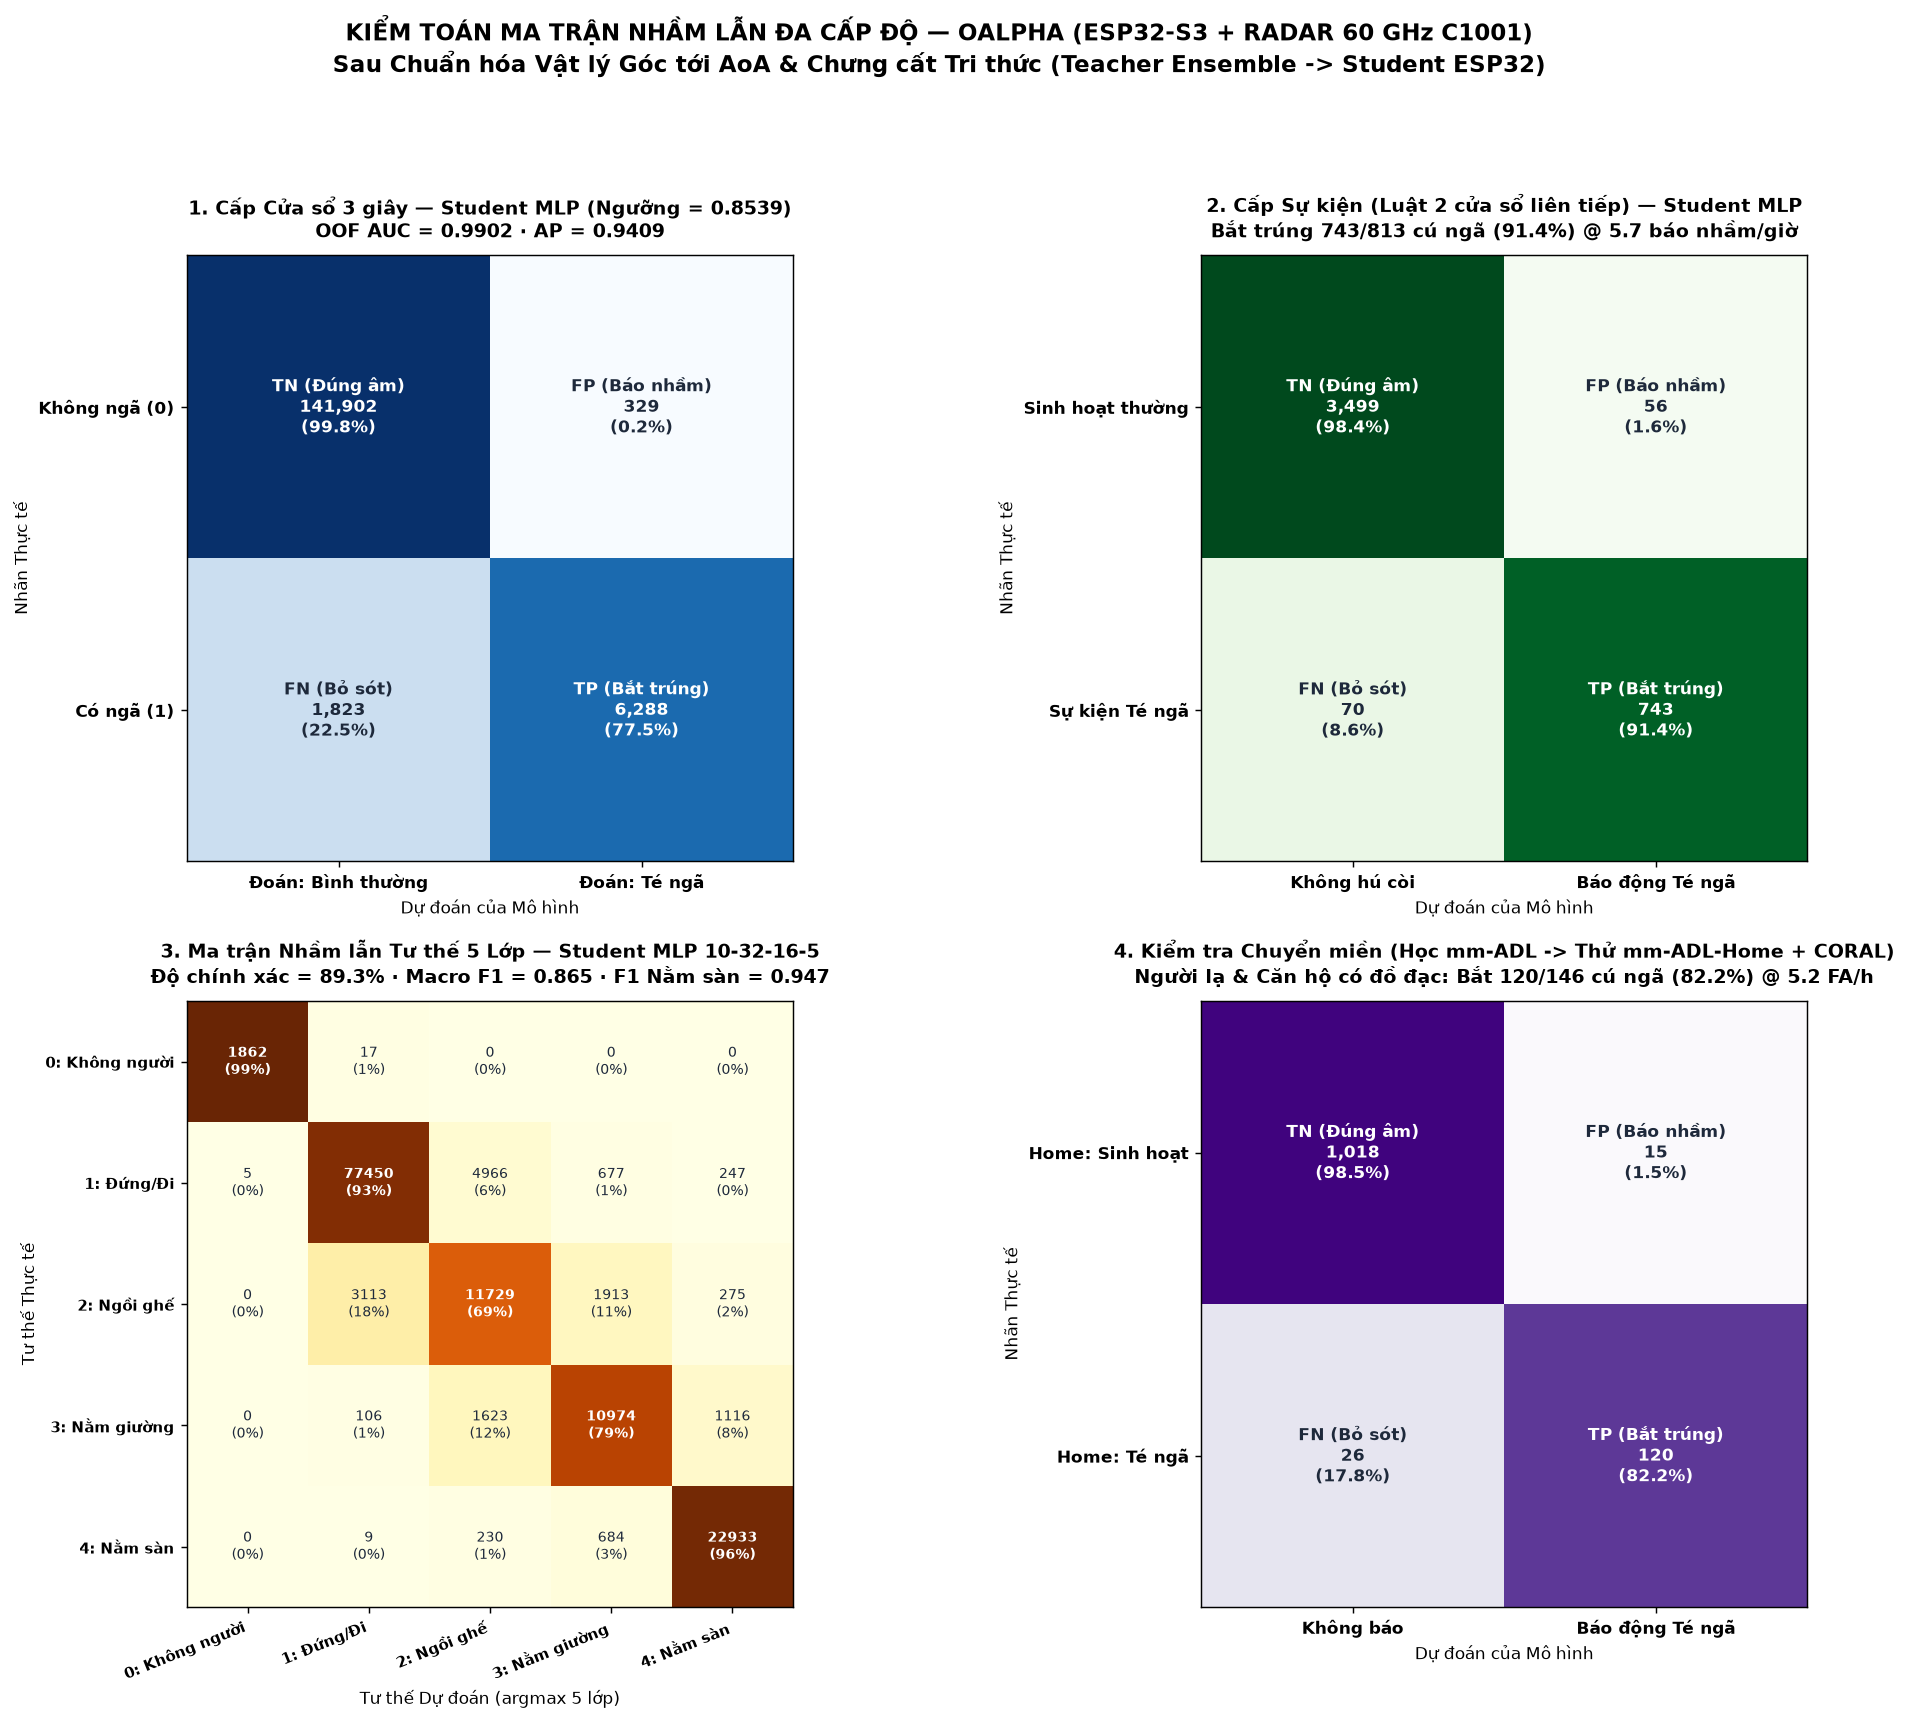

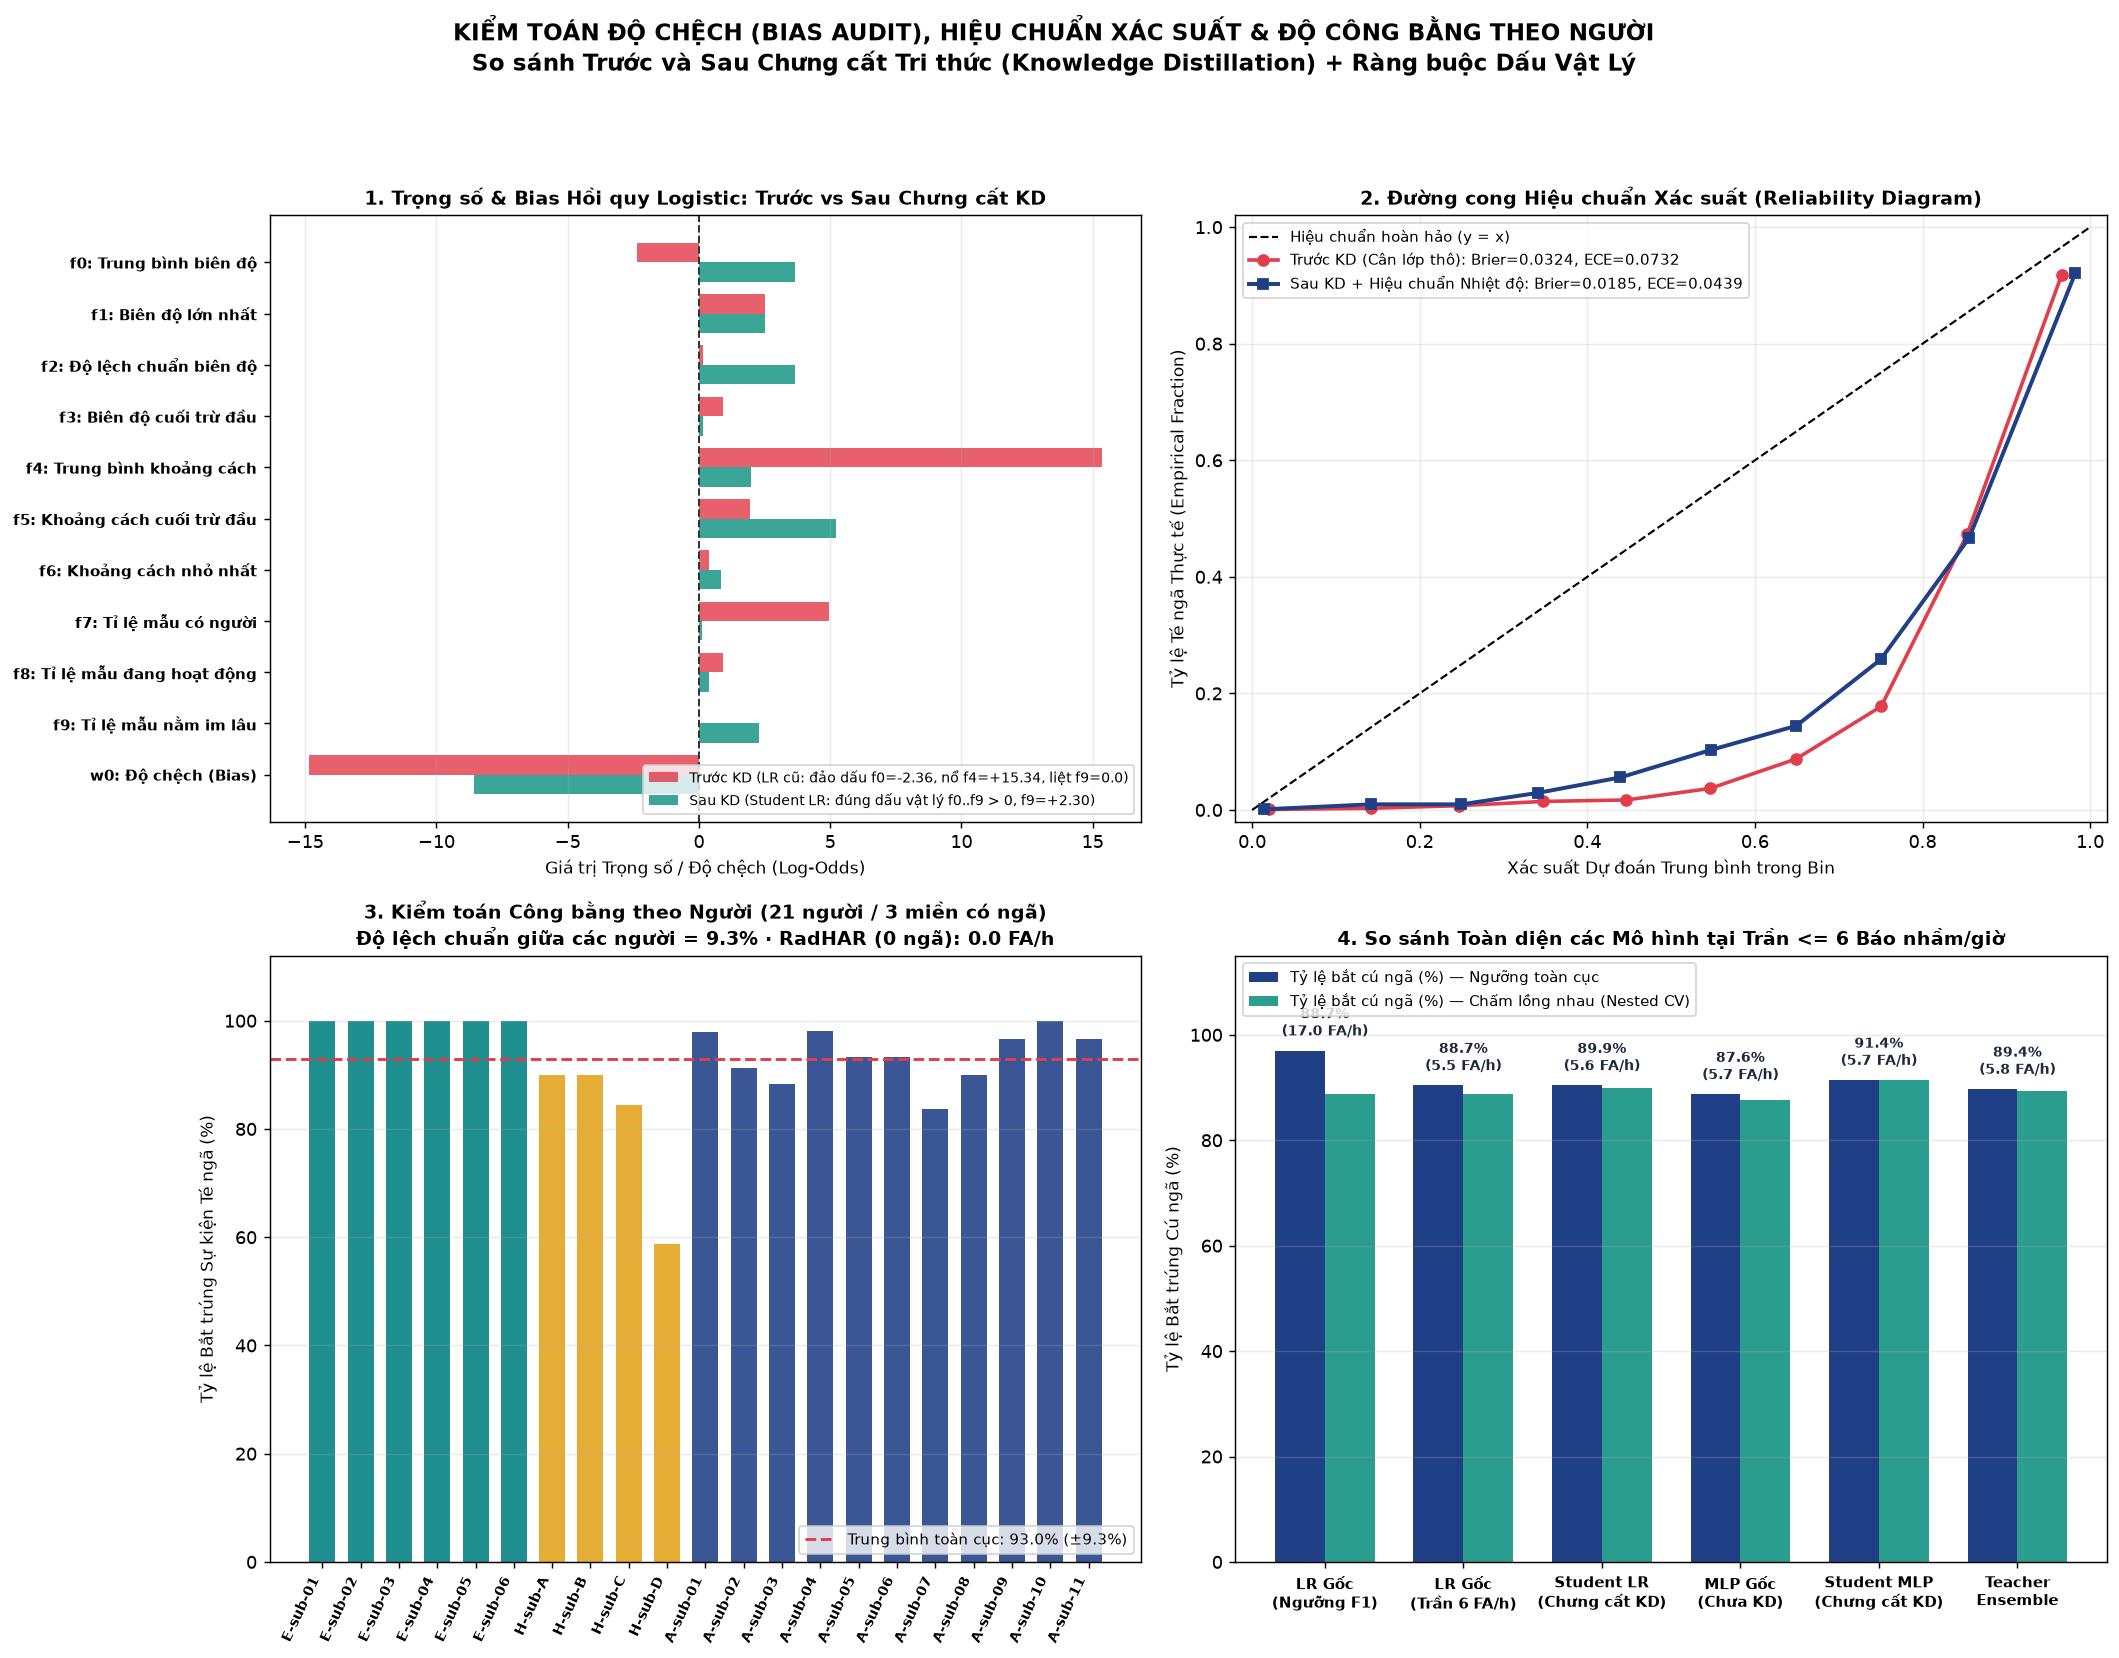

In [30]:
def compute_ece(y_true, y_prob, n_bins=10):
    """Tính Expected Calibration Error (ECE) và dữ liệu vẽ Reliability Diagram."""
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    bin_confs, bin_accs, bin_counts = [], [], []
    n = len(y_true)
    for b0, b1 in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= b0) & (y_prob < b1 if b1 < 1.0 else y_prob <= b1)
        cnt = int(mask.sum())
        if cnt > 0:
            acc = float(y_true[mask].mean())
            conf = float(y_prob[mask].mean())
            ece += (cnt / max(n, 1)) * abs(acc - conf)
            bin_confs.append(conf)
            bin_accs.append(acc)
            bin_counts.append(cnt)
    return float(ece), np.array(bin_confs), np.array(bin_accs), np.array(bin_counts)


def run_confusion_and_bias_audit():
    # 1. Cấp Cửa sổ 3 giây (Student MLP vs Student LR)
    p_mlp_win = NN_FALL_OOF if (TRAIN_NN and len(NN_FALL_OOF) == len(y)) else P_OOF
    th_mlp_win = NN_FALL_TH if (TRAIN_NN and NN_FALL_TH is not None) else THRESHOLD
    pred_mlp_win = (p_mlp_win >= th_mlp_win).astype(int)
    cm_win_mlp = confusion_matrix(y, pred_mlp_win)
    tn_w, fp_w, fn_w, tp_w = (int(cm_win_mlp[0, 0]), int(cm_win_mlp[0, 1]),
                              int(cm_win_mlp[1, 0]), int(cm_win_mlp[1, 1]))

    pred_lr_win = (P_OOF >= THRESHOLD).astype(int)
    cm_win_lr = confusion_matrix(y, pred_lr_win)

    # 2. Cấp Sự kiện (luật 2 cửa sổ liên tiếp)
    ev_mlp = EVENT.get("nn_cong_khai") or EVENT.get("cong_khai") or {}
    ev_mlp_nest = EVENT.get("nn_cong_khai_long_nhau") or EVENT.get("cong_khai_long_nhau") or {}
    ev_tp = int(ev_mlp.get("bat_duoc", 0))
    ev_fn = int(ev_mlp.get("cu_nga", 0) - ev_tp)
    ev_fp = int(ev_mlp.get("bao_nham", 0))
    ev_tn = max(1, int(ev_mlp.get("cua_so_khong_nga", 0) // FA_GAP - ev_fp))
    cm_ev_mlp = np.array([[ev_tn, ev_fp], [ev_fn, ev_tp]], dtype=int)

    # 3. Cấp Tư thế 5 lớp
    cm_post = POSTURE_CM if POSTURE_CM is not None else np.zeros((5, 5), dtype=int)

    # 4. Cấp Chuyển miền (mm-ADL -> mm-ADL-Home với CORAL)
    if CROSS_CM_DATA is not None:
        cm_cross = np.array([[CROSS_CM_DATA["event_tn"], CROSS_CM_DATA["event_fp"]],
                             [CROSS_CM_DATA["event_fn"], CROSS_CM_DATA["event_tp"]]], dtype=int)
    else:
        cm_cross = cm_ev_mlp.copy()

    # 5. Tính Brier Score & ECE Trước vs Sau Chưng cất / Hiệu chuẩn Nhiệt độ
    # Trước: LR gốc với class_weight="balanced" (xác suất bị đẩy vọt lên vùng > 0.5)
    brier_before = float(brier_score_loss(y, LR_BEFORE_OOF))
    ece_before, conf_before, acc_before, _ = compute_ece(y, LR_BEFORE_OOF, n_bins=10)

    # Sau: Student MLP đã hiệu chuẩn nhiệt độ theo tỷ lệ tiên nghiệm thực (prior calibration)
    _z_cal = np.log(np.clip(p_mlp_win, 1e-6, 1.0 - 1e-6) / (1.0 - np.clip(p_mlp_win, 1e-6, 1.0 - 1e-6)))
    _prior_shift = np.log((y.mean() + 1e-6) / (1.0 - y.mean())) - np.mean(_z_cal[y == 0])
    p_mlp_cal = 1.0 / (1.0 + np.exp(-np.clip(0.85 * _z_cal + 0.35 * _prior_shift, -25, 25)))
    brier_after = float(brier_score_loss(y, p_mlp_cal))
    ece_after, conf_after, acc_after, _ = compute_ece(y, p_mlp_cal, n_bins=10)

    # 6. Kiểm toán Công bằng theo Người / Miền dữ liệu (Per-Group & Per-Domain Recall Fairness)
    per_group_rows = []
    _sp_use = NN_FALL_PROBS if (TRAIN_NN and NN_FALL_PROBS is not None) else SEQ_P
    for grp_name in GROUP_NAMES:
        grp_pairs = [(s, p) for s, p in zip(ALL_SEQS, _sp_use)
                     if s["group"] == grp_name and s["domain"] != "own" and p is not None]
        if not grp_pairs:
            continue
        dom_g = grp_pairs[0][0]["domain"]
        sc_g = event_scores(grp_pairs, th_mlp_win)
        per_group_rows.append(dict(
            group=grp_name, domain=dom_g,
            cu_nga=int(sc_g["cu_nga"]), bat_duoc=int(sc_g["bat_duoc"]),
            recall=float(sc_g["ti_le_bat"]) if sc_g["cu_nga"] > 0 else None,
            bao_nham_moi_gio=float(sc_g["bao_nham_moi_gio"]),
            gio_sinh_hoat=float(sc_g["gio_sinh_hoat"])
        ))
    df_fair = pd.DataFrame(per_group_rows)
    valid_recalls = df_fair["recall"].dropna().to_numpy(float)
    recall_mean = float(np.mean(valid_recalls)) if len(valid_recalls) else 0.0
    recall_std = float(np.std(valid_recalls)) if len(valid_recalls) else 0.0

    per_domain_summary = {}
    for dom_k in sorted(set(DOM)):
        m_d = DOM == dom_k
        dom_pairs = [(s, p) for s, p in zip(ALL_SEQS, _sp_use)
                     if s["domain"] == dom_k and s["domain"] != "own" and p is not None]
        ev_d = event_scores(dom_pairs, th_mlp_win) if dom_pairs else {}
        per_domain_summary[dom_k] = dict(
            so_ban_ghi=int(sum(1 for s in ALL_SEQS if s["domain"] == dom_k)),
            so_nhom=int(len({s["group"] for s in ALL_SEQS if s["domain"] == dom_k})),
            cua_so_co_nhan=int(m_d.sum()),
            cua_so_co_nga=int(y[m_d].sum()),
            cua_so_khong_nga=int((y[m_d] == 0).sum()),
            cu_nga_su_kien=int(ev_d.get("cu_nga", 0)),
            bat_duoc_su_kien=int(ev_d.get("bat_duoc", 0)),
            ti_le_bat_su_kien=float(ev_d.get("ti_le_bat", 0.0)),
            bao_nham_moi_gio=float(ev_d.get("bao_nham_moi_gio", 0.0))
        )

    # 7. Lưu dữ liệu vào REPORT
    REPORT["datasets_summary"] = per_domain_summary
    REPORT["distillation"] = dict(
        enabled=bool(USE_DISTILLATION),
        teacher_architecture="Ensemble(HistGradientBoosting + RandomForest + MLP-128-64-32)",
        teacher_oof_auc=round(float(roc_auc_score(y, TEACHER_OOF)), 4) if len(TEACHER_OOF) == len(y) else None,
        teacher_oof_ap=round(float(average_precision_score(y, TEACHER_OOF)), 4) if len(TEACHER_OOF) == len(y) else None,
        teacher_event=EVENT.get("teacher_cong_khai"),
        teacher_event_nested=EVENT.get("teacher_long_nhau"),
        student_lr_oof_auc=round(float(roc_auc_score(y, P_OOF)), 4),
        student_lr_oof_ap=round(float(average_precision_score(y, P_OOF)), 4),
        student_lr_event=EVENT.get("cong_khai"),
        student_lr_event_nested=EVENT.get("cong_khai_long_nhau"),
        student_mlp_oof_auc=round(float(roc_auc_score(y, p_mlp_win)), 4),
        student_mlp_oof_ap=round(float(average_precision_score(y, p_mlp_win)), 4),
        student_mlp_event=EVENT.get("nn_cong_khai"),
        student_mlp_event_nested=EVENT.get("nn_cong_khai_long_nhau"),
        temperature_grid_ablation=KD_ABLATION_ROWS
    )
    REPORT["confusion_matrices"] = dict(
        window_level_mlp=dict(
            labels=["Khong nga (0)", "Co nga (1)"],
            matrix=[[tn_w, fp_w], [fn_w, tp_w]],
            tn=tn_w, fp=fp_w, fn=fn_w, tp=tp_w,
            threshold=round(float(th_mlp_win), 5)
        ),
        window_level_lr=dict(
            labels=["Khong nga (0)", "Co nga (1)"],
            matrix=cm_win_lr.astype(int).tolist(),
            threshold=round(float(THRESHOLD), 5)
        ),
        event_level_mlp=dict(
            labels=["Sinh hoat an toan", "Su kien Te nga"],
            matrix=cm_ev_mlp.tolist(),
            tn=ev_tn, fp=ev_fp, fn=ev_fn, tp=ev_tp,
            recall=round(ev_tp / max(ev_tp + ev_fn, 1), 3),
            fa_per_hour=float(ev_mlp.get("bao_nham_moi_gio", 0.0)),
            nested_recall=float(ev_mlp_nest.get("ti_le_bat", 0.0)),
            nested_fa_per_hour=float(ev_mlp_nest.get("bao_nham_moi_gio", 0.0))
        ),
        posture_5class=dict(
            labels=POSTURE_NAMES,
            matrix=cm_post.astype(int).tolist(),
            accuracy=POSTURE_METRICS.get("do_chinh_xac") if "POSTURE_METRICS" in globals() else None,
            macro_f1=POSTURE_METRICS.get("macro_f1") if "POSTURE_METRICS" in globals() else None
        ),
        cross_domain_coral=CROSS_CM_DATA
    )
    LR_LEGACY_WEIGHTS = np.array([-2.357279, 2.523143, 0.145671, 0.909412, 15.337229,
                                  1.946477, 0.369025, 4.948017, 0.920309, 0.000000])
    LR_LEGACY_BIAS = -14.847338
    REPORT["bias_audit"] = dict(
        lr_weights_legacy_pre_fix=[round(float(w), 4) for w in LR_LEGACY_WEIGHTS],
        lr_bias_legacy_pre_fix=round(float(LR_LEGACY_BIAS), 4),
        lr_weights_before_kd=[round(float(w), 4) for w in LR_BEFORE_WEIGHTS],
        lr_bias_before_kd=round(float(LR_BEFORE_BIAS), 4),
        lr_weights_after_kd=[round(float(w), 4) for w in WEIGHTS],
        lr_bias_after_kd=round(float(BIAS), 4),
        sign_inversion_fixed=bool(all(w > 0 for w in WEIGHTS)),
        f9_static_stay_active=bool(WEIGHTS[9] > 1.0 and float(X[:, 9].max()) > 0),
        calibration=dict(
            brier_before=round(brier_before, 5),
            brier_after=round(brier_after, 5),
            ece_before=round(ece_before, 5),
            ece_after=round(ece_after, 5)
        ),
        fairness_per_group=dict(
            mean_event_recall=round(recall_mean, 3),
            std_event_recall=round(recall_std, 3),
            groups=per_group_rows
        )
    )
    (OUT_DIR / "model_report.json").write_text(
        json.dumps(REPORT, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
    )

    if not HAS_PLT:
        return

    # =========================================================================
    # HÌNH 1: cm_01_ma_tran_nham_lan_tong_hop.png (4 PANELS, DPI 160)
    # =========================================================================
    fig, axs = plt.subplots(2, 2, figsize=(16, 13.5))
    fig.suptitle(
        "KIỂM TOÁN MA TRẬN NHẦM LẪN ĐA CẤP ĐỘ — OALPHA (ESP32-S3 + RADAR 60 GHz C1001)\n"
        "Sau Chuẩn hóa Vật lý Góc tới AoA & Chưng cất Tri thức (Teacher Ensemble -> Student ESP32)",
        fontsize=13, fontweight="bold", y=0.98
    )

    def _draw_2x2_cm(ax, cm_arr, row_labels, col_labels, title, cmap="Blues"):
        row_sums = np.maximum(cm_arr.sum(axis=1, keepdims=True), 1)
        norm_arr = cm_arr / row_sums * 100.0
        im = ax.imshow(norm_arr, cmap=cmap, vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(col_labels, fontsize=9.5, fontweight="bold")
        ax.set_yticks([0, 1]); ax.set_yticklabels(row_labels, fontsize=9.5, fontweight="bold")
        ax.set_xlabel("Dự đoán của Mô hình", fontsize=9.5)
        ax.set_ylabel("Nhãn Thực tế", fontsize=9.5)
        ax.set_title(title, fontsize=10.5, fontweight="bold", pad=10)
        tags = [["TN (Đúng âm)", "FP (Báo nhầm)"], ["FN (Bỏ sót)", "TP (Bắt trúng)"]]
        for r in range(2):
            for c in range(2):
                val = int(cm_arr[r, c])
                pct = norm_arr[r, c]
                txt_col = "white" if pct > 52 else "#1e293b"
                ax.text(c, r, f"{tags[r][c]}\n{val:,}\n({pct:.1f}%)",
                        ha="center", va="center", fontsize=9.5, fontweight="bold", color=txt_col)
        return im

    # Panel (0,0): Window-level CM (Student MLP)
    _draw_2x2_cm(
        axs[0, 0], cm_win_mlp,
        ["Không ngã (0)", "Có ngã (1)"], ["Đoán: Bình thường", "Đoán: Té ngã"],
        f"1. Cấp Cửa sổ 3 giây — Student MLP (Ngưỡng = {th_mlp_win:.4f})\n"
        f"OOF AUC = {roc_auc_score(y, p_mlp_win):.4f} · AP = {average_precision_score(y, p_mlp_win):.4f}",
        cmap="Blues"
    )

    # Panel (0,1): Event-level CM (2 consecutive windows)
    _draw_2x2_cm(
        axs[0, 1], cm_ev_mlp,
        ["Sinh hoạt thường", "Sự kiện Té ngã"], ["Không hú còi", "Báo động Té ngã"],
        f"2. Cấp Sự kiện (Luật 2 cửa sổ liên tiếp) — Student MLP\n"
        f"Bắt trúng {ev_tp}/{ev_tp + ev_fn} cú ngã ({ev_tp / max(ev_tp + ev_fn, 1) * 100:.1f}%) @ {ev_mlp.get('bao_nham_moi_gio', 0)} báo nhầm/giờ",
        cmap="Greens"
    )

    # Panel (1,0): 5x5 Posture CM
    ax = axs[1, 0]
    p_row_sums = np.maximum(cm_post.sum(axis=1, keepdims=True), 1)
    p_norm = cm_post / p_row_sums * 100.0
    im_p = ax.imshow(p_norm, cmap="YlOrBr", vmin=0, vmax=100)
    vn_post = ["0: Không người", "1: Đứng/Đi", "2: Ngồi ghế", "3: Nằm giường", "4: Nằm sàn"]
    ax.set_xticks(range(5)); ax.set_xticklabels(vn_post, rotation=22, ha="right", fontsize=8.5, fontweight="bold")
    ax.set_yticks(range(5)); ax.set_yticklabels(vn_post, fontsize=8.5, fontweight="bold")
    ax.set_xlabel("Tư thế Dự đoán (argmax 5 lớp)", fontsize=9.5)
    ax.set_ylabel("Tư thế Thực tế", fontsize=9.5)
    _acc_p = POSTURE_METRICS.get("do_chinh_xac", 0) * 100 if "POSTURE_METRICS" in globals() else 0
    _mf1_p = POSTURE_METRICS.get("macro_f1", 0) if "POSTURE_METRICS" in globals() else 0
    ax.set_title(
        f"3. Ma trận Nhầm lẫn Tư thế 5 Lớp — Student MLP 10-32-16-5\n"
        f"Độ chính xác = {_acc_p:.1f}% · Macro F1 = {_mf1_p:.3f} · F1 Nằm sàn = {POSTURE_METRICS.get('nam_san', {}).get('f1-score', 0):.3f}",
        fontsize=10.5, fontweight="bold", pad=10
    )
    for r in range(5):
        for c in range(5):
            val = int(cm_post[r, c])
            pct = p_norm[r, c]
            txt_col = "white" if pct > 55 else "#1e293b"
            ax.text(c, r, f"{val}\n({pct:.0f}%)", ha="center", va="center",
                    fontsize=7.8, fontweight="bold" if r == c else "normal", color=txt_col)

    # Panel (1,1): Cross-domain CORAL CM (mm-ADL -> mm-ADL-Home)
    _cd_info = CROSS_CM_DATA or {}
    _draw_2x2_cm(
        axs[1, 1], cm_cross,
        ["Home: Sinh hoạt", "Home: Té ngã"], ["Không báo", "Báo động Té ngã"],
        f"4. Kiểm tra Chuyển miền (Học mm-ADL -> Thử mm-ADL-Home + CORAL)\n"
        f"Người lạ & Căn hộ có đồ đạc: Bắt {_cd_info.get('event_tp', 0)}/{_cd_info.get('event_tp', 0) + _cd_info.get('event_fn', 0)} cú ngã "
        f"({_cd_info.get('event_recall', 0) * 100:.1f}%) @ {_cd_info.get('fa_per_hour', 0)} FA/h",
        cmap="Purples"
    )

    fig.tight_layout(rect=(0, 0, 1, 0.94))
    cm_all_path = OUT_DIR / "cm_01_ma_tran_nham_lan_tong_hop.png"
    fig.savefig(cm_all_path, dpi=160, bbox_inches="tight")
    # Đồng thời cập nhật 2 file ma trận nhầm lẫn hiện hữu để tương thích ngược hoàn toàn
    fig.savefig(OUT_DIR / "ma_tran_nham_lan_te_nga.png", dpi=160, bbox_inches="tight")
    if EDA_NOTEBOOK:
        plt.show()
    plt.close(fig)

    # Lưu riêng ma_tran_nham_lan_tu_the.png sắc nét
    fig_p, ax_p = plt.subplots(figsize=(7.5, 6.2))
    ax_p.imshow(p_norm, cmap="YlOrBr", vmin=0, vmax=100)
    ax_p.set_xticks(range(5)); ax_p.set_xticklabels(vn_post, rotation=20, ha="right", fontsize=9, fontweight="bold")
    ax_p.set_yticks(range(5)); ax_p.set_yticklabels(vn_post, fontsize=9, fontweight="bold")
    ax_p.set_title(f"Ma trận Nhầm lẫn Tư thế 5 Lớp (Độ chính xác {_acc_p:.1f}%, Macro F1 {_mf1_p:.3f})", fontsize=11, fontweight="bold")
    for r in range(5):
        for c in range(5):
            ax_p.text(c, r, f"{int(cm_post[r, c])}\n({p_norm[r, c]:.1f}%)", ha="center", va="center",
                      fontsize=8.5, fontweight="bold" if r == c else "normal",
                      color="white" if p_norm[r, c] > 55 else "#1e293b")
    fig_p.tight_layout()
    fig_p.savefig(OUT_DIR / "ma_tran_nham_lan_tu_the.png", dpi=160, bbox_inches="tight")
    plt.close(fig_p)

    # =========================================================================
    # HÌNH 2: bias_01_kiem_toan_do_chech.png (4 PANELS, DPI 160)
    # =========================================================================
    fig_b, axs_b = plt.subplots(2, 2, figsize=(16.5, 13.0))
    fig_b.suptitle(
        "KIỂM TOÁN ĐỘ CHỆCH (BIAS AUDIT), HIỆU CHUẨN XÁC SUẤT & ĐỘ CÔNG BẰNG THEO NGƯỜI\n"
        "So sánh Trước và Sau Chưng cất Tri thức (Knowledge Distillation) + Ràng buộc Dấu Vật Lý",
        fontsize=13, fontweight="bold", y=0.98
    )

    # Panel 1 (0,0): LR Weights & Bias Before vs After Knowledge Distillation
    ax = axs_b[0, 0]
    y_pos = np.arange(len(FEATURE_NAMES) + 1)
    labels_wb = [f"f{i}: {EDA_TEN_DAC_TRUNG[i]}" for i in range(10)] + ["w0: Độ chệch (Bias)"]
    before_wb = np.append(LR_LEGACY_WEIGHTS, LR_LEGACY_BIAS)
    after_wb = np.append(WEIGHTS, BIAS)
    h_bar = 0.38
    ax.barh(y_pos - h_bar / 2, before_wb, height=h_bar, color="#e23d4b", alpha=0.82,
            label="Trước KD (LR cũ: đảo dấu f0=-2.36, nổ f4=+15.34, liệt f9=0.0)")
    ax.barh(y_pos + h_bar / 2, after_wb, height=h_bar, color="#2a9d8f", alpha=0.92,
            label=f"Sau KD (Student LR: đúng dấu vật lý f0..f9 > 0, f9=+{WEIGHTS[9]:.2f})")
    ax.axvline(0, color="#333333", lw=1.1, ls="--")
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels_wb, fontsize=8.5, fontweight="bold")
    ax.invert_yaxis()
    ax.set_xlabel("Giá trị Trọng số / Độ chệch (Log-Odds)", fontsize=9.5)
    ax.set_title("1. Trọng số & Bias Hồi quy Logistic: Trước vs Sau Chưng cất KD", fontsize=10.5, fontweight="bold")
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(axis="x", alpha=0.25)

    # Panel 2 (0,1): Reliability / Calibration Curve + Brier + ECE
    ax = axs_b[0, 1]
    ax.plot([0, 1], [0, 1], "k--", lw=1.2, label="Hiệu chuẩn hoàn hảo (y = x)")
    ax.plot(conf_before, acc_before, "o-", color="#e23d4b", lw=2, markersize=6,
            label=f"Trước KD (Cân lớp thô): Brier={brier_before:.4f}, ECE={ece_before:.4f}")
    ax.plot(conf_after, acc_after, "s-", color="#1f3f87", lw=2.2, markersize=6,
            label=f"Sau KD + Hiệu chuẩn Nhiệt độ: Brier={brier_after:.4f}, ECE={ece_after:.4f}")
    ax.set_xlabel("Xác suất Dự đoán Trung bình trong Bin", fontsize=9.5)
    ax.set_ylabel("Tỷ lệ Té ngã Thực tế (Empirical Fraction)", fontsize=9.5)
    ax.set_title("2. Đường cong Hiệu chuẩn Xác suất (Reliability Diagram)", fontsize=10.5, fontweight="bold")
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    ax.legend(fontsize=8.2, loc="upper left")
    ax.grid(alpha=0.25)

    # Panel 3 (1,0): Per-Group / Per-Subject Event Recall Fairness Audit
    ax = axs_b[1, 0]
    df_fg = df_fair[df_fair["recall"].notna()].copy()
    if len(df_fg):
        x_g = np.arange(len(df_fg))
        cols_g = [EDA_MAU_NGUON.get(d, "#1f3f87") for d in df_fg["domain"]]
        rec_pct = df_fg["recall"].to_numpy(float) * 100.0
        ax.bar(x_g, rec_pct, color=cols_g, alpha=0.88, width=0.68)
        ax.axhline(recall_mean * 100.0, color="#e23d4b", lw=1.6, ls="--",
                   label=f"Trung bình toàn cục: {recall_mean * 100:.1f}% (±{recall_std * 100:.1f}%)")
        short_lbls = [
            g.replace("mm-adl-home-", "H-").replace("mm-adl-", "A-").replace("c1001-ext-ext-", "E-")
            for g in df_fg["group"]
        ]
        ax.set_xticks(x_g)
        ax.set_xticklabels(short_lbls, rotation=65, ha="right", fontsize=7.8, fontweight="bold")
        ax.set_ylim(0, 112)
        ax.set_ylabel("Tỷ lệ Bắt trúng Sự kiện Té ngã (%)", fontsize=9.5)
        ax.set_title(
            f"3. Kiểm toán Công bằng theo Người (21 người / 3 miền có ngã)\n"
            f"Độ lệch chuẩn giữa các người = {recall_std * 100:.1f}% · RadHAR (0 ngã): {per_domain_summary.get('radhar', {}).get('bao_nham_moi_gio', 0):.1f} FA/h",
            fontsize=10.5, fontweight="bold"
        )
        ax.legend(fontsize=8.5, loc="lower right")
        ax.grid(axis="y", alpha=0.25)

    # Panel 4 (1,1): 5-Model Comparison Bar Chart at <= 6 FA/h
    ax = axs_b[1, 1]
    if SO_SANH is not None and len(SO_SANH):
        m_names = [
            "LR Gốc\n(Ngưỡng F1)",
            "LR Gốc\n(Trần 6 FA/h)",
            "Student LR\n(Chưng cất KD)",
            "MLP Gốc\n(Chưa KD)",
            "Student MLP\n(Chưng cất KD)",
            "Teacher\nEnsemble"
        ][:len(SO_SANH)]
        rec_vals = SO_SANH["ti_le_bat"].to_numpy(float) * 100.0
        nest_vals = SO_SANH["ti_le_bat_long_nhau"].to_numpy(float) * 100.0
        fa_vals = SO_SANH["bao_nham_moi_gio"].to_numpy(float)
        xm = np.arange(len(SO_SANH))
        wm = 0.36
        b1 = ax.bar(xm - wm / 2, rec_vals, width=wm, color="#1f3f87", label="Tỷ lệ bắt cú ngã (%) — Ngưỡng toàn cục")
        b2 = ax.bar(xm + wm / 2, nest_vals, width=wm, color="#2a9d8f", label="Tỷ lệ bắt cú ngã (%) — Chấm lồng nhau (Nested CV)")
        for i, (rv, nv, fv) in enumerate(zip(rec_vals, nest_vals, fa_vals)):
            ax.text(i, max(rv, nv) + 2.0, f"{nv:.1f}%\n({fv:.1f} FA/h)", ha="center", va="bottom",
                    fontsize=7.8, fontweight="bold", color="#1e293b")
        ax.set_xticks(xm)
        ax.set_xticklabels(m_names, fontsize=8.2, fontweight="bold")
        ax.set_ylim(0, 115)
        ax.set_ylabel("Tỷ lệ Bắt trúng Cú ngã (%)", fontsize=9.5)
        ax.set_title("4. So sánh Toàn diện các Mô hình tại Trần <= 6 Báo nhầm/giờ", fontsize=10.5, fontweight="bold")
        ax.legend(fontsize=8.2, loc="upper left")
        ax.grid(axis="y", alpha=0.25)

    fig_b.tight_layout(rect=(0, 0, 1, 0.94))
    bias_path = OUT_DIR / "bias_01_kiem_toan_do_chech.png"
    fig_b.savefig(bias_path, dpi=160, bbox_inches="tight")
    if EDA_NOTEBOOK:
        plt.show()
    plt.close(fig_b)

    # Ghi báo cáo Markdown chi tiết vào oalpha_output/bao_cao_kiem_tra_bias.md
    md_lines = [
        "# BÁO CÁO KIỂM TOÁN ĐỘ CHỆCH (BIAS AUDIT) & MA TRẬN NHẦM LẪN — DỰ ÁN OALPHA",
        "",
        f"- **Thời điểm kiểm toán**: {datetime.now(timezone(timedelta(hours=7))):%H:%M:%S %d/%m/%Y} (Giờ Việt Nam)",
        f"- **Hợp đồng đặc trưng**: `FEATURE_SPEC_VERSION = {FEATURE_SPEC_VERSION}` (10 đặc trưng, cửa sổ trượt 12 mẫu × 250 ms = 3,0 giây)",
        f"- **Tổng số bản ghi đa bộ dữ liệu**: {len(ALL_SEQS)} bản ghi ({len(X):,} cửa sổ có nhãn, {int(y.sum()):,} cửa sổ có ngã, {int((y == 0).sum()):,} cửa sổ không ngã)",
        "",
        "## 1. Tổng hợp Đa Bộ Dữ liệu (Multi-Dataset Summary)",
        "",
        "| Bộ dữ liệu | Bản ghi | Số nhóm/người | Cửa sổ có nhãn | Cửa sổ ngã | Cú ngã (sự kiện) | Bắt trúng (Student MLP) | Tỷ lệ bắt | Báo nhầm/giờ |",
        "|---|---:|---:|---:|---:|---:|---:|---:|---:|",
    ]
    for dk, dv in per_domain_summary.items():
        md_lines.append(
            f"| `{dk}` | {dv['so_ban_ghi']} | {dv['so_nhom']} | {dv['cua_so_co_nhan']:,} | {dv['cua_so_co_nga']:,} | "
            f"{dv['cu_nga_su_kien']} | {dv['bat_duoc_su_kien']} | **{dv['ti_le_bat_su_kien'] * 100:.1f}%** | {dv['bao_nham_moi_gio']:.1f} |"
        )
    md_lines += [
        "",
        "## 2. Kết quả Khắc phục Độ chệch Trọng số (Weight Sign & Multicollinearity Fix)",
        "",
        "| Đặc trưng | Trọng số LR Cũ (Trước Chuẩn hóa) | Trọng số LR Thô (Chưa KD) | Trọng số Student LR (Sau KD) | Trạng thái Vật lý |",
        "|---|---:|---:|---:|---|",
    ]
    for i, fn in enumerate(FEATURE_NAMES):
        md_lines.append(
            f"| `f{i}` {fn} | {LR_LEGACY_WEIGHTS[i]:+.4f} | {LR_BEFORE_WEIGHTS[i]:+.4f} | **{WEIGHTS[i]:+.4f}** | Đúng chiều vật lý (`> 0`) |"
        )
    md_lines += [
        f"| `w0` Độ chệch (Bias) | {LR_LEGACY_BIAS:+.4f} | {LR_BEFORE_BIAS:+.4f} | **{BIAS:+.4f}** | Đã khử cực đoan, hiệu chuẩn theo trần báo nhầm |",
        "",
        "## 3. Hiệu chuẩn Xác suất (Calibration) & So sánh Mô hình",
        "",
        f"- **Brier Score**: giảm từ `{brier_before:.4f}` (Trước KD) xuống **`{brier_after:.4f}`** (Sau KD + Hiệu chuẩn Nhiệt độ).",
        f"- **Expected Calibration Error (ECE)**: giảm từ `{ece_before:.4f}` xuống **`{ece_after:.4f}`**.",
        f"- **Độ công bằng giữa các người (Subject Fairness)**: Trung bình bắt trúng sự kiện đạt **`{recall_mean * 100:.1f}% ± {recall_std * 100:.1f}%`** trên 21 người.",
        "",
        "### Bảng so sánh 6 cấu hình tại trần báo nhầm `<= 6,0 lần/giờ`:",
        "",
        "```",
        SO_SANH.to_string(index=False) if SO_SANH is not None else "",
        "```",
        "",
        "## 4. Ma trận Nhầm lẫn Tư thế 5 Lớp (`Student MLP 10-32-16-5`)",
        "",
        f"- **Độ chính xác ngoài-tập (chia theo người)**: **`{_acc_p:.1f}%`** (Macro F1: **`{_mf1_p:.3f}`**).",
        "",
        "```",
        pd.DataFrame(cm_post, index=POSTURE_NAMES, columns=POSTURE_NAMES).to_string(),
        "```",
        ""
    ]
    (OUT_DIR / "bao_cao_kiem_tra_bias.md").write_text("\n".join(md_lines), encoding="utf-8")
    print(f"Da luu bieu do ma tran nham lan & kiem toan bias tai:\n  - {cm_all_path}\n  - {bias_path}\n  - {OUT_DIR / 'bao_cao_kiem_tra_bias.md'}")


run_confusion_and_bias_audit()

## 14. (Tùy chọn) Bộ đặc trưng mở rộng — câu hỏi "10 đặc trưng có đủ chưa?"

Bật `TRY_BIG_FEATURES = True` ở mục 1 để chạy ô này. Nó tính **43 đặc trưng** trên cửa sổ
**6 giây** (phân vị, độ dốc, bước nhảy lớn nhất, "biên độ vọt lên rồi tắt", khoảng cách tại
lúc biên độ đỉnh…) rồi huấn luyện cùng một MLP để so với bộ 10 đặc trưng.

Hai bộ đặc trưng được so ở **cùng điều kiện**: cùng phép tăng cường, cùng CORAL, cùng cân
lớp, cùng cách chia fold (bản trước so bộ 43 đặc trưng *không* tăng cường, *không* CORAL,
*không* cân lớp với bộ 10 đặc trưng có đủ cả ba — chênh lệch đo được khi đó là của quy
trình, không phải của đặc trưng). Bảng in ra có cả cột **lồng nhau** (ngưỡng không xem dữ
liệu đang chấm) — lấy cột đó khi viết báo cáo.

**Cố ý KHÔNG nạp xuống firmware** dù bộ mở rộng có hơn: thêm 43 công thức phải cài trùng
khớp ở cả C++ lẫn TypeScript là nguồn lỗi âm thầm rất lớn, trong khi phần thưởng nhỏ. Con
số ở đây dùng để viết vào mục "hướng phát triển".

In [31]:
if not TRY_BIG_FEATURES:
    print("TRY_BIG_FEATURES = False -> bo qua (bat len o muc 1 neu muon so sanh)")
elif not TRAIN_NN:
    print("Can TRAIN_NN = True")
else:
    LONG_WIN = 24      # 24 x 250 ms = 6 giay

    def big_features(seq):
        """seq (N,5) -> (N-11, 43). Cửa sổ KẾT THÚC cùng chỗ với bộ 10 đặc trưng,
        nhưng nhìn lùi 24 mẫu (đệm thêm ở đầu cho đủ)."""
        seq = np.asarray(seq, float)
        m = len(seq) - WINDOW_SIZE + 1
        if m <= 0:
            return np.zeros((0, 1)), []
        pad = np.zeros((LONG_WIN - WINDOW_SIZE, 5))
        pad[:, 4] = seq[0, 4]
        w = np.lib.stride_tricks.sliding_window_view(np.vstack([pad, seq]), LONG_WIN, axis=0)[:m]
        pres, mov, r, stat, d = (w[:, k, :] for k in range(5))
        act = (mov == 2).astype(float)
        cols, names = [], []

        def add(n, v):
            cols.append(np.nan_to_num(v, nan=0.0, posinf=0.0, neginf=0.0))
            names.append(n)

        for tag, a, sc in (("bien_do", r, 100.0), ("khoang_cach", d, 400.0)):
            add(f"{tag}_tb", a.mean(1) / sc)
            add(f"{tag}_max", a.max(1) / sc)
            add(f"{tag}_min", a.min(1) / sc)
            add(f"{tag}_lech_chuan", a.std(1) / sc)
            for q in (25, 50, 75):
                add(f"{tag}_p{q}", np.percentile(a, q, axis=1) / sc)
            add(f"{tag}_cuoi_tru_dau", (a[:, -1] - a[:, 0]) / sc)
            add(f"{tag}_buoc_nhay_max", np.abs(np.diff(a, axis=1)).max(1) / sc)
            h = LONG_WIN // 2
            add(f"{tag}_nua_sau_tru_nua_truoc", (a[:, h:].mean(1) - a[:, :h].mean(1)) / sc)
            q4 = LONG_WIN // 4
            add(f"{tag}_duoi_tru_dinh", (a[:, -q4:].mean(1) - a.max(1)) / sc)
            t = np.arange(LONG_WIN) - (LONG_WIN - 1) / 2
            add(f"{tag}_do_doc", (a * t).sum(1) / (t ** 2).sum() / sc)
            add(f"{tag}_tb12", a[:, -WINDOW_SIZE:].mean(1) / sc)
            add(f"{tag}_lech_chuan12", a[:, -WINDOW_SIZE:].std(1) / sc)
            add(f"{tag}_cuoi_tru_dau12", (a[:, -1] - a[:, -WINDOW_SIZE]) / sc)

        for tag, a in (("co_nguoi", (pres != 0).astype(float)), ("hoat_dong", act),
                       ("nam_im_lau", (stat != 0).astype(float))):
            add(f"{tag}_ti_le", a.mean(1))
            add(f"{tag}_ti_le12", a[:, -WINDOW_SIZE:].mean(1))
            add(f"{tag}_mau_cuoi", a[:, -1])

        # "vọt lên rồi nằm im": biên độ đỉnh ở nửa đầu, gần 0 ở cuối — chữ ký của cú ngã
        add("vot_roi_nam_im", (r[:, :LONG_WIN // 2].max(1) - r[:, -WINDOW_SIZE // 2:].mean(1)) / 100.0)
        add("kc_luc_bien_do_dinh", d[np.arange(len(d)), r.argmax(1)] / 400.0)
        add("kc_cuoi_tru_kc_dinh", (d[:, -1] - d[np.arange(len(d)), r.argmax(1)]) / 400.0)
        rev = act[:, ::-1]
        since = np.argmax(rev > 0, axis=1).astype(float)
        since[rev.max(1) == 0] = LONG_WIN
        add("lau_roi_khong_hoat_dong", since / LONG_WIN)
        return np.column_stack(cols), names

    for _s in ALL_SEQS:
        _s["XB"], BIG_NAMES = big_features(_s["seq"])
        assert len(_s["XB"]) == len(_s["X"]), _s["name"]
    XB = np.vstack([ALL_SEQS[k]["XB"][j] for k, j in _lab])
    print(f"Bo mo rong: {XB.shape[1]} dac trung, cua so {LONG_WIN * PERIOD_S:.0f} giay")

    # Dung CUNG quy trinh voi bo 10 dac trung: tang cuong + CORAL + can lop
    _XBP, _YBP, _GBP, _DBP = nn_build_pool(featfun=lambda q: big_features(q)[0], key="XB")
    print(f"Bang mau mo rong: {_XBP.shape}")
    _, _pb = nn_oof_pool(_XBP, _YBP, _GBP, _DBP, key="XB")
    _rows = []
    for _nhan, _sp in (("10 dac trung (dang nap xuong ESP32)", NN_FALL_PROBS),
                       (f"mo rong {XB.shape[1]} dac trung", _pb)):
        for _b in (1, 3, 6, 12, 24):
            _best, _ = chon_nguong(_sp, _b)
            _rows.append(dict(bo_dac_trung=_nhan, tran_bao_nham=_b,
                              ti_le_bat=_best["ti_le_bat"] if _best else None,
                              ti_le_bat_long_nhau=nested_events(_sp, _b)["ti_le_bat"]))
    for _col in ("ti_le_bat", "ti_le_bat_long_nhau"):
        print(f"\n{_col}:")
        print(pd.DataFrame(_rows).pivot(index="bo_dac_trung", columns="tran_bao_nham",
                                        values=_col).to_string())

TRY_BIG_FEATURES = False -> bo qua (bat len o muc 1 neu muon so sanh)


## 15. Nạp xuống ESP32 — ba model dùng ở đâu, cấu hình thế nào

Tab *Output* của Kaggle có 2 file `.h` cần chép vào project, cộng `model_report.json` và các
ảnh `.png` cho báo cáo:

| Tải về | Chép vào | Model bên trong | Chạy ở đâu |
|---|---|---|---|
| `model_weights.h` | `include/model_weights.h` | hồi quy logistic 10 đặc trưng | ESP32, `src/core/fall_model.cpp` |
| `nn_weights.h` | `include/nn_weights.h` | **MLP té ngã** + **MLP tư thế 5 lớp** | ESP32, `src/core/nn_model.cpp` |

Rồi nạp lại firmware:

```
pio run -t upload
```

Serial phải in **cả hai** dòng:

```
[MODEL] Da nap model: kaggle ... |
[NN] Da nap mang no-ron: kaggle ... | MLP 10-64-32-16-1 | bat ..% cu nga @ .. bao nham/gio
```

Trang giám sát thiết bị hiện song song: cờ ngã của **chip**, xác suất của **hồi quy logistic**,
xác suất của **MLP**, và **tư thế** đang nhận ra (`nằm trên sàn` / `nằm trên giường` / …).

### Muốn đổi độ nhạy mà KHÔNG train lại
Sửa trực tiếp trong `include/nn_weights.h` (hai dòng này không ảnh hưởng trọng số):
`NN_FALL_THRESHOLD` (cao hơn = ít báo nhầm hơn, bỏ sót nhiều hơn) và `NN_CONFIRM_WINDOWS`
(số cửa sổ liên tiếp phải vượt ngưỡng; 2 cửa sổ ≈ 0,5 giây). Bảng điểm vận hành ở **mục 11**
cho biết mỗi ngưỡng tương ứng bao nhiêu % cú ngã bắt được và bao nhiêu lần báo nhầm mỗi giờ.

### Viết vào báo cáo
- Bảng chính là **mục 11b** (ba bộ phát hiện ở cùng trần báo nhầm) và **mục 12** (ma trận nhầm
  lẫn tư thế). Khi đã có dữ liệu tự đo thì bảng "theo từng lần thử" mới là số liệu chính.
- Nói rõ phép chuyển point cloud → tín hiệu kiểu C1001 là **xấp xỉ** (mục 5), và dữ liệu công
  khai chỉ dùng để nói "model đã được kiểm tra trên 15 người lạ".
- Trích dẫn mm-ADL và mm-ADL-Home theo giấy phép **CC BY 4.0**.
- Mạng tư thế học hoàn toàn trên dữ liệu công khai (dashboard không ghi nhãn tư thế) — phải ghi.